# Risk Assessment of a Multi-Asset, Multi-Horizon Trend-Following Portfolio

**Research notebook · SPY, TLT, GLD and DBC · Historical evaluation through 31 December 2025**

This project develops a rule-based portfolio and studies its trade-off between investment growth and downside risk. It progresses from simple return calculations to a four-asset trend model, benchmark comparisons, annual stability checks and a 5,000-path Monte Carlo moving-block bootstrap.

The research question is: **how much volatility and drawdown reduction does the enhanced allocation achieve, and what return does it sacrifice relative to simpler alternatives?**

The enhanced model combines 20/100, 50/200 and 100/300 moving-average signals. A 60-day volatility estimate sets inverse-volatility base weights; a score of 0, ⅓, ⅔ or 1 scales each allocation. Residual capital earns a modelled cash return. The model is long-only, unlevered and recalculated daily using delayed information.

## Main saved test-period results

The shared test slice runs from 4 January 2021 to 31 December 2025, containing 1,255 trading observations. These figures come from the corrected Step 25 comparison.

| Portfolio | Total return | CAGR | Annualised volatility | Excess-return Sharpe | Maximum drawdown |
|---|---:|---:|---:|---:|---:|
| Enhanced multi-horizon model | 48.739% | 8.298% | 6.780% | 0.726 | -8.702% |
| Old 100/300 trend | 30.925% | 5.560% | 8.917% | 0.284 | -11.473% |
| True equal-weight buy-and-hold | 59.886% | 9.882% | 11.299% | 0.601 | -20.480% |
| Risk-matched buy-and-hold | 46.316% | 7.942% | 7.775% | 0.601 | -14.101% |
| Constant-weight gross reference | 55.770% | 9.308% | 10.201% | 0.602 | -18.003% |
| SPY buy-and-hold | 95.388% | 14.396% | 17.116% | 0.680 | -24.496% |

The enhanced model had the lowest observed volatility and shallowest maximum drawdown in this comparison. It earned less than the fully invested passive alternatives. Its evidence is strongest as a defensive allocation, with mixed evidence of return superiority.

## Read this version correctly

The saved notebook includes an executed 5,000-path moving-block bootstrap. Its single-path and batched metric engines use the same excess-return Sharpe definition as Step 25B.1 and Step 26A. The metric-engine validation compares the recalculated original test metrics against the full-precision corrected Step 25 table, using relative and absolute tolerances of `1e-10`.

- The later sample is pseudo-out-of-sample because earlier test results informed the research process.
- The enhanced model rebalances actual drifted holdings and funds transaction fees from portfolio capital. Earlier long/short experiments retain a target-weight-change cost proxy; benchmarks retain their separately stated cost conventions.
- Step 26A recalibrates the passive risk multiplier annually. Step 26B resamples the fixed Step 25 benchmark instead.
- All final Sharpe calculations use the mean and sample standard deviation of daily excess returns. The separate annualised-volatility column continues to measure portfolio-return volatility; see the [metric-engine explanation](#step-26b-2).

The quantitative results should be read together with these assumptions and the final limitations, rather than as a promise of future returns or capital protection.


<a id="contents"></a>

## Contents and reading guide

| Stage | What it establishes |
|---|---|
| [Steps 1–9: toy backtest](#step-1) | Returns, long/short/flat positions, delayed decisions and compounding |
| [Steps 10–16: SPY baseline](#step-10) | Adjusted prices, moving averages and a common evaluation start |
| [Step 17: performance metrics](#step-17) | CAGR, return volatility, preliminary Sharpe and drawdown |
| [Step 18: trading costs](#step-18) | Position turnover and baseline cost sensitivity |
| [Step 19: chronological evaluation](#step-19) | Development and later test periods |
| [Step 20: parameter robustness](#step-20) | Common-date comparison of 19 moving-average pairs |
| [Step 21: cross-asset testing](#step-21) | The same slow trend rule across four ETFs |
| [Step 22: diversification](#step-22) | Portfolio aggregation and observed return correlations |
| [Step 23: risk and financing](#step-23) | Intermediate volatility-targeting and financing experiments |
| [Step 24: enhanced model](#step-24) | Multi-horizon scores, inverse-volatility weights and residual cash |
| [Step 25: formal comparison](#step-25) | Passive benchmarks, corrected Sharpe, equity, drawdowns and recovery |
| [Step 26A: annual evaluation](#step-26a) | Frozen-strategy performance across the five test years |
| [Step 26B: Monte Carlo bootstrap](#step-26b) | 5,000 jointly resampled test histories and paired comparisons |

For the final research model, begin at Step 24 and continue through Step 26. For the full learning path, read from Step 1. Original step labels are retained so they still match the code comments and earlier discussions; the supplied notebook has no standalone Steps 3 or 7.

### Data, units and execution

- **Prices:** adjusted daily ETF closing prices downloaded through `yfinance`, with the initial SPY request spanning 2010 through 2025. TLT, GLD and DBC are aligned to the SPY dates.
- **Cash proxy:** FRED series `DGS3MO`, forward-filled from past observations, delayed by one trading day and converted to a daily rate using 252 periods per year.
- **Final comparison sample:** 14 March 2011–31 December 2025; 2,469 development observations and 1,255 test observations.
- **Units:** daily returns are decimals in code; 0.01 means 1%. Performance tables show percentages where labelled. Sharpe is dimensionless. “pp” means percentage points. Drawdowns are signed negative values.
- **Capital:** the toy example starts at 200 units, the early SPY charts use US\$10,000 and the final equity charts use US\$100,000. Early pound-symbol plot labels are illustrative; no currency conversion is modelled.
- **Dependencies:** Python 3.11 or newer and the versions pinned in `requirements.txt`. This release was verified with Python 3.12.14. Jupyter/IPython supplies `display()` during interactive use.
- **Execution:** run from top to bottom in a fresh kernel, with the working directory set to the repository root. Cells reuse the supplied CSV snapshots in `data/`; internet is needed only when an input snapshot is absent. Sources, timestamps and checksums are recorded in `data/provenance.json`. Fixed sample-size assertions reflect the frozen 2010–2025 price sample.

All 149 code cells were executed in order in a fresh Python process for this release, with tables and figures captured into the notebook. Date-column rounding and the deprecated boxplot argument have been corrected. Passing a date, identity or arithmetic check establishes that property; it does not independently validate the trading assumptions or establish future performance.

### Notation used throughout

| Symbol | Meaning |
|---|---|
| $P_{i,t}$ | Adjusted price of asset $i$ on date $t$ |
| $r_{i,t}$ | Daily asset return |
| $R_{p,t}$ | Daily portfolio return |
| $d_{i,t}$ | Decision calculated from information on date $t$ |
| $s_{i,t}$ | Held position after applying the signal delay |
| $q_{i,t}$ | Multi-horizon trend score |
| $b_{i,t}$ | Inverse-volatility base weight |
| $w_{i,t}$ | Final target asset weight |
| $r_{f,t}$ | Modelled daily risk-free cash return |
| $V_t$ | Portfolio wealth after the return at $t$ |
| $D_t$ | Drawdown relative to the running peak |


<a id="step-1"></a>

## Step 1 — Calculate a one-day position return

Start with one asset, one trading day and 200 units of capital. The asset falls from 100 to 95, a return of −5%. An existing short position has a sign of −1, so its gross strategy return is +5% and capital becomes 210.

$$
r_t=\frac{P_t}{P_{t-1}}-1,\qquad R_t=s_t r_t,\qquad V_t=V_{t-1}(1+R_t).
$$

The position sign is +1 for long, −1 for short and 0 for no exposure. This first example supplies the position manually; later steps generate it from a rule. Trading costs and financing are introduced later.


In [1]:
price_yesterday = 100
price_today = 95

starting_capital = 200
position_yesterday = -1

asset_return = (price_today - price_yesterday) / price_yesterday
strategy_return = position_yesterday * asset_return

profit = starting_capital * strategy_return
final_capital = starting_capital + profit

print("Asset return:", asset_return)
print("Strategy return:", strategy_return)
print("Profit:", profit)
print("Final capital:", final_capital)

Asset return: -0.05
Strategy return: 0.05
Profit: 10.0
Final capital: 210.0


<a id="step-2"></a>

## Step 2 — Calculate returns across multiple days

Each return compares two consecutive prices. Four prices therefore produce three returns.

The loop starts at index 1 because the first return needs both `prices[0]` and `prices[1]`. `append()` adds each calculated return to the results list. Returns are stored as decimals: 0.05 means 5%.


In [2]:
prices = [100, 105, 102, 108]

asset_returns = []

for day in range(1, len(prices)):
    price_yesterday = prices[day - 1]
    price_today = prices[day]

    asset_return = (price_today - price_yesterday) / price_yesterday
    asset_returns.append(asset_return)

    print("Day", day, "return:", round(asset_return, 4))
    print(price_today)
    print(price_yesterday)

Day 1 return: 0.05
105
100
Day 2 return: -0.0286
102
105
Day 3 return: 0.0588
108
102


<a id="step-4"></a>

## Step 4 — Update capital using a sequence of positions

The three supplied positions, `[1, 1, 0]`, apply to the three price changes. A long position earns the asset return; a zero position earns zero in this toy model.

Each day's profit is calculated from the capital available at the start of that day. Updating `capital` inside the loop therefore compounds gains and losses.


In [3]:
prices = [100, 105, 102, 108]
positions = [1, 1, 0]

capital = 200

for day in range(1, len(prices)):
    price_yesterday = prices[day - 1]
    price_today = prices[day]

    position_yesterday = positions[day - 1]

    asset_return = (price_today - price_yesterday) / price_yesterday
    strategy_return = position_yesterday * asset_return

    profit = capital * strategy_return
    capital = capital + profit

    print("Day:", day)
    print("Position:", position_yesterday)
    print("Asset return:", round(asset_return, 4))
    print("Strategy return:", round(strategy_return, 4))
    print("Profit:", round(profit, 2))
    print("Capital:", round(capital, 2))
    print()

Day: 1
Position: 1
Asset return: 0.05
Strategy return: 0.05
Profit: 10.0
Capital: 210.0

Day: 2
Position: 1
Asset return: -0.0286
Strategy return: -0.0286
Profit: -6.0
Capital: 204.0

Day: 3
Position: 0
Asset return: 0.0588
Strategy return: 0.0
Profit: 0.0
Capital: 204.0



<a id="step-5"></a>

## Step 5 — Generate the next position

The rule compares today's price with yesterday's price. An increase gives a long decision (+1), a decrease gives a short decision (−1), and no change gives a flat decision (0).

This is a decision for the next return interval. Using it to earn the price change that produced the decision would introduce look-ahead bias.


In [4]:
price_yesterday = 105
price_today = 102

if price_today > price_yesterday:
    nextposition = 1
elif price_today < price_yesterday:
    nextposition = -1
else:
    nextposition = 0

print("Next position:", nextposition)

Next position: -1


<a id="step-6"></a>

## Step 6 — Combine signals, held positions and compounding

For each price change, the program first earns a return using `current_position`. It then observes the latest price movement and calculates `next_position` for the following interval.

`capital_history` records the starting capital and each subsequent portfolio value. The portfolio starts flat, so it does not earn the first price change. This order of operations separates information used to make a decision from the return earned after that decision.


In [5]:
prices = [100, 105, 102, 98, 101]

starting_capital = 200
capital = starting_capital

capital_history = [capital]
current_position = 0

for day in range(1, len(prices)):
    price_yesterday = prices[day - 1]
    price_today = prices[day]

    asset_return = (price_today - price_yesterday) / price_yesterday
    strategy_return = current_position * asset_return

    profit = capital * strategy_return
    capital = capital + profit
    

    if price_today > price_yesterday:
        next_position = 1
    elif price_today < price_yesterday:
        next_position = -1
    else:
        next_position = 0

    capital_history.append(capital)

    print("Day:", day)
    print("Price movement:", price_yesterday, "to", price_today)
    print("Position used:", current_position)
    print("Asset return:", round(asset_return, 4))
    print("Strategy return:", round(strategy_return, 4))
    print("Profit:", round(profit, 2))
    print("Capital:", round(capital, 2))
    print("Next position:", next_position)
    print()

    current_position = next_position

total_return = (capital - starting_capital) / starting_capital

print("Capital history:", capital_history)
print("Final capital:", round(capital, 2))
print("Total return:", round(total_return * 100, 2), "%")

Day: 1
Price movement: 100 to 105
Position used: 0
Asset return: 0.05
Strategy return: 0.0
Profit: 0.0
Capital: 200.0
Next position: 1

Day: 2
Price movement: 105 to 102
Position used: 1
Asset return: -0.0286
Strategy return: -0.0286
Profit: -5.71
Capital: 194.29
Next position: -1

Day: 3
Price movement: 102 to 98
Position used: -1
Asset return: -0.0392
Strategy return: 0.0392
Profit: 7.62
Capital: 201.9
Next position: -1

Day: 4
Price movement: 98 to 101
Position used: -1
Asset return: 0.0306
Strategy return: -0.0306
Profit: -6.18
Capital: 195.72
Next position: 1

Capital history: [200, 200.0, 194.28571428571428, 201.9047619047619, 195.7240038872692]
Final capital: 195.72
Total return: -2.14 %


<a id="step-8"></a>

## Step 8 — Plot the toy equity curve

An equity curve plots portfolio value through time. Here, the horizontal axis counts observations and the vertical axis shows the toy capital balance.

The currency label is illustrative. Later ETF results use a hypothetical US-dollar portfolio, without any GBP/USD conversion.


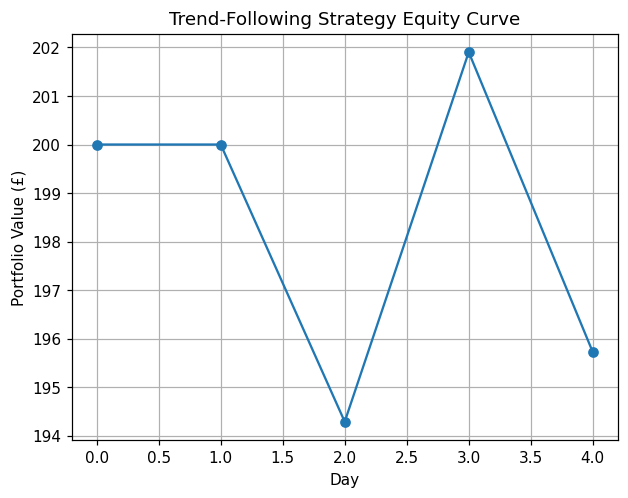

In [6]:
import matplotlib.pyplot as plt
import numpy as np 

plt.plot(capital_history, marker="o")
plt.title("Trend-Following Strategy Equity Curve")
plt.xlabel("Day")
plt.ylabel("Portfolio Value (£)")
plt.grid(True)
plt.show()

<a id="step-9"></a>

## Step 9 — Compare the toy strategy with buy-and-hold

Buy-and-hold purchases the asset at the first price and keeps it. Its value at a later price is initial capital multiplied by the ratio of that price to the initial price.

Both curves use the same starting capital and price observations. The comparison asks whether the trading rule improved on simply remaining invested over this small example.

The final `statistics.stdev()` printouts measure the dispersion of **portfolio-value levels**. They are learning diagnostics, not return volatility; the correct return-based volatility measure is introduced in Step 17B.


In [7]:
benchmark_history = []

for price in prices:
    benchmark_value = starting_capital * (price / prices[0])
    benchmark_history.append(benchmark_value)

benchmark_return = (
    benchmark_history[-1] - starting_capital
) / starting_capital

print("Benchmark history:", benchmark_history)
print("Benchmark return:", round(benchmark_return * 100, 2), "%")

Benchmark history: [200.0, 210.0, 204.0, 196.0, 202.0]
Benchmark return: 1.0 %


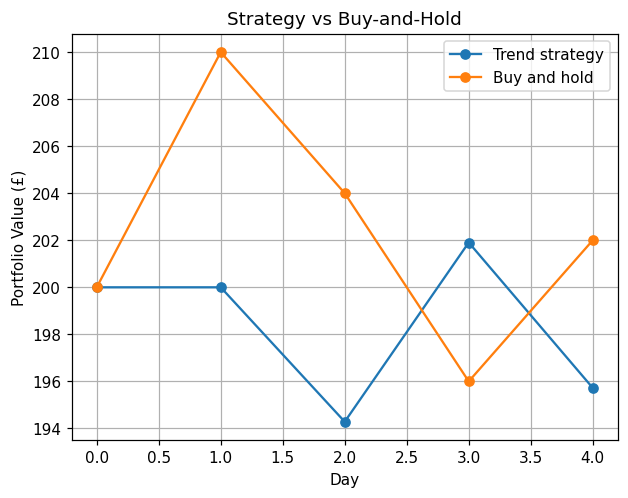

[200.0, 210.0, 204.0, 196.0, 202.0]
[200, 200.0, 194.28571428571428, 201.9047619047619, 195.7240038872692]
5.176871642217914
3.22064416739011


In [8]:


plt.plot(
    capital_history,
    marker="o",
    label="Trend strategy"
)

plt.plot(
    benchmark_history,
    marker="o",
    label="Buy and hold"
)

plt.title("Strategy vs Buy-and-Hold")
plt.xlabel("Day")
plt.ylabel("Portfolio Value (£)")
plt.grid(True)
plt.legend()
plt.show()

print(benchmark_history)
print(capital_history)
import statistics

print(statistics.stdev(benchmark_history))
print(statistics.stdev(capital_history))

<a id="step-10"></a>

## Step 10 — Download adjusted SPY prices

Download daily SPY prices from 1 January 2010 up to, but excluding, 1 January 2026. The code requests adjusted prices with `auto_adjust=True` and uses the `Close` column.

Adjusted-price returns provide a total-return-style proxy incorporating the data provider's corporate-action adjustments. They are not a record of executable trade prices. This cell replaces the earlier toy `prices` list with a dated price series, so the notebook should be run in order.

The loader first checks the matching CSV snapshot in `data/`. If it is absent, the adjusted-price request is downloaded and cached. Supplied snapshots freeze the inputs used for the saved results.


In [9]:
import yfinance as yf
from pathlib import Path

DATA_DIRECTORY = Path("data")
DATA_DIRECTORY.mkdir(exist_ok=True)


def load_adjusted_etf_data(ticker, start, end):
    """Reuse the input snapshot; download only when that file is absent."""
    cache_file = DATA_DIRECTORY / f"{ticker}_{start}_{end}.csv"
    if cache_file.exists():
        frame = pd.read_csv(cache_file, index_col="Date", parse_dates=["Date"])
    else:
        frame = yf.download(
            ticker,
            start=start,
            end=end,
            interval="1d",
            auto_adjust=True,
            progress=False,
            multi_level_index=False,
        )
        if frame.empty:
            raise ValueError(f"No price data returned for {ticker}.")
        frame.to_csv(cache_file, index_label="Date")
    if not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f"Invalid date index in {cache_file}.")
    return frame


import pandas as pd

data = load_adjusted_etf_data("SPY", "2010-01-01", "2026-01-01")
prices = data["Close"].dropna()

print(prices.head())
print("Number of prices:", len(prices))
print(data.head())
print(prices)


Date
2010-01-04    84.368965
2010-01-05    84.592270
2010-01-06    84.651871
2010-01-07    85.009232
2010-01-08    85.292084
Name: Close, dtype: float64
Number of prices: 4024
                Close       High        Low       Open     Volume
Date                                                             
2010-01-04  84.368965  84.413631  83.014059  83.654290  118944600
2010-01-05  84.592270  84.629495  84.011597  84.316826  111579900
2010-01-06  84.651871  84.860317  84.443424  84.510423  116074400
2010-01-07  85.009232  85.113455  84.257331  84.495556  131091100
2010-01-08  85.292084  85.329309  84.614634  84.785855  126402800
Date
2010-01-04     84.368965
2010-01-05     84.592270
2010-01-06     84.651871
2010-01-07     85.009232
2010-01-08     85.292084
                 ...    
2025-12-24    685.029480
2025-12-26    684.960022
2025-12-29    682.519043
2025-12-30    681.685547
2025-12-31    676.635010
Name: Close, Length: 4024, dtype: float64


<a id="step-11"></a>

## Step 11 — Calculate daily ETF returns

`pct_change(fill_method=None)` calculates the fractional change between consecutive adjusted closing prices. The first observation has no preceding price and is therefore missing; `dropna()` removes it.

No missing price is silently filled when calculating these returns.


In [10]:
daily_returns = prices.pct_change(fill_method=None)

print(daily_returns.head())

daily_returns = daily_returns.dropna()

print(daily_returns.head())
print("Number of returns:", len(daily_returns))

Date
2010-01-04         NaN
2010-01-05    0.002647
2010-01-06    0.000705
2010-01-07    0.004222
2010-01-08    0.003327
Name: Close, dtype: float64
Date
2010-01-05    0.002647
2010-01-06    0.000705
2010-01-07    0.004222
2010-01-08    0.003327
2010-01-11    0.001397
Name: Close, dtype: float64
Number of returns: 4023


<a id="step-12"></a>

## Step 12 — Calculate the 50-day and 200-day moving averages

The 50-day average represents a shorter price trend and the 200-day average a slower trend. For a window of $N$ observations:

$$
\mathrm{MA}_{N,t}=\frac{1}{N}\sum_{k=0}^{N-1}P_{t-k}.
$$

`rolling(window=N).mean()` moves this calculation forward one observation at a time. A complete window is required before an average becomes available. The example date below checks the two averages against an individual observation.


First valid 50-day averages:
Date
2010-03-16    83.072733
2010-03-17    83.128865
2010-03-18    83.179638
2010-03-19    83.220398
2010-03-22    83.263280
Name: Close, dtype: float64

First valid 200-day averages:
Date
2010-10-18    84.063489
2010-10-19    84.082357
2010-10-20    84.104412
2010-10-21    84.127151
2010-10-22    84.148933
Name: Close, dtype: float64


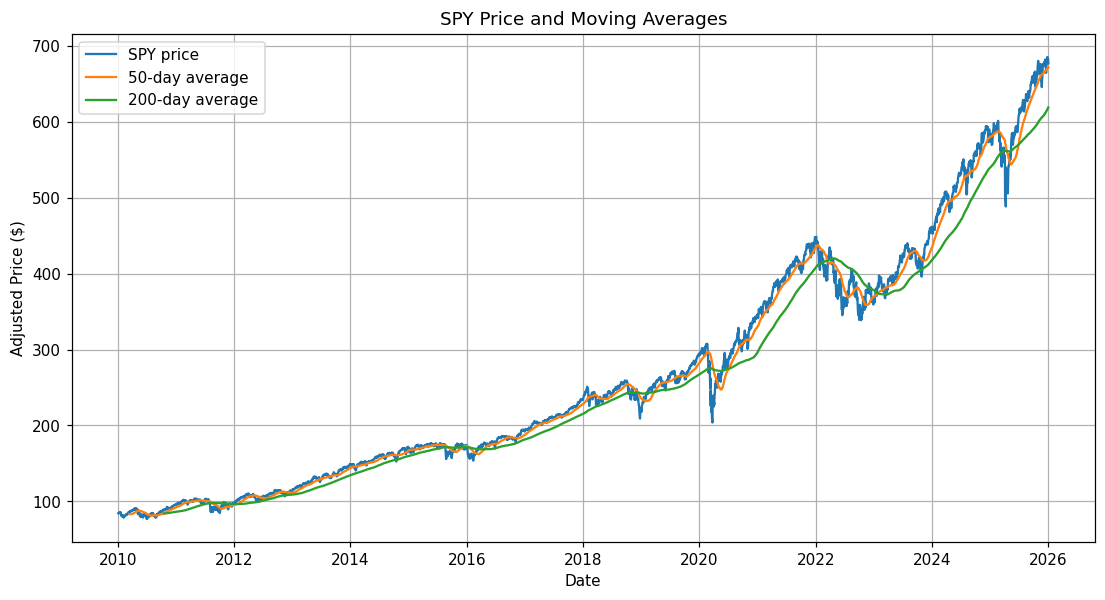

In [11]:
short_average = prices.rolling(window=50).mean()
long_average = prices.rolling(window=200).mean()
print("First valid 50-day averages:")
print(short_average.dropna().head())

print()

print("First valid 200-day averages:")
print(long_average.dropna().head())

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    prices.index,
    prices,
    label="SPY price"
)

plt.plot(
    short_average.index,
    short_average,
    label="50-day average"
)

plt.plot(
    long_average.index,
    long_average,
    label="200-day average"
)

plt.title("SPY Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Adjusted Price ($)")
plt.grid(True)
plt.legend()
plt.show()

In [12]:
date = "2010-10-18"

print("50-day average:", short_average.loc[date])
print("200-day average:", long_average.loc[date])

50-day average: 84.25799652099609
200-day average: 84.063489112854


<a id="step-13"></a>

## Step 13 — Convert moving averages into decisions

The decision is +1 when the 50-day average exceeds the 200-day average and −1 when it is below. A tie, or an unavailable moving average during warm-up, leaves the decision at zero.

These are same-day decisions, not yet the positions used to calculate returns. The following cells inspect one decision and count how frequently each decision occurs.


In [13]:
import pandas as pd

decision_positions = pd.Series(
    0,
    index=prices.index,
    dtype=int
)

decision_positions[short_average > long_average] = 1
decision_positions[short_average < long_average] = -1

In [14]:
date = "2010-10-18"

print("Date:", date)
print("SPY price:", prices.loc[date])
print("50-day average:", short_average.loc[date])
print("200-day average:", long_average.loc[date])
print("Decision position:", decision_positions.loc[date])

Date: 2010-10-18
SPY price: 89.31290435791016
50-day average: 84.25799652099609
200-day average: 84.063489112854
Decision position: 1


In [15]:
print(decision_positions.value_counts())

 1    3183
-1     642
 0     199
Name: count, dtype: int64


<a id="step-14"></a>

## Step 14 — Delay decisions by one trading day

A decision based on today's closing price cannot earn the return that has already occurred. The held position is yesterday's decision:

$$
s_t=d_{t-1}.
$$

`shift(1)` moves the decision down one dated row, and `fillna(0)` makes the initial unavailable position flat. Multiplying held positions by asset returns produces the gross strategy-return series.

This prevents same-day signal/return look-ahead in the daily model. Execution at the assumed price remains a backtest approximation; an explicit next-open execution model is not implemented.


In [16]:
held_positions = decision_positions.shift(1).fillna(0)

print(
    "Decision made on 2010-10-18:",
    decision_positions.loc["2010-10-18"]
)

print(
    "Position held on 2010-10-18:",
    held_positions.loc["2010-10-18"]
)

print(
    "Position held on 2010-10-19:",
    held_positions.loc["2010-10-19"]
)

Decision made on 2010-10-18: 1
Position held on 2010-10-18: 0.0
Position held on 2010-10-19: 1.0


In [17]:
asset_returns = prices.pct_change(fill_method=None).fillna(0)

strategy_returns = held_positions * asset_returns

<a id="step-15"></a>

## Step 15 — Compound the real-data equity curves

Both portfolios begin with a hypothetical US\$10,000. For each return series:

$$
V_t=V_0\prod_{j=1}^{t}(1+R_j).
$$

`cumprod()` retains every intermediate portfolio value. These preliminary curves include the trend model's warm-up period, during which it is flat while buy-and-hold is invested. Step 16 aligns the evaluation start.


Strategy final value: 17750.0
Strategy total return: 77.5 %
Buy-and-hold final value: 80199.52
Buy-and-hold total return: 702.0 %


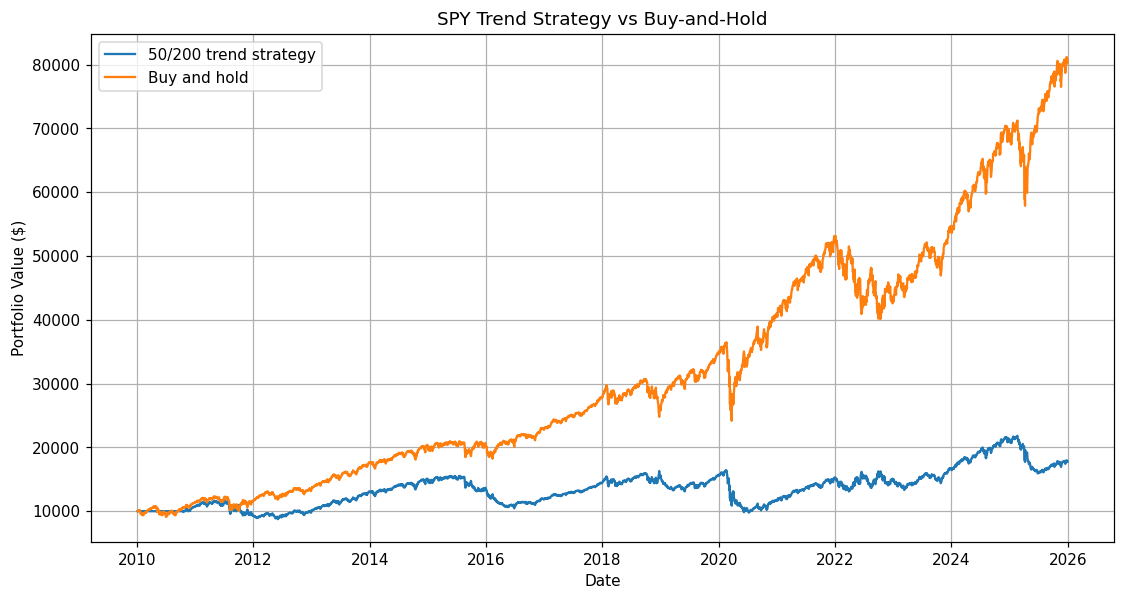

In [18]:
starting_capital = 10000

strategy_equity = starting_capital * (
    1 + strategy_returns
).cumprod()

buy_hold_equity = starting_capital * (
    1 + asset_returns
).cumprod()

strategy_total_return = (
    strategy_equity.iloc[-1] / starting_capital
) - 1

buy_hold_total_return = (
    buy_hold_equity.iloc[-1] / starting_capital
) - 1

print(
    "Strategy final value:",
    round(strategy_equity.iloc[-1], 2)
)

print(
    "Strategy total return:",
    round(strategy_total_return * 100, 2),
    "%"
)

print(
    "Buy-and-hold final value:",
    round(buy_hold_equity.iloc[-1], 2)
)

print(
    "Buy-and-hold total return:",
    round(buy_hold_total_return * 100, 2),
    "%"
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_equity.index,
    strategy_equity,
    label="50/200 trend strategy"
)

plt.plot(
    buy_hold_equity.index,
    buy_hold_equity,
    label="Buy and hold"
)

plt.title("SPY Trend Strategy vs Buy-and-Hold")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.grid(True)
plt.legend()
plt.show()


<a id="step-16"></a>

## Step 16 — Align the evaluation start

Both return series are restricted to dates when yesterday's 200-day moving average exists. They are then compounded from the same starting capital over the same dates.

`long_average.shift(1).notna()` is a Boolean mask: it marks which observations have sufficient past information to support the delayed signal.

As in the toy example, the final standard deviations of equity levels are diagnostic printouts. Use Step 17B for annualised return volatility.


In [19]:
evaluation_mask = long_average.shift(1).notna()

strategy_returns_fair = strategy_returns.loc[evaluation_mask]
buy_hold_returns_fair = asset_returns.loc[evaluation_mask]

print("Fair evaluation starts:", strategy_returns_fair.index[0])
print("Fair evaluation ends:", strategy_returns_fair.index[-1])

Fair evaluation starts: 2010-10-19 00:00:00
Fair evaluation ends: 2025-12-31 00:00:00


Fair strategy final value: 17750.0
Fair strategy total return: 77.5 %
Fair buy-and-hold final value: 75760.05
Fair buy-and-hold total return: 657.6 %


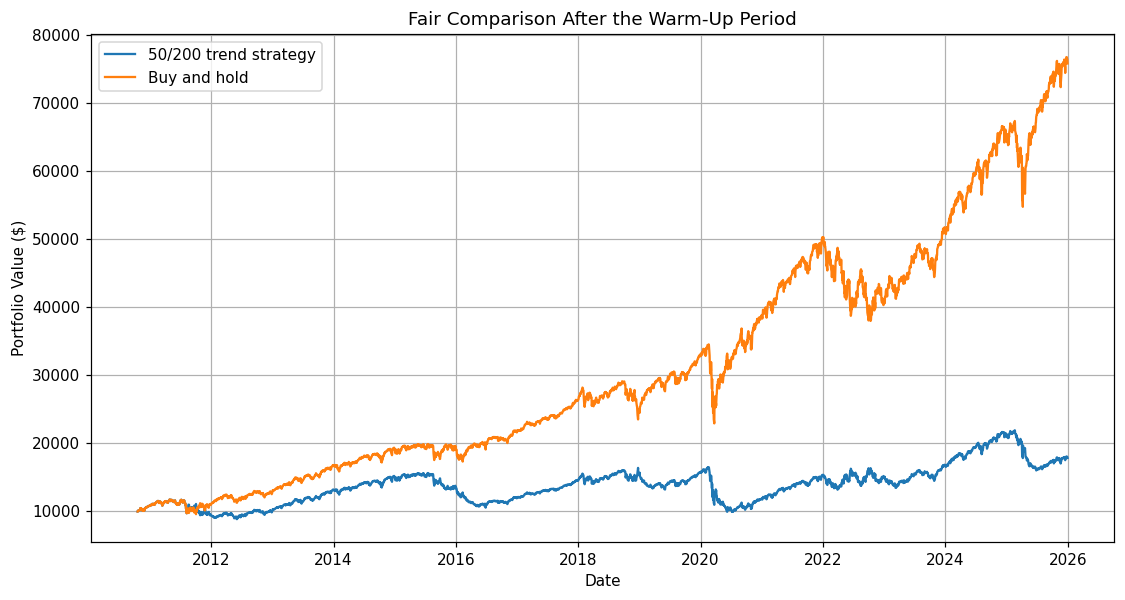

[200.0, 210.0, 204.0, 196.0, 202.0]
[200, 200.0, 194.28571428571428, 201.9047619047619, 195.7240038872692]
2703.822417556329
17121.420608376393


In [20]:
starting_capital = 10000

strategy_equity_fair = starting_capital * (
    1 + strategy_returns_fair
).cumprod()

buy_hold_equity_fair = starting_capital * (
    1 + buy_hold_returns_fair
).cumprod()

strategy_return_fair = (
    strategy_equity_fair.iloc[-1] / starting_capital
) - 1

buy_hold_return_fair = (
    buy_hold_equity_fair.iloc[-1] / starting_capital
) - 1

print(
    "Fair strategy final value:",
    round(strategy_equity_fair.iloc[-1], 2)
)

print(
    "Fair strategy total return:",
    round(strategy_return_fair * 100, 2),
    "%"
)

print(
    "Fair buy-and-hold final value:",
    round(buy_hold_equity_fair.iloc[-1], 2)
)

print(
    "Fair buy-and-hold total return:",
    round(buy_hold_return_fair * 100, 2),
    "%"
)

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_equity_fair.index,
    strategy_equity_fair,
    label="50/200 trend strategy"
)

plt.plot(
    buy_hold_equity_fair.index,
    buy_hold_equity_fair,
    label="Buy and hold"
)

plt.title("Fair Comparison After the Warm-Up Period")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.grid(True)
plt.legend()
plt.show()


print(benchmark_history)
print(capital_history)
import statistics

print(statistics.stdev(strategy_equity_fair))
print(statistics.stdev(buy_hold_equity_fair))


<a id="step-17"></a>

## Step 17 — Baseline performance metrics

<a id="step-17a"></a>

### Step 17A — Compound annual growth rate

The annualised return, or CAGR, answers:

What constant yearly return would transform \$10,000 into the final value over this period?

The formula is:
Compound Annual Growth Rate (CAGR)

$$
\mathrm{CAGR}
=
\left(
\frac{V_T}{V_0}
\right)^{\frac{1}{T}}
-1
$$

where:

- $V_0$ is the initial portfolio value.
- $V_T$ is the final portfolio value.
- $T$ is the investment duration in years.

The implementation uses $T=n/252$, where $n$ is the number of trading observations. CAGR is a compounded growth rate and differs from $252\overline{R}$, the annualised arithmetic mean.


In [21]:
trading_days = len(strategy_returns_fair)
years = trading_days / 252

strategy_annual_return = (
    strategy_equity_fair.iloc[-1] / starting_capital
) ** (1 / years) - 1

buy_hold_annual_return = (
    buy_hold_equity_fair.iloc[-1] / starting_capital
) ** (1 / years) - 1

print("Trading days:", trading_days)
print("Approximate years:", round(years, 2))

print(
    "Strategy annualized return:",
    round(strategy_annual_return * 100, 2),
    "%"
)

print(
    "Buy-and-hold annualized return:",
    round(buy_hold_annual_return * 100, 2),
    "%"
)

Trading days: 3824
Approximate years: 15.17
Strategy annualized return: 3.85 %
Buy-and-hold annualized return: 14.28 %


<a id="step-17b"></a>

### Step 17B — Annualised return volatility

Daily volatility is the sample standard deviation of daily returns:

$$
\sigma_{\mathrm{daily}}
=
\sqrt{
\frac{1}{n-1}
\sum_{t=1}^{n}
\left(R_t-\bar{R}\right)^2
}
$$

where:

- $R_t$ is the return on day $t$.
- $\bar{R}$ is the mean daily return.
- $n$ is the number of daily returns.
- $\sigma_{\mathrm{daily}}$ is the daily volatility.

Daily volatility is annualised using:

$$
\sigma_{\mathrm{annual}}
=
\sigma_{\mathrm{daily}}\sqrt{252}
$$

where $252$ is the approximate number of trading days in one year.

To express annualised volatility as a percentage:

$$
\sigma_{\mathrm{annual,\%}}
=
\sigma_{\mathrm{daily}}\sqrt{252}\times 100
$$

The square-root-of-252 scaling is the notebook's annualisation convention. It is not a correction for serial dependence or changing volatility regimes.


In [22]:
strategy_daily_volatility = strategy_returns_fair.std()

buy_hold_daily_volatility = buy_hold_returns_fair.std()

strategy_annual_volatility = (
    strategy_daily_volatility * (252 ** 0.5)
)

buy_hold_annual_volatility = (
    buy_hold_daily_volatility * (252 ** 0.5)
)

print(
    "Strategy annualized volatility:",
    round(strategy_annual_volatility * 100, 2),
    "%"
)

print(
    "Buy-and-hold annualized volatility:",
    round(buy_hold_annual_volatility * 100, 2),
    "%"
)

Strategy annualized volatility: 17.13 %
Buy-and-hold annualized volatility: 17.1 %


<a id="step-17c"></a>

### Step 17C — Preliminary zero-rate Sharpe measure

The Sharpe ratio compares return above a risk-free alternative with the variability of that excess return. At this introductory stage, the code assumes a zero risk-free rate and calculates:

$$
S_0=\sqrt{252}\frac{\overline{R}}{s_R}
=\frac{252\overline{R}}{s_R\sqrt{252}}.
$$

The saved output labels this quantity `Sharpe ratio`. It is a preliminary zero-rate measure. Step 25B.1 introduces a dated risk-free series and calculates $\sqrt{252}\,\overline{(R-r_f)}/s_{R-r_f}$ for the formal comparison.

The ratio is dimensionless. Its numerator uses the arithmetic mean return, not CAGR.


In [23]:
risk_free_rate = 0.0

strategy_mean_return_annual = (
    strategy_returns_fair.mean() * 252
)

buy_hold_mean_return_annual = (
    buy_hold_returns_fair.mean() * 252
)

strategy_sharpe = (
    strategy_mean_return_annual - risk_free_rate
) / strategy_annual_volatility

buy_hold_sharpe = (
    buy_hold_mean_return_annual - risk_free_rate
) / buy_hold_annual_volatility

print(
    "Strategy annualized mean return:",
    round(strategy_mean_return_annual * 100, 2),
    "%"
)

print(
    "Buy-and-hold annualized mean return:",
    round(buy_hold_mean_return_annual * 100, 2),
    "%"
)

print(
    "Strategy Sharpe ratio:",
    round(strategy_sharpe, 3)
)

print(
    "Buy-and-hold Sharpe ratio:",
    round(buy_hold_sharpe, 3)
)

Strategy annualized mean return: 5.25 %
Buy-and-hold annualized mean return: 14.81 %
Strategy Sharpe ratio: 0.307
Buy-and-hold Sharpe ratio: 0.866


<a id="step-17d"></a>

### Step 17D — Maximum drawdown

Drawdown measures how far a portfolio has fallen from its previous highest value.

Suppose the portfolio values are:

`$100 → $120 → $90 → $105`

The highest value reached was $\$120$. When the portfolio falls to $\$90$:

$$
\text{Drawdown}
=
\frac{90}{120}-1
=
-0.25
=
-25\%
$$

Even after recovering to $\$105$, the portfolio remains:

$$
\frac{105}{120}-1
=
-0.125
=
-12.5\%
$$

below its previous peak.

#### Running Peak

Let $V_t$ represent the portfolio value at time $t$. The running peak is:

$$
H_t
=
\max_{u\leq t} V_u
$$

where $H_t$ is the highest portfolio value observed up to and including time $t$.

#### Drawdown

The drawdown at time $t$ is:

$$
D_t
=
\frac{V_t}{H_t}-1
$$

A drawdown of $0$ means the portfolio is currently at its highest value. A negative drawdown means the portfolio is below its previous peak.

#### Maximum Drawdown

The signed maximum drawdown is the most negative value of the drawdown series:

$$
\mathrm{MDD}_{\mathrm{signed}}
=
\min_t(D_t)
$$

It is often reported as a positive loss magnitude:

$$
\mathrm{MDD}
=
-\min_t(D_t)
$$

Throughout the final comparison, maximum drawdown is reported as the signed negative value. A result of −8% is a shallower observed loss than −20%.


Strategy maximum drawdown: -40.12 %
Buy-and-hold maximum drawdown: -33.72 %


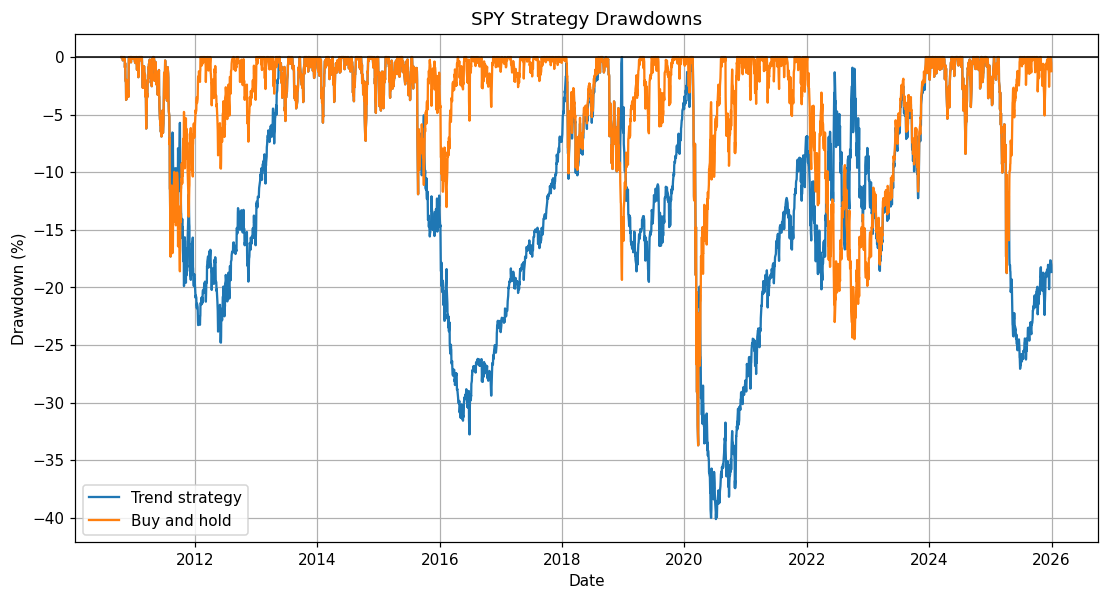

In [24]:
strategy_running_peak = strategy_equity_fair.cummax()
buy_hold_running_peak = buy_hold_equity_fair.cummax()

strategy_drawdown = (
    strategy_equity_fair / strategy_running_peak
) - 1

buy_hold_drawdown = (
    buy_hold_equity_fair / buy_hold_running_peak
) - 1

strategy_max_drawdown = strategy_drawdown.min()
buy_hold_max_drawdown = buy_hold_drawdown.min()

print(
    "Strategy maximum drawdown:",
    round(strategy_max_drawdown * 100, 2),
    "%"
)

print(
    "Buy-and-hold maximum drawdown:",
    round(buy_hold_max_drawdown * 100, 2),
    "%"
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_drawdown.index,
    strategy_drawdown * 100,
    label="Trend strategy"
)

plt.plot(
    buy_hold_drawdown.index,
    buy_hold_drawdown * 100,
    label="Buy and hold"
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title("SPY Strategy Drawdowns")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(True)
plt.legend()
plt.show()


<a id="step-17e"></a>

### Step 17E — Assemble the baseline metrics

Combine the strategy and SPY buy-and-hold results in one table. The table distinguishes compounded annual growth, annualised arithmetic mean return, volatility, the preliminary zero-rate Sharpe measure and maximum drawdown.

These are gross baseline results. Transaction costs are added in Step 18.


In [25]:
baseline_results = pd.DataFrame({
    "Metric": [
        "Total return",
        "CAGR",
        "Annualized mean return",
        "Annualized volatility",
        "Sharpe ratio (risk-free rate = 0)",
        "Maximum drawdown"
    ],

    "Trend strategy": [
        f"{strategy_return_fair:.2%}",
        f"{strategy_annual_return:.2%}",
        f"{strategy_mean_return_annual:.2%}",
        f"{strategy_annual_volatility:.2%}",
        f"{strategy_sharpe:.3f}",
        f"{strategy_max_drawdown:.2%}"
    ],

    "Buy and hold": [
        f"{buy_hold_return_fair:.2%}",
        f"{buy_hold_annual_return:.2%}",
        f"{buy_hold_mean_return_annual:.2%}",
        f"{buy_hold_annual_volatility:.2%}",
        f"{buy_hold_sharpe:.3f}",
        f"{buy_hold_max_drawdown:.2%}"
    ]
})

display(baseline_results)

,Metric,Trend strategy,Buy and hold
0,Total return,77.50%,657.60%
1,CAGR,3.85%,14.28%
2,Annualized mean return,5.25%,14.81%
3,Annualized volatility,17.13%,17.10%
4,Sharpe ratio (risk-free rate = 0),0.307,0.866
5,Maximum drawdown,-40.12%,-33.72%


<a id="step-18"></a>

## Step 18 — Turnover and transaction costs

<a id="step-18a"></a>

### Step 18A — Measure position turnover

Turnover measures how much the portfolio position changes from one trading day to the next:

$$
\mathrm{Turnover}_t
=
\left|s_t-s_{t-1}\right|
$$

where:

- $s_t$ is the new position at time $t$.
- $s_{t-1}$ is the position held previously.
- $\left|\cdot\right|$ represents the absolute value.

#### Examples

| Previous position | New position | Turnover | Meaning |
|---:|---:|---:|---|
| $+1$ | $+1$ | $0$ | Remain long |
| $0$ | $+1$ | $1$ | Enter a long position |
| $+1$ | $0$ | $1$ | Close a long position |
| $+1$ | $-1$ | $2$ | Close the long position and enter a short position |
| $-1$ | $+1$ | $2$ | Close the short position and enter a long position |

A direct switch from $+1$ to $-1$ has turnover:

$$
\left|-1-(+1)\right|
=
|-2|
=
2
$$

This represents two actions:

1. Close the existing long position.
2. Open a new short position.


In [26]:
held_positions_fair = held_positions.loc[evaluation_mask]

previous_positions = (
    held_positions_fair.shift(1).fillna(0)
)

turnover = (
    held_positions_fair - previous_positions
).abs()

rebalancing_days = (turnover > 0).sum()
total_turnover = turnover.sum()

print("Rebalancing days:", rebalancing_days)
print("Total turnover:", total_turnover)

position_changes = pd.DataFrame({
    "Previous position": previous_positions,
    "New position": held_positions_fair,
    "Turnover": turnover
})

print(
    position_changes[turnover > 0].head(10)
)

Rebalancing days: 15
Total turnover: 29.0
            Previous position  New position  Turnover
Date                                                 
2010-10-19                0.0           1.0       1.0
2011-08-18                1.0          -1.0       2.0
2012-01-24               -1.0           1.0       2.0
2015-09-04                1.0          -1.0       2.0
2015-12-10               -1.0           1.0       2.0
2016-01-19                1.0          -1.0       2.0
2016-04-21               -1.0           1.0       2.0
2018-12-13                1.0          -1.0       2.0
2019-03-27               -1.0           1.0       2.0
2020-04-01                1.0          -1.0       2.0


<a id="step-18b"></a>

### Step 18B — Deduct transaction costs

We assume a transaction cost of 5 basis points for every unit of turnover:

$$
c=5\text{ basis points}=0.05\%=0.0005
$$

The transaction cost on date $t$ is:

$$
C_t
=
c\times\mathrm{Turnover}_t
$$

where:

- $C_t$ is the transaction-cost rate on date $t$.
- $c$ is the cost per unit traded.
- $\mathrm{Turnover}_t$ is the amount by which the position changes.

#### Examples

- No position change:

$$
C_t
=
0.0005\times0
=
0
$$

- Enter a long position:

$$
C_t
=
0.0005\times1
=
0.0005
=
0.05\%
$$

- Switch directly from long to short:

$$
C_t
=
0.0005\times2
=
0.001
=
0.10\%
$$

The transaction costs are deducted from the gross strategy return:

$$
R_t^{\mathrm{net}}
=
R_t^{\mathrm{gross}}-C_t
$$

where:

- $R_t^{\mathrm{gross}}$ is the strategy return before transaction costs.
- $R_t^{\mathrm{net}}$ is the strategy return after transaction costs.

For total turnover of $29$, the sum of the transaction-cost rates is:

$$
\sum_t C_t
=
c\sum_t\mathrm{Turnover}_t
$$

$$
\sum_t C_t
=
0.0005\times29
=
0.0145
=
1.45\%
$$

The 1.45% figure is the sum of daily cost rates, not an exact percentage-point reduction in compounded total return. The latter depends on the daily net-return path.


In [27]:
cost_per_unit = 0.0005

In [28]:
transaction_costs = turnover * cost_per_unit

Sum of transaction-cost rates: 1.45 %
Gross final value: 17750.0
Net final value: 17495.49
Net total return: 74.95 %
Net CAGR: 3.75 %


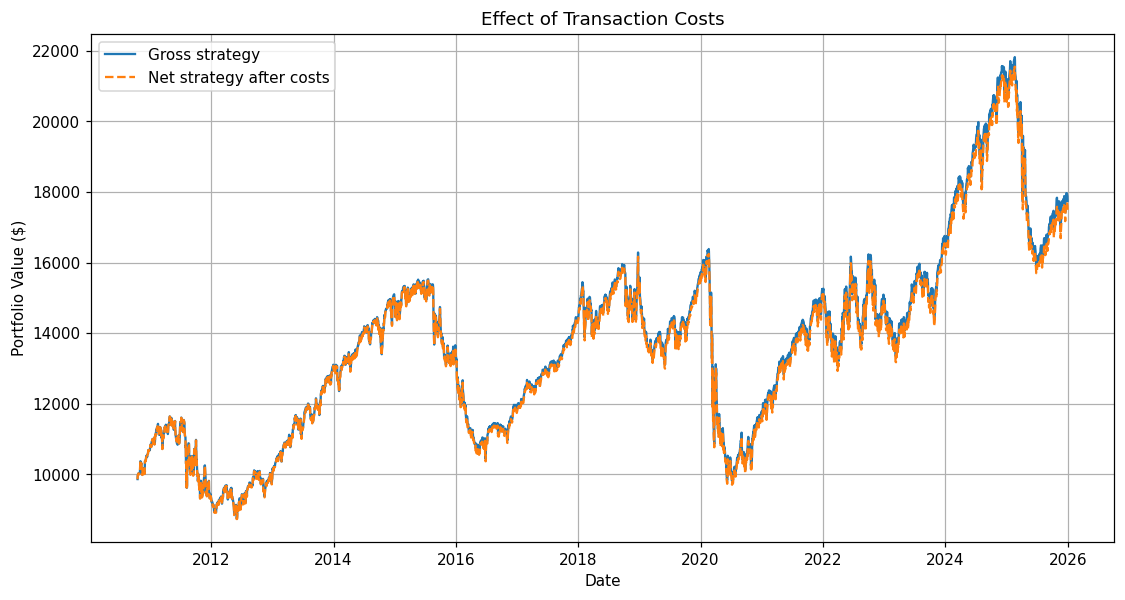

In [29]:
strategy_returns_net = (
    strategy_returns_fair - transaction_costs
)

strategy_equity_net = starting_capital * (
    1 + strategy_returns_net
).cumprod()

net_final_value = strategy_equity_net.iloc[-1]

net_total_return = (
    net_final_value / starting_capital
) - 1

net_cagr = (
    net_final_value / starting_capital
) ** (1 / years) - 1

total_cost_rate = transaction_costs.sum()

print(
    "Sum of transaction-cost rates:",
    round(total_cost_rate * 100, 2),
    "%"
)

print(
    "Gross final value:",
    round(strategy_equity_fair.iloc[-1], 2)
)

print(
    "Net final value:",
    round(net_final_value, 2)
)

print(
    "Net total return:",
    round(net_total_return * 100, 2),
    "%"
)

print(
    "Net CAGR:",
    round(net_cagr * 100, 2),
    "%"
)

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_equity_fair.index,
    strategy_equity_fair,
    label="Gross strategy"
)

plt.plot(
    strategy_equity_net.index,
    strategy_equity_net,
    label="Net strategy after costs",
    linestyle="--"
)

plt.title("Effect of Transaction Costs")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.grid(True)
plt.legend()
plt.show()

<a id="step-18c"></a>

### Step 18C — Recalculate performance after costs

Apply the same mean-return and volatility calculations to `strategy_returns_net`. Costs affect the return series before compounding, rather than being subtracted from final wealth as one lump sum.


In [30]:
net_mean_return_annual = (
    strategy_returns_net.mean() * 252
)

net_annual_volatility = (
    strategy_returns_net.std() * (252 ** 0.5)
)

#### Calculate the net return-to-volatility ratio

The calculation still assumes a zero risk-free rate. It measures the effect of trading costs on the preliminary Sharpe measure; it is not yet the historical excess-return Sharpe used later.


In [31]:
net_sharpe = (
    net_mean_return_annual - risk_free_rate
) / net_annual_volatility

#### Calculate net maximum drawdown

Compound net daily returns, track their running peak, and find the largest peak-to-trough decline. The notebook reports drawdowns with a negative sign.


In [32]:
net_running_peak = strategy_equity_net.cummax()

net_drawdown = (
    strategy_equity_net / net_running_peak
) - 1

net_max_drawdown = net_drawdown.min()

#### Compare gross and net performance

Place the before-cost and after-cost metrics together. A difference between them comes from applying the transaction-cost assumption to the same trading decisions.


In [33]:
gross_net_results = pd.DataFrame({
    "Metric": [
        "Total return",
        "CAGR",
        "Annualized mean return",
        "Annualized volatility",
        "Sharpe ratio",
        "Maximum drawdown"
    ],

    "Gross strategy": [
        f"{strategy_return_fair:.2%}",
        f"{strategy_annual_return:.2%}",
        f"{strategy_mean_return_annual:.2%}",
        f"{strategy_annual_volatility:.2%}",
        f"{strategy_sharpe:.3f}",
        f"{strategy_max_drawdown:.2%}"
    ],

    "Net strategy": [
        f"{net_total_return:.2%}",
        f"{net_cagr:.2%}",
        f"{net_mean_return_annual:.2%}",
        f"{net_annual_volatility:.2%}",
        f"{net_sharpe:.3f}",
        f"{net_max_drawdown:.2%}"
    ]
})

display(gross_net_results)

,Metric,Gross strategy,Net strategy
0,Total return,77.50%,74.95%
1,CAGR,3.85%,3.75%
2,Annualized mean return,5.25%,5.16%
3,Annualized volatility,17.13%,17.12%
4,Sharpe ratio,0.307,0.301
5,Maximum drawdown,-40.12%,-40.24%


<a id="step-18d"></a>

### Step 18D — Examine transaction-cost sensitivity

Recalculate the baseline strategy using 0, 1, 5, 10 and 20 basis points per unit of turnover. The signals stay fixed, allowing the effect of the cost assumption to be examined directly.

This is a sensitivity check for the early baseline. It does not constitute a separate cost sweep for the final enhanced model.


,Cost (bps),Final value ($),Total return (%),CAGR (%),Sharpe ratio,Maximum drawdown (%)
0,0,17750.00,77.50,3.85,0.307,-40.12
1,1,17698.82,76.99,3.83,0.306,-40.15
2,5,17495.49,74.95,3.75,0.301,-40.24
3,10,17244.39,72.44,3.66,0.296,-40.36
4,20,16752.24,67.52,3.46,0.284,-40.59


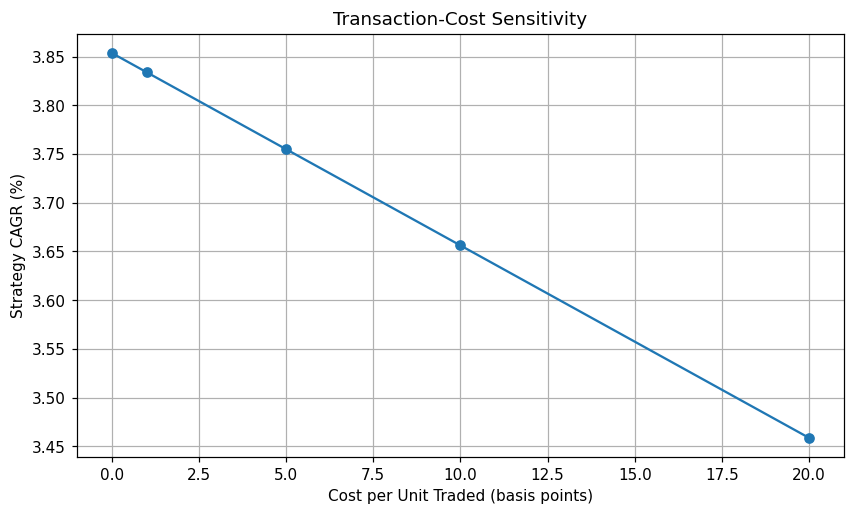

In [34]:
cost_levels_bps = [0, 1, 5, 10, 20]

sensitivity_results = []

for cost_bps in cost_levels_bps:
    cost_rate = cost_bps / 10000

    costs = turnover * cost_rate

    returns_after_costs = (
        strategy_returns_fair - costs
    )

    equity_after_costs = starting_capital * (
        1 + returns_after_costs
    ).cumprod()

    final_value = equity_after_costs.iloc[-1]

    total_return_after_costs = (
        final_value / starting_capital
    ) - 1

    cagr_after_costs = (
        final_value / starting_capital
    ) ** (1 / years) - 1

    annual_mean_after_costs = (
        returns_after_costs.mean() * 252
    )

    annual_volatility_after_costs = (
        returns_after_costs.std() * (252 ** 0.5)
    )

    sharpe_after_costs = (
        annual_mean_after_costs - risk_free_rate
    ) / annual_volatility_after_costs

    running_peak = equity_after_costs.cummax()

    drawdown = (
        equity_after_costs / running_peak
    ) - 1

    maximum_drawdown = drawdown.min()

    sensitivity_results.append({
        "Cost (bps)": cost_bps,
        "Final value": final_value,
        "Total return": total_return_after_costs,
        "CAGR": cagr_after_costs,
        "Sharpe ratio": sharpe_after_costs,
        "Maximum drawdown": maximum_drawdown
    })

cost_sensitivity = pd.DataFrame(
    sensitivity_results
)

cost_sensitivity_display = pd.DataFrame({
    "Cost (bps)": cost_sensitivity["Cost (bps)"],

    "Final value ($)": (
        cost_sensitivity["Final value"]
    ).round(2),

    "Total return (%)": (
        cost_sensitivity["Total return"] * 100
    ).round(2),

    "CAGR (%)": (
        cost_sensitivity["CAGR"] * 100
    ).round(2),

    "Sharpe ratio": (
        cost_sensitivity["Sharpe ratio"]
    ).round(3),

    "Maximum drawdown (%)": (
        cost_sensitivity["Maximum drawdown"] * 100
    ).round(2)
})

display(cost_sensitivity_display)
plt.figure(figsize=(9, 5))

plt.plot(
    cost_sensitivity["Cost (bps)"],
    cost_sensitivity["CAGR"] * 100,
    marker="o"
)

plt.title("Transaction-Cost Sensitivity")
plt.xlabel("Cost per Unit Traded (basis points)")
plt.ylabel("Strategy CAGR (%)")
plt.grid(True)
plt.show()

<a id="step-19"></a>

## Step 19 — Chronological evaluation

<a id="step-19a"></a>

### Step 19A — Separate development and test dates

Development observations occur before 1 January 2021; test observations occur on or after that date, through the end of 2025. The effective start follows the moving-average warm-up, rather than the first raw price date.

Here, “development” means examining rules and parameters. The strategy is rule-based and does not train a neural network. A chronological split preserves the order in which information would become available.

The intended discipline is to choose rules using development data and assess them on later data. Because later project stages were built after earlier test results had been inspected, the final experiment is described as **pseudo-out-of-sample**, not as an untouched holdout.

The baseline strategy series includes the five-basis-point transaction-cost assumption.


In [35]:
split_date = pd.Timestamp("2021-01-01")

train_strategy_returns = strategy_returns_net.loc[
    strategy_returns_net.index < split_date
]

test_strategy_returns = strategy_returns_net.loc[
    strategy_returns_net.index >= split_date
]

train_buy_hold_returns = buy_hold_returns_fair.loc[
    buy_hold_returns_fair.index < split_date
]

test_buy_hold_returns = buy_hold_returns_fair.loc[
    buy_hold_returns_fair.index >= split_date
]


print(
    "Development period:",
    train_strategy_returns.index[0].date(),
    "to",
    train_strategy_returns.index[-1].date()
)

print(
    "Test period:",
    test_strategy_returns.index[0].date(),
    "to",
    test_strategy_returns.index[-1].date()
)

print("Development observations:", len(train_strategy_returns))
print("Test observations:", len(test_strategy_returns))

print(
    "All observations accounted for:",
    len(train_strategy_returns) + len(test_strategy_returns)
    == len(strategy_returns_net)
)

Development period: 2010-10-19 to 2020-12-31
Test period: 2021-01-04 to 2025-12-31
Development observations: 2569
Test observations: 1255
All observations accounted for: True


<a id="step-19b"></a>

### Step 19B — Compare development and test performance

The reusable `calculate_metrics()` function converts one daily-return series into a consistent set of statistics. Apply it to the development strategy, development buy-and-hold, test strategy and test buy-and-hold series.

At this stage, its `Sharpe ratio` column still assumes a zero risk-free rate. The final corrected tables in Step 25B.1 should be used when citing the project's risk-adjusted results.


In [36]:
risk_free_rate = 0.0


def calculate_metrics(returns):

    number_of_days = len(returns)
    number_of_years = number_of_days / 252

    equity_curve = (1 + returns).cumprod()
    final_growth = equity_curve.iloc[-1]

    total_return = final_growth - 1

    cagr = (
        final_growth ** (1 / number_of_years)
        - 1
    )

    annualized_mean_return = returns.mean() * 252

    annualized_volatility = (
        returns.std() * np.sqrt(252)
    )

    sharpe_ratio = (
        annualized_mean_return - risk_free_rate
    ) / annualized_volatility

    running_peak = equity_curve.cummax().clip(lower=1.0)

    drawdowns = (
        equity_curve / running_peak
        - 1
    )

    maximum_drawdown = drawdowns.min()

    return {
        "Total return (%)": total_return * 100,
        "CAGR (%)": cagr * 100,
        "Annualized mean return (%)": annualized_mean_return * 100,
        "Annualized volatility (%)": annualized_volatility * 100,
        "Sharpe ratio": sharpe_ratio,
        "Maximum drawdown (%)": maximum_drawdown * 100
    }

development_results = pd.DataFrame({
    "Trend strategy": calculate_metrics(
        train_strategy_returns
    ),
    "Buy and hold": calculate_metrics(
        train_buy_hold_returns
    )
})


test_results = pd.DataFrame({
    "Trend strategy": calculate_metrics(
        test_strategy_returns
    ),
    "Buy and hold": calculate_metrics(
        test_buy_hold_returns
    )
})


print("DEVELOPMENT PERIOD RESULTS")
display(development_results.round(3))

print("TEST PERIOD RESULTS")
display(test_results.round(3))

DEVELOPMENT PERIOD RESULTS


,Trend strategy,Buy and hold
Total return (%),16.653,287.742
CAGR (%),1.522,14.217
Annualized mean return (%),2.985,14.766
Annualized volatility (%),17.120,17.100
Sharpe ratio,0.174,0.864
Maximum drawdown (%),-40.241,-33.717


TEST PERIOD RESULTS


,Trend strategy,Buy and hold
Total return (%),49.979,95.388
CAGR (%),8.479,14.396
Annualized mean return (%),9.603,14.914
Annualized volatility (%),17.132,17.116
Sharpe ratio,0.561,0.871
Maximum drawdown (%),-27.146,-24.496


<a id="step-19c"></a>

### Step 19C — Plot the test-period equity curves

Rebase each test-period return series to a hypothetical US\$10,000. The chart shows the later evaluation period separately, rather than carrying forward the development period's terminal wealth.

This rebasing changes the display scale; it does not establish that the strategy was actually deployed in 2021.


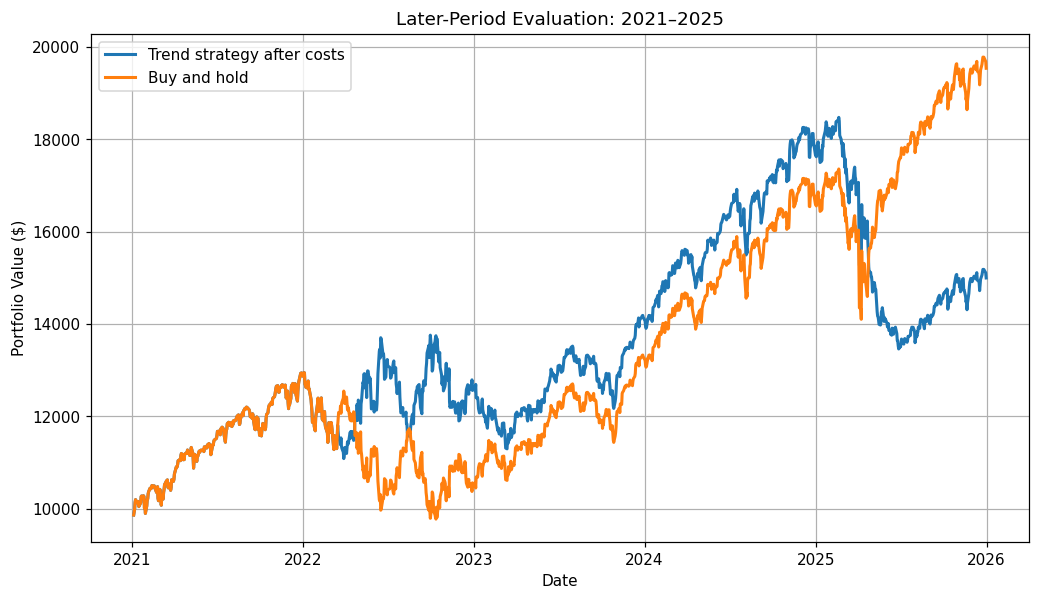

In [37]:
test_starting_capital = 10000

test_strategy_equity = (
    test_starting_capital
    * (1 + test_strategy_returns).cumprod()
)

test_buy_hold_equity = (
    test_starting_capital
    * (1 + test_buy_hold_returns).cumprod()
)


plt.figure(figsize=(11, 6))

plt.plot(
    test_strategy_equity,
    label="Trend strategy after costs",
    linewidth=2
)

plt.plot(
    test_buy_hold_equity,
    label="Buy and hold",
    linewidth=2
)

plt.title("Later-Period Evaluation: 2021–2025")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(True)
plt.show()

<a id="step-20"></a>

## Step 20 — Parameter robustness

<a id="step-20a"></a>

### Step 20A — Define the moving-average parameter grid

The grid uses short windows of 20, 50, 75 and 100 trading days, and long windows of 100, 150, 200, 250 and 300 days. Keeping only pairs where the short window is smaller than the long window produces 19 combinations.

The purpose is to inspect neighbouring parameter choices on development data. A broad region of acceptable results is more informative than one isolated winner, although it does not prove that performance will persist.

The later candidate comparison retains three named alternatives for inspection. Seeing their test results is part of the project's research history and does not create an untouched final holdout.


In [38]:
short_windows = [20, 50, 75, 100]
long_windows = [100, 150, 200, 250, 300]

parameter_pairs = []

for short_window in short_windows:

    for long_window in long_windows:

        if short_window < long_window:

            parameter_pairs.append(
                (short_window, long_window)
            )


print("Number of valid combinations:", len(parameter_pairs))
print(parameter_pairs)

Number of valid combinations: 19
[(20, 100), (20, 150), (20, 200), (20, 250), (20, 300), (50, 100), (50, 150), (50, 200), (50, 250), (50, 300), (75, 100), (75, 150), (75, 200), (75, 250), (75, 300), (100, 150), (100, 200), (100, 250), (100, 300)]


<a id="step-20b"></a>

### Step 20B — Use a common evaluation period

There is an important fairness problem:

A 20/100 strategy becomes available after approximately 100 prices.
A 20/300 strategy needs approximately 300 prices.

If each strategy starts as soon as it becomes available, they experience different market periods. We could not fairly compare their results.

Therefore, every combination will begin only when the longest moving average—300 days—is available.


In [39]:
maximum_long_window = max(long_windows)

maximum_long_average = prices.rolling(
    window=maximum_long_window
).mean()


common_development_mask = (
    maximum_long_average.shift(1).notna()
    & (prices.index < split_date)
)


common_development_dates = prices.index[
    common_development_mask
]


print(
    "Common development period:",
    common_development_dates[0].date(),
    "to",
    common_development_dates[-1].date()
)

print(
    "Number of common development observations:",
    len(common_development_dates)
)

Common development period: 2011-03-14 to 2020-12-31
Number of common development observations: 2469


<a id="step-20c"></a>

### Step 20C — Backtest one moving-average pair

The function accepts a short window and a long window. It builds moving averages, converts them into delayed positions, calculates returns and turnover, deducts costs and reports performance over the common development dates.


In [40]:
cost_per_unit = 0.0005


def backtest_moving_average_pair(
    short_window,
    long_window
):

    # 1. Calculate this pair's moving averages
    short_average_pair = prices.rolling(
        window=short_window
    ).mean()

    long_average_pair = prices.rolling(
        window=long_window
    ).mean()


    # 2. Create the decisions
    decision_positions_pair = pd.Series(
        0.0,
        index=prices.index
    )

    decision_positions_pair.loc[
        short_average_pair > long_average_pair
    ] = 1.0

    decision_positions_pair.loc[
        short_average_pair < long_average_pair
    ] = -1.0


    # 3. Shift decisions to prevent look-ahead
    held_positions_pair = (
        decision_positions_pair.shift(1).fillna(0.0)
    )


    # 4. Keep only the common development dates
    common_positions_pair = held_positions_pair.loc[
        common_development_dates
    ]

    common_asset_returns = asset_returns.loc[
        common_development_dates
    ]


    # 5. Calculate gross strategy returns
    gross_returns_pair = (
        common_positions_pair
        * common_asset_returns
    )


    # 6. Calculate turnover
    previous_positions_pair = (
        common_positions_pair.shift(1).fillna(0.0)
    )

    turnover_pair = (
        common_positions_pair
        - previous_positions_pair
    ).abs()


    # 7. Deduct transaction costs
    transaction_costs_pair = (
        turnover_pair * cost_per_unit
    )

    net_returns_pair = (
        gross_returns_pair
        - transaction_costs_pair
    )


    # 8. Calculate and return the metrics
    pair_metrics = calculate_metrics(
        net_returns_pair
    )

    return pair_metrics

#### Check the function with the 50/200 baseline

Run the familiar 50/200 pair through the reusable function. This makes the function easier to inspect before it is applied to all 19 combinations.


In [41]:
example_pair_results = (
    backtest_moving_average_pair(50, 200)
)

display(
    pd.Series(
        example_pair_results,
        name="50/200 development results"
    ).round(3)
)

Total return (%)               4.903
CAGR (%)                       0.490
Annualized mean return (%)     1.992
Annualized volatility (%)     17.291
Sharpe ratio                   0.115
Maximum drawdown (%)         -40.241
Name: 50/200 development results, dtype: float64

<a id="step-20d"></a>

### Step 20D — Evaluate all 19 parameter combinations

Run every valid pair over the same development dates and collect the performance measures in a table. Sorting by one metric ranks that historical sample; it does not establish a universally optimal parameter choice.


In [42]:
parameter_results = []


for short_window, long_window in parameter_pairs:

    pair_metrics = backtest_moving_average_pair(
        short_window,
        long_window
    )

    parameter_results.append({

        "Short window": short_window,

        "Long window": long_window,

        "Total return (%)":
            pair_metrics["Total return (%)"],

        "CAGR (%)":
            pair_metrics["CAGR (%)"],

        "Sharpe ratio":
            pair_metrics["Sharpe ratio"],

        "Maximum drawdown (%)":
            pair_metrics["Maximum drawdown (%)"]
    })


parameter_results_df = pd.DataFrame(
    parameter_results
)


parameter_results_df = (
    parameter_results_df
    .sort_values(
        by="Sharpe ratio",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    parameter_results_df.round(3)
)

,Short window,Long window,Total return (%),CAGR (%),Sharpe ratio,Maximum drawdown (%)
0,100,300,115.240,8.138,0.540,-33.717
1,75,300,46.642,3.985,0.313,-37.851
2,100,250,40.665,3.544,0.288,-33.807
3,50,150,35.185,3.125,0.265,-38.765
4,75,200,30.088,2.721,0.242,-42.506
5,75,250,25.607,2.354,0.221,-42.365
6,20,250,23.773,2.201,0.213,-43.997
7,100,200,9.133,0.896,0.138,-35.364
8,50,200,4.903,0.490,0.115,-40.241
9,75,150,3.612,0.363,0.108,-44.631


<a id="step-20e"></a>

### Step 20E — Inspect the parameter heatmap

A sorted table highlights the winner but hides the relationship between neighbouring parameters. A heatmap lets us look for a stable region.


Long window,100,150,200,250,300
Short window,,,,,
20,-0.018,0.054,0.068,0.213,-0.025
50,0.009,0.265,0.115,0.089,0.037
75,-0.013,0.108,0.242,0.221,0.313
100,NaN,0.099,0.138,0.288,0.540


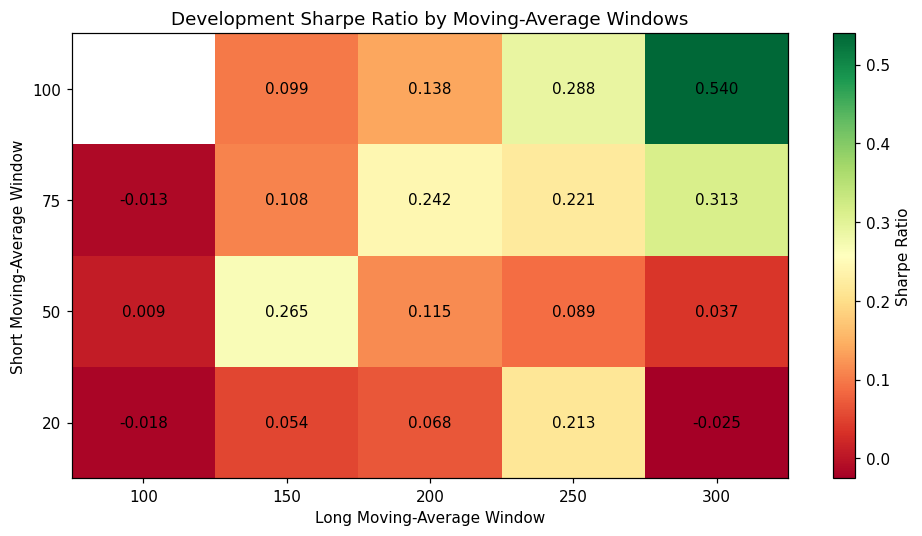

In [43]:
sharpe_grid = parameter_results_df.pivot(
    index="Short window",
    columns="Long window",
    values="Sharpe ratio"
)

sharpe_grid = (
    sharpe_grid
    .sort_index()
    .sort_index(axis=1)
)

display(sharpe_grid.round(3))

plt.figure(figsize=(9, 5))

heatmap = plt.imshow(
    sharpe_grid,
    cmap="RdYlGn",
    aspect="auto",
    origin="lower"
)

plt.colorbar(
    heatmap,
    label="Sharpe Ratio"
)

plt.xticks(
    range(len(sharpe_grid.columns)),
    sharpe_grid.columns
)

plt.yticks(
    range(len(sharpe_grid.index)),
    sharpe_grid.index
)


for row in range(len(sharpe_grid.index)):

    for column in range(len(sharpe_grid.columns)):

        value = sharpe_grid.iloc[row, column]

        if pd.notna(value):

            plt.text(
                column,
                row,
                f"{value:.3f}",
                ha="center",
                va="center",
                color="black"
            )


plt.title(
    "Development Sharpe Ratio by Moving-Average Windows"
)

plt.xlabel("Long Moving-Average Window")
plt.ylabel("Short Moving-Average Window")

plt.tight_layout()
plt.show()

<a id="step-20f"></a>

### Step 20F — Generalise the backtest to a supplied date range

The function now accepts evaluation dates as well as the moving-average windows. Indicators still use preceding price history, while metrics are calculated only on the requested dates.

This early function treats each evaluation period as starting from cash and charges an initial entry cost. Later portfolio calculations use one continuous return history across the development/test boundary; the difference is documented where that convention changes.


In [44]:
def backtest_pair_on_dates(
    short_window,
    long_window,
    evaluation_dates
):

    short_average_pair = prices.rolling(
        window=short_window
    ).mean()

    long_average_pair = prices.rolling(
        window=long_window
    ).mean()


    decision_positions_pair = pd.Series(
        0.0,
        index=prices.index
    )

    decision_positions_pair.loc[
        short_average_pair > long_average_pair
    ] = 1.0

    decision_positions_pair.loc[
        short_average_pair < long_average_pair
    ] = -1.0


    held_positions_pair = (
        decision_positions_pair.shift(1).fillna(0.0)
    )


    positions_for_period = held_positions_pair.loc[
        evaluation_dates
    ]

    returns_for_period = asset_returns.loc[
        evaluation_dates
    ]


    gross_returns = (
        positions_for_period * returns_for_period
    )


    previous_positions = (
        positions_for_period.shift(1).fillna(0.0)
    )

    turnover_for_period = (
        positions_for_period - previous_positions
    ).abs()


    transaction_costs = (
        turnover_for_period * cost_per_unit
    )

    net_returns = (
        gross_returns - transaction_costs
    )


    return calculate_metrics(net_returns)

<a id="step-20g"></a>

### Step 20G — Compare the three named candidates

The candidates are the conventional 50/200 pair, the interior 75/250 pair and the development winner 100/300. Their development and later-period results are reported together.

The candidate labels record the research choices made at this stage. The later enhanced model is a separate design, so these results should not be presented as a pristine test of that final model.


In [45]:
candidate_pairs = {
    "Conventional 50/200": (50, 200),
    "Robust interior 75/250": (75, 250),
    "Development winner 100/300": (100, 300)
}


candidate_comparison = []


for strategy_name, windows in candidate_pairs.items():

    short_window = windows[0]
    long_window = windows[1]


    development_metrics = backtest_pair_on_dates(
        short_window,
        long_window,
        common_development_dates
    )

    test_metrics = backtest_pair_on_dates(
        short_window,
        long_window,
        test_strategy_returns.index
    )


    candidate_comparison.append({

        "Candidate": strategy_name,

        "Development CAGR (%)":
            development_metrics["CAGR (%)"],

        "Test CAGR (%)":
            test_metrics["CAGR (%)"],

        "Development Sharpe":
            development_metrics["Sharpe ratio"],

        "Test Sharpe":
            test_metrics["Sharpe ratio"],

        "Development MDD (%)":
            development_metrics["Maximum drawdown (%)"],

        "Test MDD (%)":
            test_metrics["Maximum drawdown (%)"]
    })


candidate_comparison_df = pd.DataFrame(
    candidate_comparison
)


display(
    candidate_comparison_df.round(3)
)

,Candidate,Development CAGR (%),Test CAGR (%),Development Sharpe,Test Sharpe,Development MDD (%),Test MDD (%)
0,Conventional 50/200,0.490,8.468,0.115,0.560,-40.241,-27.146
1,Robust interior 75/250,2.354,12.240,0.221,0.760,-42.365,-19.356
2,Development winner 100/300,8.138,12.579,0.540,0.778,-33.717,-20.078


<a id="step-21"></a>

## Step 21 — Cross-asset testing

<a id="step-21a"></a>

### Step 21A — Define and align the four-asset universe

Apply the same slow trend rule to four ETFs:

| Ticker | Exposure represented |
|---|---|
| SPY | US equities |
| TLT | Long-term US Treasury bonds |
| GLD | Gold |
| DBC | Broad commodity exposure |

Each asset uses the 100/300 moving-average pair, a one-trading-day signal delay, five-basis-point transaction costs and the 1 January 2021 split. Parameters are not separately optimised for each asset in this section.

The download preserves the SPY series already used and aligns the other adjusted closing-price series to its dates. These are US-listed ETF returns; the notebook contains no separate FX strategy.


In [46]:
cross_asset_short_window = 100
cross_asset_long_window = 300
cost_per_unit = 0.0005


asset_descriptions = {
    "SPY": "US equities",
    "TLT": "Long-term US Treasury bonds",
    "GLD": "Gold",
    "DBC": "Broad commodities"
}


download_start = prices.index.min().strftime(
    "%Y-%m-%d"
)

download_end = (
    prices.index.max() + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")


multi_asset_prices = pd.DataFrame(
    index=prices.index
)

# Preserve the SPY prices already used throughout the project
multi_asset_prices["SPY"] = prices


for ticker in ["TLT", "GLD", "DBC"]:

    downloaded_asset = load_adjusted_etf_data(
        ticker, download_start, download_end
    )

    downloaded_close = downloaded_asset[
        "Close"
    ]

    # Recent yfinance versions may return a
    # one-column DataFrame instead of a Series
    if isinstance(downloaded_close, pd.DataFrame):
        downloaded_close = downloaded_close.iloc[:, 0]

    multi_asset_prices[ticker] = (
        downloaded_close.reindex(prices.index)
    )

#### Audit price coverage and completeness

Inspect coverage before constructing the shared price panel. Retain dates with observations for all four assets, so cross-asset comparisons are based on the same available history.


In [47]:
coverage_report = pd.DataFrame({
    "Market": pd.Series(asset_descriptions),

    "First valid date": [
        multi_asset_prices[ticker]
        .first_valid_index()
        .date()

        for ticker in multi_asset_prices.columns
    ],

    "Last valid date": [
        multi_asset_prices[ticker]
        .last_valid_index()
        .date()

        for ticker in multi_asset_prices.columns
    ],

    "Missing observations": (
        multi_asset_prices.isna().sum()
    )
})


display(coverage_report)


multi_asset_prices_complete = (
    multi_asset_prices.dropna()
)


print(
    "Common data period:",
    multi_asset_prices_complete.index[0].date(),
    "to",
    multi_asset_prices_complete.index[-1].date()
)

print(
    "Common observations:",
    len(multi_asset_prices_complete)
)

print(
    "Duplicate dates:",
    multi_asset_prices_complete
    .index.duplicated().any()
)

print(
    "All prices positive:",
    (
        multi_asset_prices_complete > 0
    ).all().all()
)


display(
    multi_asset_prices_complete.head()
)

,Market,First valid date,Last valid date,Missing observations
SPY,US equities,2010-01-04,2025-12-31,0
TLT,Long-term US Treasury bonds,2010-01-04,2025-12-31,0
GLD,Gold,2010-01-04,2025-12-31,0
DBC,Broad commodities,2010-01-04,2025-12-31,0


Common data period: 2010-01-04 to 2025-12-31
Common observations: 4024
Duplicate dates: False
All prices positive: True


,SPY,TLT,GLD,DBC
Date,,,,
2010-01-04,84.368965,54.849918,109.800003,21.338844
2010-01-05,84.592270,55.204132,109.699997,21.364208
2010-01-06,84.651871,54.465164,111.510002,21.744654
2010-01-07,85.009232,54.556767,110.820000,21.474115
2010-01-08,85.292084,54.532356,111.370003,21.457207


<a id="step-21b"></a>

### Step 21B — Apply the 100/300 rule to every asset

We now apply the same 100-day/300-day moving-average strategy to SPY, TLT, GLD and DBC.

**MA** means **moving average**. An $N$-day moving average is the mean of the most recent $N$ prices:

$$
\mathrm{MA}_{N,i,t}
=
\frac{1}{N}
\sum_{k=0}^{N-1}P_{i,t-k}
$$

where:

- $P_{i,t-k}$ is the price of asset $i$, $k$ trading days before date $t$.
- $N$ is the moving-average window.
- $i$ identifies the asset.
- $t$ identifies the date.

The 100-day moving average reacts relatively quickly to recent price changes, while the 300-day moving average represents the slower, longer-term trend.

#### Trading decision

For every asset, the decision is:

$$
d_{i,t}
=
\begin{cases}
+1, & \mathrm{MA}_{100,i,t}>\mathrm{MA}_{300,i,t} \\
-1, & \mathrm{MA}_{100,i,t}<\mathrm{MA}_{300,i,t} \\
0, & \text{otherwise}
\end{cases}
$$

where:

- $d_{i,t}=+1$ means decide to go long.
- $d_{i,t}=-1$ means decide to go short.
- $d_{i,t}=0$ means hold no position.

#### Preventing look-ahead bias

A decision calculated using today's closing price cannot be used to earn today's return.

Therefore, the position held on date $t$ is yesterday's decision:

$$
s_{i,t}
=
d_{i,t-1}
$$

This one-day delay prevents a closing-price decision from earning the same closing-price return. Trade prices and fills remain simplified daily backtest assumptions.

#### Gross strategy return

The daily return of asset $i$ is:

$$
r_{i,t}
=
\frac{P_{i,t}}{P_{i,t-1}}-1
$$

The gross strategy return is:

$$
R^{\mathrm{gross}}_{i,t}
=
s_{i,t}r_{i,t}
$$

Therefore:

- A long position earns the asset return.
- A short position earns the negative of the asset return.
- A zero position earns zero.

#### Turnover

Turnover measures the size of the position change:

$$
T_{i,t}
=
\left|s_{i,t}-s_{i,t-1}\right|
$$

For example, switching directly from long to short produces:

$$
T_{i,t}
=
|-1-(+1)|
=
2
$$

because the strategy must close the long position and open a short position.

#### Transaction costs

We assume a transaction cost of 5 basis points per unit of turnover:

$$
c
=
5\text{ bps}
=
0.0005
$$

The cost on date $t$ is:

$$
C_{i,t}
=
cT_{i,t}
$$

The net strategy return is:

$$
R^{\mathrm{net}}_{i,t}
=
R^{\mathrm{gross}}_{i,t}-C_{i,t}
$$

Therefore:

$$
R^{\mathrm{net}}_{i,t}
=
s_{i,t}r_{i,t}
-
c\left|s_{i,t}-s_{i,t-1}\right|
$$

#### Fair evaluation period

Every asset must be evaluated over the same dates.

The strategy cannot begin until yesterday's 300-day moving average exists. This ensures that:

- Every asset has completed the required warm-up period.
- Every asset is tested over the same market dates.
- Performance differences do not arise from different starting periods.

The common evaluation period is then separated chronologically into:

- **Development period:** before 1 January 2021.
- **Test period:** from 1 January 2021 onward.

Each period begins from cash and includes the transaction cost of entering its initial position.

The same 100/300 parameters are used for every asset. No asset receives separately optimised parameters, allowing us to test whether the original trend rule generalises across different markets.


#### Calculate asset returns and moving averages

Each column represents an asset and each row a trading date. The same windows are applied to the complete aligned price panel.


In [48]:
cross_asset_returns = (
    multi_asset_prices_complete
    .pct_change(fill_method=None)
)


cross_asset_short_average = (
    multi_asset_prices_complete
    .rolling(
        window=cross_asset_short_window
    )
    .mean()
)


cross_asset_long_average = (
    multi_asset_prices_complete
    .rolling(
        window=cross_asset_long_window
    )
    .mean()
)

#### Create decisions and delayed positions

Subtracting the two Boolean comparisons produces long, short and flat decisions. The shift creates the positions used for subsequent returns.


In [49]:
cross_asset_decision_positions = (
    (
        cross_asset_short_average
        > cross_asset_long_average
    ).astype(float)

    -

    (
        cross_asset_short_average
        < cross_asset_long_average
    ).astype(float)
)


cross_asset_held_positions = (
    cross_asset_decision_positions
    .shift(1)
    .fillna(0.0)
)

#### Interpret the signal construction

$1-0=+1$ when the short average is higher.

$0-1=-1$ when the short average is lower.

$0-0=0$ during the warm-up period.

##### Define common evaluation dates

Restrict evaluation to dates when the delayed slow moving average is available for every asset.


In [50]:
cross_asset_valid_mask = (
    cross_asset_long_average
    .shift(1)
    .notna()
    .all(axis=1)
)


cross_asset_evaluation_dates = (
    multi_asset_prices_complete.index[
        cross_asset_valid_mask
    ]
)


cross_asset_development_dates = (
    cross_asset_evaluation_dates[
        cross_asset_evaluation_dates < split_date
    ]
)


cross_asset_test_dates = (
    cross_asset_evaluation_dates[
        cross_asset_evaluation_dates >= split_date
    ]
)


print(
    "Common fair period:",
    cross_asset_evaluation_dates[0].date(),
    "to",
    cross_asset_evaluation_dates[-1].date()
)

print(
    "Development observations:",
    len(cross_asset_development_dates)
)

print(
    "Test observations:",
    len(cross_asset_test_dates)
)

Common fair period: 2011-03-14 to 2025-12-31
Development observations: 2469
Test observations: 1255


#### Calculate period-specific net returns

The saved common sample begins on 14 March 2011, when yesterday’s 300-day moving average is available.

This function starts each evaluation period from cash and charges the initial entry cost, matching our earlier candidate test.


In [51]:
def build_cross_asset_period(
    evaluation_dates
):

    positions_for_period = (
        cross_asset_held_positions.loc[
            evaluation_dates
        ]
    )

    asset_returns_for_period = (
        cross_asset_returns.loc[
            evaluation_dates
        ]
    )


    gross_returns_for_period = (
        positions_for_period
        * asset_returns_for_period
    )


    previous_positions_for_period = (
        positions_for_period
        .shift(1)
        .fillna(0.0)
    )


    turnover_for_period = (
        positions_for_period
        - previous_positions_for_period
    ).abs()


    costs_for_period = (
        turnover_for_period
        * cost_per_unit
    )


    net_returns_for_period = (
        gross_returns_for_period
        - costs_for_period
    )


    return (
        net_returns_for_period,
        positions_for_period,
        turnover_for_period
    )

#### Evaluate development and test returns

Evaluate both chronological subsets with the same function and initial-entry convention.


In [52]:
(
    cross_asset_development_returns,
    cross_asset_development_positions,
    cross_asset_development_turnover
) = build_cross_asset_period(
    cross_asset_development_dates
)


(
    cross_asset_test_returns,
    cross_asset_test_positions,
    cross_asset_test_turnover
) = build_cross_asset_period(
    cross_asset_test_dates
)

#### Compare cross-asset performance

Use the shared metric definitions to compare the four assets in each period. The Sharpe values here retain the preliminary zero-rate convention.


In [53]:
cross_asset_results = []


for ticker in multi_asset_prices_complete.columns:

    development_metrics = calculate_metrics(
        cross_asset_development_returns[
            ticker
        ]
    )

    test_metrics = calculate_metrics(
        cross_asset_test_returns[
            ticker
        ]
    )


    cross_asset_results.append({

        "Ticker": ticker,

        "Development CAGR (%)":
            development_metrics["CAGR (%)"],

        "Test CAGR (%)":
            test_metrics["CAGR (%)"],

        "Development Sharpe":
            development_metrics["Sharpe ratio"],

        "Test Sharpe":
            test_metrics["Sharpe ratio"],

        "Development MDD (%)":
            development_metrics[
                "Maximum drawdown (%)"
            ],

        "Test MDD (%)":
            test_metrics[
                "Maximum drawdown (%)"
            ]
    })


cross_asset_results_df = pd.DataFrame(
    cross_asset_results
)


display(
    cross_asset_results_df.round(3)
)

,Ticker,Development CAGR (%),Test CAGR (%),Development Sharpe,Test Sharpe,Development MDD (%),Test MDD (%)
0,SPY,8.138,12.579,0.540,0.778,-33.717,-20.078
1,TLT,1.265,-4.746,0.159,-0.222,-37.017,-28.646
2,GLD,1.479,7.761,0.172,0.555,-42.448,-39.683
3,DBC,-2.708,3.819,-0.092,0.294,-54.655,-49.358


<a id="step-21c"></a>

### Step 21C — Compare each asset with buy-and-hold

A positive trend return is not automatically impressive. We need to compare each strategy with simply buying and holding the corresponding asset.

Create cost-adjusted buy-and-hold returns

This charges buy-and-hold the same 5-basis-point initial entry cost.


In [54]:
def build_cross_asset_buy_hold_period(
    evaluation_dates
):

    asset_returns_for_period = (
        cross_asset_returns.loc[
            evaluation_dates
        ]
    )


    buy_hold_positions = pd.DataFrame(
        1.0,
        index=evaluation_dates,
        columns=asset_returns_for_period.columns
    )


    previous_buy_hold_positions = (
        buy_hold_positions
        .shift(1)
        .fillna(0.0)
    )


    buy_hold_turnover = (
        buy_hold_positions
        - previous_buy_hold_positions
    ).abs()


    buy_hold_costs = (
        buy_hold_turnover
        * cost_per_unit
    )


    buy_hold_net_returns = (
        buy_hold_positions
        * asset_returns_for_period
        - buy_hold_costs
    )


    return buy_hold_net_returns

#### Build the two period-specific benchmarks

Apply the initial-cost buy-and-hold calculation to each period using the same dates as the corresponding strategy.


In [55]:
cross_asset_development_buy_hold = (
    build_cross_asset_buy_hold_period(
        cross_asset_development_dates
    )
)


cross_asset_test_buy_hold = (
    build_cross_asset_buy_hold_period(
        cross_asset_test_dates
    )
)

#### Create a reusable comparison function

The function puts trend and passive metrics side by side for each asset, making differences easier to inspect.


In [56]:
def create_trend_benchmark_table(
    trend_returns,
    buy_hold_returns
):

    comparison_rows = []


    for ticker in trend_returns.columns:

        trend_metrics = calculate_metrics(
            trend_returns[ticker]
        )

        buy_hold_metrics = calculate_metrics(
            buy_hold_returns[ticker]
        )


        comparison_rows.append({

            "Ticker": ticker,

            "Trend CAGR (%)":
                trend_metrics["CAGR (%)"],

            "Buy-and-hold CAGR (%)":
                buy_hold_metrics["CAGR (%)"],

            "Trend Sharpe":
                trend_metrics["Sharpe ratio"],

            "Buy-and-hold Sharpe":
                buy_hold_metrics["Sharpe ratio"],

            "Trend MDD (%)":
                trend_metrics["Maximum drawdown (%)"],

            "Buy-and-hold MDD (%)":
                buy_hold_metrics[
                    "Maximum drawdown (%)"
                ]
        })


    return pd.DataFrame(
        comparison_rows
    )

#### Display the development and test comparisons

Display the development comparison separately from the test comparison so that the two samples are not mixed.


In [57]:
development_trend_benchmark = (
    create_trend_benchmark_table(
        cross_asset_development_returns,
        cross_asset_development_buy_hold
    )
)


test_trend_benchmark = (
    create_trend_benchmark_table(
        cross_asset_test_returns,
        cross_asset_test_buy_hold
    )
)


print("DEVELOPMENT PERIOD")
display(
    development_trend_benchmark.round(3)
)


print("TEST PERIOD")
display(
    test_trend_benchmark.round(3)
)

DEVELOPMENT PERIOD


,Ticker,Trend CAGR (%),Buy-and-hold CAGR (%),Trend Sharpe,Buy-and-hold Sharpe,Trend MDD (%),Buy-and-hold MDD (%)
0,SPY,8.138,13.590,0.540,0.825,-33.717,-33.717
1,TLT,1.265,8.494,0.159,0.635,-37.017,-20.659
2,GLD,1.479,2.631,0.172,0.243,-42.448,-45.555
3,DBC,-2.708,-6.590,-0.092,-0.347,-54.655,-66.144


TEST PERIOD


,Ticker,Trend CAGR (%),Buy-and-hold CAGR (%),Trend Sharpe,Buy-and-hold Sharpe,Trend MDD (%),Buy-and-hold MDD (%)
0,SPY,12.579,14.384,0.778,0.871,-20.078,-24.496
1,TLT,-4.746,-8.403,-0.222,-0.466,-28.646,-44.144
2,GLD,7.761,17.376,0.555,1.103,-39.683,-21.033
3,DBC,3.819,11.857,0.294,0.692,-49.358,-27.340


<a id="step-22"></a>

## Step 22 — Portfolio aggregation and diversification

<a id="step-22a"></a>

### Step 22A — Form an equal-weight cross-asset portfolio

Each of the four assets receives an equal weight of 25%:

$$
R_{p,t}
=
\frac{1}{4}
\sum_{i=1}^{4}R_{i,t}
$$

where:

- $R_{p,t}$ is the portfolio return on day $t$.
- $R_{i,t}$ is asset $i$'s net strategy return.

Transaction costs are already deducted from each asset's return.

Equal averaging of daily sleeve returns represents maintained portfolio allocations. The passive equal-weight comparator at this stage is a constant-weight return calculation, rather than an initially equal-weight portfolio allowed to drift. Step 25A introduces the latter explicitly.


In [58]:
development_trend_portfolio_returns = (
    cross_asset_development_returns.mean(
        axis=1
    )
)


test_trend_portfolio_returns = (
    cross_asset_test_returns.mean(
        axis=1
    )
)


development_buy_hold_portfolio_returns = (
    cross_asset_development_buy_hold.mean(
        axis=1
    )
)


test_buy_hold_portfolio_returns = (
    cross_asset_test_buy_hold.mean(
        axis=1
    )
)

#### Calculate portfolio-level metrics

Evaluate the equal-weight trend and passive reference portfolios in both periods. These are portfolio-return metrics, not averages of individual Sharpe ratios.


In [59]:
portfolio_results = pd.DataFrame({

    "Development trend portfolio":
        calculate_metrics(
            development_trend_portfolio_returns
        ),

    "Development buy-and-hold portfolio":
        calculate_metrics(
            development_buy_hold_portfolio_returns
        ),

    "Test trend portfolio":
        calculate_metrics(
            test_trend_portfolio_returns
        ),

    "Test buy-and-hold portfolio":
        calculate_metrics(
            test_buy_hold_portfolio_returns
        )
}).T


display(
    portfolio_results.round(3)
)

,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Sharpe ratio,Maximum drawdown (%)
Development trend portfolio,32.890,2.945,3.221,7.987,0.403,-26.631
Development buy-and-hold portfolio,64.487,5.211,5.443,8.507,0.640,-19.429
Test trend portfolio,32.119,5.752,5.991,8.917,0.672,-11.211
Test buy-and-hold portfolio,55.692,9.297,9.411,10.201,0.923,-18.003


<a id="step-22b"></a>

### Step 22B — Examine diversification

We should verify whether the four strategies produced differently timed returns.

Correlation measures co-movement in the observed return series. Low average correlation can support diversification, but it does not guarantee protection during a future stress period.


In [60]:
development_strategy_correlations = (
    cross_asset_development_returns.corr()
)

test_strategy_correlations = (
    cross_asset_test_returns.corr()
)


print("DEVELOPMENT CORRELATIONS")
display(
    development_strategy_correlations.round(3)
)


print("TEST CORRELATIONS")
display(
    test_strategy_correlations.round(3)
)

DEVELOPMENT CORRELATIONS


,SPY,TLT,GLD,DBC
SPY,1.000,-0.181,-0.048,-0.124
TLT,-0.181,1.000,0.149,0.128
GLD,-0.048,0.149,1.000,0.124
DBC,-0.124,0.128,0.124,1.000


TEST CORRELATIONS


,SPY,TLT,GLD,DBC
SPY,1.000,-0.028,0.089,0.068
TLT,-0.028,1.000,-0.022,0.036
GLD,0.089,-0.022,1.000,0.062
DBC,0.068,0.036,0.062,1.000


#### Summarise pairwise strategy correlations

Exclude the diagonal self-correlations and average the distinct asset-pair correlations. This is a descriptive summary of the observed strategies.


In [61]:
def average_pairwise_correlation(
    correlation_matrix
):

    upper_triangle = np.triu_indices_from(
        correlation_matrix,
        k=1
    )

    return correlation_matrix.values[
        upper_triangle
    ].mean()


print(
    "Development average correlation:",
    round(
        average_pairwise_correlation(
            development_strategy_correlations
        ),
        3
    )
)

print(
    "Test average correlation:",
    round(
        average_pairwise_correlation(
            test_strategy_correlations
        ),
        3
    )
)

Development average correlation: 0.008
Test average correlation: 0.034


<a id="step-23"></a>

## Step 23 — Volatility targeting, cash and financing

<a id="step-23a"></a>

### Step 23A — Estimate a volatility-targeting multiplier

Volatility targeting adjusts the portfolio's market exposure according to its estimated risk:

- High forecast volatility → reduce exposure.
- Low forecast volatility → increase exposure.

We estimate annualised volatility using the previous 60 daily portfolio returns:

$$
\hat{\sigma}_t
=
\sigma_{\mathrm{daily},t}\sqrt{252}
$$

Today's exposure uses yesterday's estimate to prevent look-ahead bias:

$$
m_t
=
\min\left(
1.5,\,
\frac{0.10}{\hat{\sigma}_{t-1}}
\right)
$$

where:

- $m_t$ is the exposure multiplier.
- $0.10$ is the 10% target volatility.
- $1.5$ is the maximum permitted exposure.

For example:

- Forecast volatility of 20% gives $m_t=0.5$.
- Forecast volatility of 10% gives $m_t=1$.
- Forecast volatility of 5% gives $m_t=2$, capped at $1.5$.

This step calculates the exposure multiplier only. It does not yet apply it to portfolio returns.

This is an intermediate long/short experiment. The final model in Step 24 uses inverse-volatility base weights and long/cash trend scores; it does not carry forward the 1.5 exposure cap or mechanically target 10% portfolio volatility.


In [62]:
base_portfolio_weights = (
    cross_asset_held_positions.loc[
        cross_asset_evaluation_dates
    ] / 4
)


base_portfolio_gross_returns = (
    base_portfolio_weights
    * cross_asset_returns.loc[
        cross_asset_evaluation_dates
    ]
).sum(axis=1)

#### Calculate and delay rolling volatility

Compute a 60-observation sample standard deviation, annualise it, and delay it by one row before using it for exposure.


In [63]:
volatility_lookback = 60

rolling_portfolio_volatility = (
    base_portfolio_gross_returns
    .rolling(volatility_lookback)
    .std()
    * np.sqrt(252)
)


forecast_portfolio_volatility = (
    rolling_portfolio_volatility.shift(1)
)

#### Construct the capped exposure multiplier

Divide the 10% annual volatility target by the delayed forecast and cap the resulting multiplier at 1.5.


In [64]:
target_volatility = 0.10
maximum_exposure = 1.50


volatility_multiplier = (
    target_volatility
    / forecast_portfolio_volatility
).clip(
    upper=maximum_exposure
)

In [65]:
volatility_targeting_summary = pd.DataFrame({

    "Forecast volatility (%)":
        forecast_portfolio_volatility * 100,

    "Exposure multiplier":
        volatility_multiplier
}).dropna()


print(
    "First volatility-targeting date:",
    volatility_targeting_summary.index[
        0
    ].date()
)


display(
    volatility_targeting_summary
    .describe()
    .round(3)
)

First volatility-targeting date: 2011-06-08


,Forecast volatility (%),Exposure multiplier
count,3664.000,3664.000
mean,7.909,1.271
std,2.414,0.245
min,3.845,0.628
25%,6.173,1.116
50%,7.461,1.340
75%,8.961,1.500
max,15.920,1.500


<a id="step-23b"></a>

### Step 23B — Apply volatility targeting

The exposure multiplier is applied to each asset's equal-weight position:

$$
w_{i,t}^{*}
=
m_t\frac{s_{i,t}}{4}
$$

where:

- $w_{i,t}^{*}$ is asset $i$'s targeted weight.
- $m_t$ is the volatility multiplier.
- $s_{i,t}$ is the long or short position.

The portfolio's gross return is:

$$
R_{p,t}^{\mathrm{gross}}
=
\sum_{i=1}^{4}w_{i,t}^{*}r_{i,t}
$$

Changing either the trend signal or volatility multiplier changes the target weights. The code estimates turnover from consecutive target weights:

$$
T_t
=
\sum_{i=1}^{4}
\left|
w_{i,t}^{*}-w_{i,t-1}^{*}
\right|
$$

After 5-basis-point transaction costs:

$$
R_{p,t}^{\mathrm{net}}
=
R_{p,t}^{\mathrm{gross}}
-
0.0005T_t
$$

This includes the trading cost of changing exposure, but not yet cash interest or leverage-financing costs.

This is a target-weight-change proxy. It does not reconstruct the weights after price drift and before rebalancing, so it omits the trading required solely to restore unchanged targets.


In [66]:
# ============================================================
# STEP 23B — APPLY VOLATILITY TARGETING
# ============================================================


# Dates for which the volatility forecast and multiplier exist.

volatility_targeting_dates = (
    volatility_targeting_summary.index
)


# Apply each day's exposure multiplier to all four
# equal-weight long or short positions.

volatility_targeted_weights = (
    base_portfolio_weights.loc[
        volatility_targeting_dates
    ]
    .mul(
        volatility_multiplier.loc[
            volatility_targeting_dates
        ],
        axis=0
    )
)


# Calculate net portfolio returns from a set of weights.

def calculate_returns_from_weights(
    portfolio_weights,
    evaluation_dates
):

    # Select the portfolio weights and asset returns
    # for the required dates.

    period_weights = (
        portfolio_weights.loc[
            evaluation_dates
        ]
    )

    period_asset_returns = (
        cross_asset_returns.loc[
            evaluation_dates
        ]
    )


    # Calculate the portfolio's gross daily return.

    gross_portfolio_returns = (
        period_weights
        * period_asset_returns
    ).sum(axis=1)


    # Obtain the previous day's portfolio weights.
    # Zero represents entering from cash on the first
    # date of the complete evaluation period.

    previous_weights = (
        period_weights
        .shift(1)
        .fillna(0.0)
    )


    # Add the absolute weight changes across all assets
    # to calculate daily portfolio turnover.

    portfolio_turnover = (
        period_weights
        - previous_weights
    ).abs().sum(axis=1)


    # Apply the transaction cost per unit of turnover.

    portfolio_costs = (
        portfolio_turnover
        * cost_per_unit
    )


    # Deduct transaction costs from gross returns.

    net_portfolio_returns = (
        gross_portfolio_returns
        - portfolio_costs
    )


    return (
        net_portfolio_returns,
        portfolio_turnover,
        portfolio_costs
    )


# Define the development and test dates.

volatility_development_dates = (
    volatility_targeting_dates[
        volatility_targeting_dates
        < split_date
    ]
)

volatility_test_dates = (
    volatility_targeting_dates[
        volatility_targeting_dates
        >= split_date
    ]
)


# Calculate the complete continuous history first.
# This prevents an artificial new entry trade at
# the beginning of the test period.

(
    all_targeted_returns,
    all_targeted_turnover,
    all_targeted_costs
) = calculate_returns_from_weights(
    volatility_targeted_weights,
    volatility_targeting_dates
)


# Split net returns into development and test periods.

development_targeted_returns = (
    all_targeted_returns.loc[
        volatility_development_dates
    ]
)

test_targeted_returns = (
    all_targeted_returns.loc[
        volatility_test_dates
    ]
)


# Split turnover into development and test periods.

development_targeted_turnover = (
    all_targeted_turnover.loc[
        volatility_development_dates
    ]
)

test_targeted_turnover = (
    all_targeted_turnover.loc[
        volatility_test_dates
    ]
)


# Split transaction costs into development and test periods.

development_targeted_costs = (
    all_targeted_costs.loc[
        volatility_development_dates
    ]
)

test_targeted_costs = (
    all_targeted_costs.loc[
        volatility_test_dates
    ]
)


# Inspect turnover and the first targeted weights.

print(
    "Development total turnover:",
    round(
        development_targeted_turnover.sum(),
        3
    )
)

print(
    "Test total turnover:",
    round(
        test_targeted_turnover.sum(),
        3
    )
)

display(
    volatility_targeted_weights.head()
)

Development total turnover: 46.349
Test total turnover: 23.942


,SPY,TLT,GLD,DBC
Date,,,,
2011-06-08,0.202901,-0.202901,0.202901,0.202901
2011-06-09,0.202775,-0.202775,0.202775,0.202775
2011-06-10,0.215390,-0.215390,0.215390,0.215390
2011-06-13,0.212955,-0.212955,0.212955,0.212955
2011-06-14,0.219349,-0.219349,0.219349,0.219349


<a id="step-23c"></a>

### Step 23C — Compare targeted and unscaled portfolios

We now test whether volatility targeting improves the original equal-weight trend portfolio.

The unscaled weights are:

$$
w_{i,t}^{U}
=
\frac{s_{i,t}}{4}
$$

The volatility-targeted weights are:

$$
w_{i,t}^{VT}
=
m_t\frac{s_{i,t}}{4}
$$

Both portfolios use the same:

- Assets and trend signals.
- Evaluation dates.
- Asset returns.
- Transaction-cost rate.

Therefore, the exposure multiplier $m_t$ is the only difference between them.

Because volatility targeting requires a 60-day warm-up, the unscaled portfolio must be restricted to the same dates for a fair comparison.


In [67]:
# Restrict the unscaled portfolio to the dates
# on which volatility targeting is available.

unscaled_weights_same_dates = (
    base_portfolio_weights.loc[
        volatility_targeting_dates
    ]
)


# Calculate both portfolios across the complete timeline
# before separating development and test periods.

(
    all_unscaled_returns,
    all_unscaled_turnover,
    all_unscaled_costs
) = calculate_returns_from_weights(
    unscaled_weights_same_dates,
    volatility_targeting_dates
)


(
    all_targeted_returns,
    all_targeted_turnover,
    all_targeted_costs
) = calculate_returns_from_weights(
    volatility_targeted_weights,
    volatility_targeting_dates
)

#### Preserve continuity across the development/test split

Returns and turnover are first calculated across the complete timeline and only then divided into development and test periods.

This is important because turnover depends on the previous day's weights:

$$
T_t
=
\sum_{i=1}^{4}
\left|
w_{i,t}-w_{i,t-1}
\right|
$$

If the two periods were calculated separately, the first test-period weight would incorrectly be compared with zero. That would create an artificial entry trade at the start of testing.


In [68]:
# Split the completed return series into
# development and test periods.

development_unscaled_same_dates = (
    all_unscaled_returns.loc[
        volatility_development_dates
    ]
)

test_unscaled_same_dates = (
    all_unscaled_returns.loc[
        volatility_test_dates
    ]
)


development_targeted_returns = (
    all_targeted_returns.loc[
        volatility_development_dates
    ]
)

test_targeted_returns = (
    all_targeted_returns.loc[
        volatility_test_dates
    ]
)

#### Compare performance on identical dates

We compare the unscaled and volatility-targeted portfolios using identical dates.

The main questions are:

- Did realised volatility move closer to the 10% target?
- Did the preliminary zero-rate return-to-volatility ratio improve after transaction costs?
- Did maximum drawdown decrease?
- Did the result remain consistent in the test period?

A higher CAGR alone does not prove improvement because the targeted portfolio can use exposure above 100%.


In [69]:
volatility_targeting_comparison = pd.DataFrame({

    "Development unscaled":
        calculate_metrics(
            development_unscaled_same_dates
        ),

    "Development volatility-targeted":
        calculate_metrics(
            development_targeted_returns
        ),

    "Test unscaled":
        calculate_metrics(
            test_unscaled_same_dates
        ),

    "Test volatility-targeted":
        calculate_metrics(
            test_targeted_returns
        )

}).T


display(
    volatility_targeting_comparison.round(3)
)

,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Sharpe ratio,Maximum drawdown (%)
Development unscaled,31.563,2.911,3.178,7.853,0.405,-26.631
Development volatility-targeted,35.980,3.267,3.688,9.723,0.379,-33.739
Test unscaled,32.185,5.763,6.001,8.917,0.673,-11.211
Test volatility-targeted,36.990,6.524,6.840,10.188,0.671,-9.830


#### Inspect turnover and estimated transaction costs

The unscaled portfolio mainly trades when a trend signal changes.

The targeted portfolio also trades when the volatility multiplier changes. It is therefore expected to have greater turnover:

$$
T_t
=
\sum_{i=1}^{4}
\left|
w_{i,t}-w_{i,t-1}
\right|
$$

Transaction costs are:

$$
C_t
=
0.0005T_t
$$

These costs have already been deducted from the portfolio returns. The summed cost rate below is a diagnostic and is not the exact compounded reduction in final wealth.


In [70]:
trading_activity_comparison = pd.DataFrame({

    "Period": [
        "Development",
        "Test"
    ],

    "Unscaled turnover": [
        all_unscaled_turnover.loc[
            volatility_development_dates
        ].sum(),

        all_unscaled_turnover.loc[
            volatility_test_dates
        ].sum()
    ],

    "Targeted turnover": [
        all_targeted_turnover.loc[
            volatility_development_dates
        ].sum(),

        all_targeted_turnover.loc[
            volatility_test_dates
        ].sum()
    ],

    "Unscaled summed cost rate (%)": [
        all_unscaled_costs.loc[
            volatility_development_dates
        ].sum() * 100,

        all_unscaled_costs.loc[
            volatility_test_dates
        ].sum() * 100
    ],

    "Targeted summed cost rate (%)": [
        all_targeted_costs.loc[
            volatility_development_dates
        ].sum() * 100,

        all_targeted_costs.loc[
            volatility_test_dates
        ].sum() * 100
    ]

})


display(
    trading_activity_comparison.round(3)
)

,Period,Unscaled turnover,Targeted turnover,Unscaled summed cost rate (%),Targeted summed cost rate (%)
0,Development,19.5,46.349,0.975,2.317
1,Test,9.0,23.942,0.450,1.197


<a id="step-23d"></a>

### Step 23D — Cash and financing assumptions

<a id="step-23d-a"></a>

#### Step 23D-A — Prepare the historical cash-rate proxy

Cash and borrowing rates changed substantially during the backtest. We therefore use the daily 3-month US Treasury yield as a proxy for the risk-free cash rate.

The quoted annual rate is converted into a daily return:

$$
r_{f,t}^{\mathrm{daily}}
=
(1+r_{f,t}^{\mathrm{annual}})^{1/252}-1
$$

The rate is shifted by one trading day so that each day's calculation uses information already available.

`DGS3MO` is used as a cash-rate proxy. Converting its quoted annual yield with this formula is a modelling convention, not a measured cash account or Treasury holding-period return. Calendar-day accrual, broker cash rates and funding spreads may differ.


In [71]:
risk_free_url = (
    "https://fred.stlouisfed.org/"
    "graph/fredgraph.csv?id=DGS3MO"
)


risk_free_cache = DATA_DIRECTORY / "DGS3MO.csv"
if risk_free_cache.exists():
    risk_free_data = pd.read_csv(risk_free_cache)
else:
    risk_free_data = pd.read_csv(risk_free_url)
    risk_free_data.to_csv(risk_free_cache, index=False)


risk_free_data.columns = [
    "Date",
    "Annual yield (%)"
]


risk_free_data["Date"] = pd.to_datetime(
    risk_free_data["Date"]
)


risk_free_data["Annual yield (%)"] = (
    pd.to_numeric(
        risk_free_data["Annual yield (%)"],
        errors="coerce"
    )
)


risk_free_data = (
    risk_free_data
    .set_index("Date")
    .sort_index()
)


display(
    risk_free_data.head()
) 

,Annual yield (%)
Date,
1981-09-01,17.01
1981-09-02,16.65
1981-09-03,16.96
1981-09-04,16.64
1981-09-07,NaN


##### Align and delay the cash-rate series

Treasury-rate dates do not perfectly match ETF trading dates because of weekends, holidays and missing observations.

Missing rates are forward-filled using the latest available rate. The series is then shifted by one trading day to prevent look-ahead bias.


In [72]:
evaluation_date_index = pd.DatetimeIndex(
    cross_asset_evaluation_dates
)


targeting_date_index = pd.DatetimeIndex(
    volatility_targeting_dates
)


combined_rate_dates = (
    risk_free_data.index.union(
        evaluation_date_index
    )
)


annual_risk_free_rate = (
    risk_free_data["Annual yield (%)"]
    .div(100)
    .reindex(combined_rate_dates)
    .sort_index()
    .ffill()
    .reindex(evaluation_date_index)
    .shift(1)
    .reindex(targeting_date_index)
)


daily_risk_free_rate = (
    (1.0 + annual_risk_free_rate)
    ** (1 / 252)
    - 1.0
)

##### Check rate coverage and alignment

Inspect missing values and the aligned rate sample before using the rate in daily return calculations.


In [73]:
assert annual_risk_free_rate.notna().all()


risk_free_rate_summary = pd.DataFrame({
    
    "Annual risk-free rate (%)":
        annual_risk_free_rate * 100,
    
    "Daily risk-free rate (%)":
        daily_risk_free_rate * 100
})


print(
    "First risk-free-rate date:",
    risk_free_rate_summary.index[0].date()
)


print(
    "Last risk-free-rate date:",
    risk_free_rate_summary.index[-1].date()
)


display(
    risk_free_rate_summary.head()
)


display(
    risk_free_rate_summary.describe().round(4)
)

First risk-free-rate date: 2011-06-08
Last risk-free-rate date: 2025-12-31


,Annual risk-free rate (%),Daily risk-free rate (%)
Date,,
2011-06-08,0.05,0.000198
2011-06-09,0.04,0.000159
2011-06-10,0.05,0.000198
2011-06-13,0.05,0.000198
2011-06-14,0.05,0.000198


,Annual risk-free rate (%),Daily risk-free rate (%)
count,3664.0000,3664.0000
mean,1.5575,0.0061
std,1.9222,0.0074
min,0.0000,0.0000
25%,0.0600,0.0002
50%,0.3400,0.0013
75%,2.4300,0.0095
max,5.6300,0.0217


<a id="step-23d-b"></a>

#### Step 23D-B — Decompose portfolio exposure

The portfolio's total long and short exposures are:

$$
L_t=\sum_i\max(w_{i,t},0)
$$

$$
E_t^{\mathrm{short}}
=
\sum_i\max(-w_{i,t},0)
$$

Gross and net exposure are:

$$
G_t=L_t+E_t^{\mathrm{short}}
$$

$$
N_t=L_t-E_t^{\mathrm{short}}
$$

The code uses the following simplified **gross-exposure-based financing convention**:

$$
C_t=\max(1-G_t,0)
$$

$$
B_t=\max(G_t-1,0)
$$

Under this convention, gross exposure below 100% is assigned a residual cash fraction, and exposure above 100% is assigned a borrowed fraction. For a long/short portfolio, these are modelling proxies rather than identities for an actual broker cash balance: collateral, short-sale proceeds, margin and cash rebates are not tracked.


In [74]:
def calculate_exposure_components(
    portfolio_weights
):

    long_exposure = (
        portfolio_weights
        .clip(lower=0.0)
        .sum(axis=1)
    )


    short_exposure = (
        -portfolio_weights
        .clip(upper=0.0)
        .sum(axis=1)
    )


    gross_exposure = (
        long_exposure
        + short_exposure
    )


    net_exposure = (
        long_exposure
        - short_exposure
    )


    cash_fraction = (
        1.0 - gross_exposure
    ).clip(lower=0.0)


    borrowed_fraction = (
        gross_exposure - 1.0
    ).clip(lower=0.0)


    return pd.DataFrame({

        "Long exposure":
            long_exposure,

        "Short exposure":
            short_exposure,

        "Gross exposure":
            gross_exposure,

        "Net exposure":
            net_exposure,

        "Cash fraction":
            cash_fraction,

        "Borrowed fraction":
            borrowed_fraction
    })

##### Apply the exposure calculation to both portfolios

Use the same decomposition for the unscaled and volatility-targeted weights.


In [75]:
unscaled_exposure_components = (
    calculate_exposure_components(
        unscaled_weights_same_dates
    )
)


targeted_exposure_components = (
    calculate_exposure_components(
        volatility_targeted_weights
    )
)

##### Inspect gross, net, cash and borrowed exposure

Inspect representative rows and exposure summaries to distinguish gross exposure, directional net exposure and the modelled financing fractions.


In [76]:
display(
    targeted_exposure_components
    .head()
    .round(6)
)


print(
    "Targeted days below 100% gross exposure:",
    round(
        (
            targeted_exposure_components[
                "Gross exposure"
            ] < 1.0
        ).mean() * 100,
        2
    ),
    "%"
)


print(
    "Targeted days above 100% gross exposure:",
    round(
        (
            targeted_exposure_components[
                "Gross exposure"
            ] > 1.0
        ).mean() * 100,
        2
    ),
    "%"
)


display(
    targeted_exposure_components
    .describe()
    .round(3)
)

,Long exposure,Short exposure,Gross exposure,Net exposure,Cash fraction,Borrowed fraction
Date,,,,,,
2011-06-08,0.608703,0.202901,0.811604,0.405802,0.188396,0.0
2011-06-09,0.608325,0.202775,0.811100,0.405550,0.188900,0.0
2011-06-10,0.646170,0.215390,0.861560,0.430780,0.138440,0.0
2011-06-13,0.638865,0.212955,0.851820,0.425910,0.148180,0.0
2011-06-14,0.658047,0.219349,0.877396,0.438698,0.122604,0.0


Targeted days below 100% gross exposure: 16.35 %
Targeted days above 100% gross exposure: 83.65 %


,Long exposure,Short exposure,Gross exposure,Net exposure,Cash fraction,Borrowed fraction
count,3664.000,3664.000,3664.000,3664.000,3664.000,3664.000
mean,0.764,0.506,1.271,0.258,0.028,0.299
std,0.359,0.321,0.245,0.635,0.077,0.193
min,0.000,-0.000,0.628,-1.500,0.000,0.000
25%,0.515,0.313,1.116,0.000,0.000,0.116
50%,0.750,0.395,1.340,0.000,0.000,0.340
75%,1.075,0.750,1.500,0.736,0.000,0.500
max,1.500,1.500,1.500,1.500,0.372,0.500


<a id="step-23d-c"></a>

#### Step 23D-C — Add cash income and financing adjustments

The portfolio returns calculated previously already include:

- Profit or loss from the ETF positions.
- Transaction costs caused by changing portfolio weights.

However, they do not yet include the economic effects of holding cash, using leverage or maintaining short positions.

##### Cash income

When gross exposure is below 100%, the unused fraction is treated as cash:

$$
C_t=\max(1-G_t,0)
$$

This cash earns the historical daily risk-free rate:

$$
I_t^{\mathrm{cash}}
=
C_t r_{f,t}
$$

where:

- $C_t$ is the cash fraction.
- $r_{f,t}$ is the historical daily risk-free rate.
- $I_t^{\mathrm{cash}}$ is the return earned from cash.

##### Leverage-financing cost

The implementation assigns a financing charge to gross exposure above 100%:

$$
B_t=\max(G_t-1,0)
$$

The annual borrowing rate is assumed to equal the historical risk-free rate plus a 1% financing spread:

$$
r_{t,\mathrm{annual}}^{\mathrm{borrow}}
=
r_{f,t,\mathrm{annual}}+0.01
$$

The financing cost is:

$$
F_t
=
B_t r_t^{\mathrm{borrow}}
$$

where $B_t$ is the modelled borrowed fraction under the gross-exposure convention.

##### Short-borrow cost

A short position requires borrowing the ETF before selling it. We assume an annual short-borrow fee of 0.5%.

Total short exposure is:

$$
E_t^{\mathrm{short}}
=
\sum_i\max(-w_{i,t},0)
$$

The resulting cost is:

$$
Q_t
=
E_t^{\mathrm{short}}r_t^{\mathrm{short}}
$$

Financing cost and short-borrow cost represent different expenses:

- Financing cost pays for exposure above 100%.
- Short-borrow cost pays for borrowing securities used in short positions.

##### Converting annual rates into daily rates

Because portfolio returns are calculated daily, every annual interest rate is converted into a daily rate:

$$
r_{\mathrm{daily}}
=
(1+r_{\mathrm{annual}})^{1/252}-1
$$

##### Realistic portfolio return

The final financing-adjusted return is:

$$
R_{p,t}^{\mathrm{realistic}}
=
R_{p,t}^{\mathrm{net}}
+
I_t^{\mathrm{cash}}
-
F_t
-
Q_t
$$

Therefore:

> Realistic return = existing net return + cash income − leverage-financing cost − short-borrow cost.

For example, if gross exposure is 130%, short exposure is 50%, the risk-free rate is 4%, the financing spread is 1% and the short fee is 0.5%:

$$
\text{Approximate financing cost}
=
0.30(4\%+1\%)
=
1.50\%\text{ per year}
$$

$$
\text{Approximate short cost}
=
0.50(0.5\%)
=
0.25\%\text{ per year}
$$

The same assumptions are applied to both the unscaled and volatility-targeted portfolios over identical dates. This ensures that their performance remains directly comparable.

This remains a simplified financing model. Gross exposure does not, by itself, identify the cash balance or borrowing required by a real long/short account. The calculation omits margin requirements, short-sale collateral and proceeds, rebates, and asset-specific historical borrowing fees.


In [77]:
financing_spread_annual = 0.01

short_borrow_fee_annual = 0.005


annual_borrowing_rate = (
    annual_risk_free_rate
    + financing_spread_annual
)


daily_borrowing_rate = (
    (1.0 + annual_borrowing_rate)
    ** (1 / 252)
    - 1.0
)


daily_short_borrow_rate = (
    (1.0 + short_borrow_fee_annual)
    ** (1 / 252)
    - 1.0
)

##### Define the financing-adjustment function

The function aligns the inputs, adds cash income and subtracts the two financing charges from the existing after-trading-cost returns.


In [78]:
def apply_financing_adjustments(
    net_portfolio_returns,
    exposure_components,
    daily_cash_rate,
    daily_financing_rate,
    daily_short_rate
):

    calculation_dates = (
        exposure_components.index
    )


    aligned_net_returns = (
        net_portfolio_returns
        .reindex(calculation_dates)
    )


    aligned_cash_rate = (
        daily_cash_rate
        .reindex(calculation_dates)
    )


    aligned_financing_rate = (
        daily_financing_rate
        .reindex(calculation_dates)
    )


    assert aligned_net_returns.notna().all()
    assert aligned_cash_rate.notna().all()
    assert aligned_financing_rate.notna().all()


    cash_income = (
        exposure_components[
            "Cash fraction"
        ]
        * aligned_cash_rate
    )


    financing_cost = (
        exposure_components[
            "Borrowed fraction"
        ]
        * aligned_financing_rate
    )


    short_borrow_cost = (
        exposure_components[
            "Short exposure"
        ]
        * daily_short_rate
    )


    realistic_returns = (
        aligned_net_returns
        + cash_income
        - financing_cost
        - short_borrow_cost
    )


    adjustment_breakdown = pd.DataFrame({

        "Net return before financing":
            aligned_net_returns,

        "Cash income":
            cash_income,

        "Financing cost":
            financing_cost,

        "Short-borrow cost":
            short_borrow_cost,

        "Realistic net return":
            realistic_returns
    })


    return (
        realistic_returns,
        adjustment_breakdown
    )

##### Apply the financing assumptions to both portfolios

Apply identical cash-rate, financing-spread and short-fee assumptions to the two portfolio specifications.


In [79]:
(
    unscaled_realistic_returns,
    unscaled_adjustment_breakdown
) = apply_financing_adjustments(

    all_unscaled_returns,

    unscaled_exposure_components,

    daily_risk_free_rate,

    daily_borrowing_rate,

    daily_short_borrow_rate
)


(
    targeted_realistic_returns,
    targeted_adjustment_breakdown
) = apply_financing_adjustments(

    all_targeted_returns,

    targeted_exposure_components,

    daily_risk_free_rate,

    daily_borrowing_rate,

    daily_short_borrow_rate
)

##### Inspect the return-component identities

Inspect the component table: adjusted return must equal the original net return plus cash income minus financing and short-borrow charges.


In [80]:
display(
    targeted_adjustment_breakdown
    .head()
    .round(8)
)


financing_adjustment_summary = pd.DataFrame({

    "Unscaled": [

        unscaled_adjustment_breakdown[
            "Cash income"
        ].sum() * 100,

        unscaled_adjustment_breakdown[
            "Financing cost"
        ].sum() * 100,

        unscaled_adjustment_breakdown[
            "Short-borrow cost"
        ].sum() * 100
    ],

    "Volatility-targeted": [

        targeted_adjustment_breakdown[
            "Cash income"
        ].sum() * 100,

        targeted_adjustment_breakdown[
            "Financing cost"
        ].sum() * 100,

        targeted_adjustment_breakdown[
            "Short-borrow cost"
        ].sum() * 100
    ]

}, index=[

    "Summed cash income rate (%)",

    "Summed financing-cost rate (%)",

    "Summed short-borrow-cost rate (%)"
]).T


display(
    financing_adjustment_summary.round(3)
)

,Net return before financing,Cash income,Financing cost,Short-borrow cost,Realistic net return
Date,,,,,
2011-06-08,-0.001982,3.700000e-07,0.0,0.000004,-0.001986
2011-06-09,0.004512,3.000000e-07,0.0,0.000004,0.004508
2011-06-10,-0.008816,2.700000e-07,0.0,0.000004,-0.008820
2011-06-13,-0.002268,2.900000e-07,0.0,0.000004,-0.002272
2011-06-14,0.008951,2.400000e-07,0.0,0.000004,0.008947


,Summed cash income rate (%),Summed financing-cost rate (%),Summed short-borrow-cost rate (%)
Unscaled,0.000,0.000,2.910
Volatility-targeted,0.641,11.147,3.671


<a id="step-23d-d"></a>

#### Step 23D-D — Compare performance after financing adjustments

The summed adjustment rates from Step 23D-C do not show the exact effect on wealth because daily returns compound:

$$
V_T
=
V_0
\prod_{t=1}^{T}
\left(
1+R_{p,t}^{\mathrm{realistic}}
\right)
$$

We must therefore recalculate the complete performance metrics using the financing-adjusted returns.

The comparison includes:

1. Unscaled returns before financing adjustments.
2. Unscaled realistic returns.
3. Volatility-targeted returns before financing adjustments.
4. Volatility-targeted realistic returns.

Each series is divided into the same development and test periods only after the complete continuous return series has been calculated. This preserves chronology and prevents an artificial reset at the test boundary.

We compare:

- Total return.
- CAGR.
- Annualised mean return.
- Annualised volatility.
- Sharpe ratio.
- Maximum drawdown.

The central question is:

> Does volatility targeting still improve portfolio performance after cash income, leverage-financing costs and short-borrow costs are included?

The existing `Sharpe ratio` field still uses the early zero-risk-free convention in this section. Cash income has been added to portfolio returns, but the formal excess-return Sharpe correction appears later in Step 25B.1.


##### Split the continuous return histories

Slice the already calculated histories into development and test dates without resetting the portfolio state.


In [81]:
def split_at_project_date(
    financial_data
):

    development_data = financial_data.loc[
        financial_data.index
        < split_date
    ]


    test_data = financial_data.loc[
        financial_data.index
        >= split_date
    ]


    return (
        development_data,
        test_data
    )

##### Collect returns before financing adjustments

Collect the unscaled and targeted return series before adding cash and financing components.


In [82]:
(
    development_unscaled_before_financing,
    test_unscaled_before_financing
) = split_at_project_date(
    all_unscaled_returns
)


(
    development_targeted_before_financing,
    test_targeted_before_financing
) = split_at_project_date(
    all_targeted_returns
)

##### Collect financing-adjusted returns

Collect their corresponding financing-adjusted return series for the same comparison.


In [83]:
(
    development_unscaled_realistic,
    test_unscaled_realistic
) = split_at_project_date(
    unscaled_realistic_returns
)


(
    development_targeted_realistic,
    test_targeted_realistic
) = split_at_project_date(
    targeted_realistic_returns
)

##### Confirm identical comparison dates

Matching indices ensures that a performance difference is not caused by evaluating different trading dates.


In [84]:
assert (
    development_unscaled_before_financing
    .index.equals(
        development_unscaled_realistic.index
    )
)


assert (
    test_unscaled_before_financing
    .index.equals(
        test_unscaled_realistic.index
    )
)


assert (
    development_targeted_before_financing
    .index.equals(
        development_targeted_realistic.index
    )
)


assert (
    test_targeted_before_financing
    .index.equals(
        test_targeted_realistic.index
    )
)


print(
    "Development observations:",
    len(
        development_targeted_realistic
    )
)


print(
    "Test observations:",
    len(
        test_targeted_realistic
    )
)

Development observations: 2409
Test observations: 1255


##### Separate adjustment diagnostics by period

Separate the cash-income and cost components using the same chronological split as the performance tables.


In [85]:
(
    development_unscaled_adjustments,
    test_unscaled_adjustments
) = split_at_project_date(
    unscaled_adjustment_breakdown
)


(
    development_targeted_adjustments,
    test_targeted_adjustments
) = split_at_project_date(
    targeted_adjustment_breakdown
)

##### Define a summary of cash income and financing costs

Sum the daily adjustment rates as diagnostics. These sums are not compounded performance impacts.


In [86]:
def summarize_financing_adjustments(
    adjustment_data
):

    cash_income = (
        adjustment_data[
            "Cash income"
        ].sum()
        * 100
    )


    financing_cost = (
        adjustment_data[
            "Financing cost"
        ].sum()
        * 100
    )


    short_borrow_cost = (
        adjustment_data[
            "Short-borrow cost"
        ].sum()
        * 100
    )


    net_adjustment = (
        cash_income
        - financing_cost
        - short_borrow_cost
    )


    return pd.Series({

        "Cash income rate (%)":
            cash_income,

        "Financing-cost rate (%)":
            financing_cost,

        "Short-borrow-cost rate (%)":
            short_borrow_cost,

        "Net adjustment rate (%)":
            net_adjustment
    })

##### Display the adjustment totals

Compare the scale of cash income, leverage financing and short-borrow charges across the two periods.


In [87]:
period_adjustment_summary = pd.DataFrame({

    "Development unscaled":
        summarize_financing_adjustments(
            development_unscaled_adjustments
        ),

    "Development volatility-targeted":
        summarize_financing_adjustments(
            development_targeted_adjustments
        ),

    "Test unscaled":
        summarize_financing_adjustments(
            test_unscaled_adjustments
        ),

    "Test volatility-targeted":
        summarize_financing_adjustments(
            test_targeted_adjustments
        )
}).T


display(
    period_adjustment_summary.round(3)
)

,Cash income rate (%),Financing-cost rate (%),Short-borrow-cost rate (%),Net adjustment rate (%)
Development unscaled,0.000,0.000,1.954,-1.954
Development volatility-targeted,0.013,5.402,2.551,-7.940
Test unscaled,0.000,0.000,0.955,-0.955
Test volatility-targeted,0.629,5.745,1.120,-6.237


##### Recalculate financing-adjusted performance

Recalculate the established metrics from the adjusted daily returns. Compounding the complete path captures the effect of the adjustments.


In [88]:
realistic_performance_comparison = pd.DataFrame({

    "Development unscaled":
        calculate_metrics(
            development_unscaled_realistic
        ),

    "Development volatility-targeted":
        calculate_metrics(
            development_targeted_realistic
        ),

    "Test unscaled":
        calculate_metrics(
            test_unscaled_realistic
        ),

    "Test volatility-targeted":
        calculate_metrics(
            test_targeted_realistic
        )
}).T


display(
    realistic_performance_comparison
    .round(3)
)

,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Sharpe ratio,Maximum drawdown (%)
Development unscaled,29.016,2.701,2.974,7.853,0.379,-27.091
Development volatility-targeted,25.601,2.413,2.857,9.723,0.294,-36.005
Test unscaled,30.928,5.560,5.809,8.917,0.651,-11.472
Test volatility-targeted,28.708,5.198,5.588,10.188,0.548,-10.911


##### Measure the effect of financing assumptions

Subtract before-adjustment metrics from after-adjustment metrics to show how the stated financing assumptions change the observed results.


In [89]:
before_financing_metrics = pd.DataFrame({

    "Development unscaled":
        calculate_metrics(
            development_unscaled_before_financing
        ),

    "Development volatility-targeted":
        calculate_metrics(
            development_targeted_before_financing
        ),

    "Test unscaled":
        calculate_metrics(
            test_unscaled_before_financing
        ),

    "Test volatility-targeted":
        calculate_metrics(
            test_targeted_before_financing
        )
}).T

##### Compare the main performance measures

Review return, volatility, the preliminary Sharpe measure and drawdown together. Higher exposure can increase both expected opportunity and observed risk.


In [90]:
financing_impact_comparison = pd.DataFrame({

    "CAGR before financing (%)":
        before_financing_metrics[
            "CAGR (%)"
        ],

    "Realistic CAGR (%)":
        realistic_performance_comparison[
            "CAGR (%)"
        ],

    "CAGR change (percentage points)":
        (
            realistic_performance_comparison[
                "CAGR (%)"
            ]
            -
            before_financing_metrics[
                "CAGR (%)"
            ]
        ),

    "Sharpe before financing":
        before_financing_metrics[
            "Sharpe ratio"
        ],

    "Realistic Sharpe":
        realistic_performance_comparison[
            "Sharpe ratio"
        ],

    "Maximum drawdown before financing (%)":
        before_financing_metrics[
            "Maximum drawdown (%)"
        ],

    "Realistic maximum drawdown (%)":
        realistic_performance_comparison[
            "Maximum drawdown (%)"
        ]
})


display(
    financing_impact_comparison
    .round(3)
)

,CAGR before financing (%),Realistic CAGR (%),CAGR change (percentage points),Sharpe before financing,Realistic Sharpe,Maximum drawdown before financing (%),Realistic maximum drawdown (%)
Development unscaled,2.911,2.701,-0.210,0.405,0.379,-26.631,-27.091
Development volatility-targeted,3.267,2.413,-0.854,0.379,0.294,-33.739,-36.005
Test unscaled,5.763,5.560,-0.203,0.673,0.651,-11.211,-11.472
Test volatility-targeted,6.524,5.198,-1.326,0.671,0.548,-9.830,-10.911


<a id="step-24"></a>

## Step 24 — Enhanced multi-horizon model

<a id="step-24a"></a>

### Step 24A — Construct the multi-horizon trend score

The original strategy depended on one 100/300-day moving-average crossover. The enhanced model combines three different trend horizons:

- Fast: 20/100 days.
- Medium: 50/200 days.
- Slow: 100/300 days.

For asset $i$, date $t$ and horizon $h$, the raw long signal is:

$$
d_{i,t}^{(h)}
=
\begin{cases}
1, & MA_{\mathrm{short},i,t}^{(h)}
>
MA_{\mathrm{long},i,t}^{(h)}\\
0, & \text{otherwise}
\end{cases}
$$

A value of $1$ identifies an uptrend, while $0$ means that the model will not hold that asset through this particular horizon.

The signal used on date $t$ is yesterday's decision:

$$
z_{i,t}^{(h)}
=
d_{i,t-1}^{(h)}
$$

This one-day delay prevents look-ahead bias.


In [91]:
multi_horizon_prices = (
    multi_asset_prices_complete[
        ["SPY", "TLT", "GLD", "DBC"]
    ]
    .copy()
)


assert multi_horizon_prices.shape == (
    4024,
    4
)

assert (
    multi_horizon_prices
    .notna()
    .all()
    .all()
)

assert (
    multi_horizon_prices
    >
    0
).all().all()


trend_horizons = {

    "Fast (20/100)": (
        20,
        100
    ),

    "Medium (50/200)": (
        50,
        200
    ),

    "Slow (100/300)": (
        100,
        300
    )
}


print(
    "Price data shape:",
    multi_horizon_prices.shape
)


print("Trend horizons:")


for (
    horizon_name,
    windows
) in trend_horizons.items():

    print(
        horizon_name,
        "->",
        windows
    )

Price data shape: (4024, 4)
Trend horizons:
Fast (20/100) -> (20, 100)
Medium (50/200) -> (50, 200)
Slow (100/300) -> (100, 300)


#### Calculate and delay the three signals

Each horizon calculates a short and long moving average for all four assets.

The comparison initially creates a same-day decision. That decision is shifted forward by one trading day before it becomes a held signal.

The unavailable warm-up period remains missing rather than being incorrectly treated as a negative trend. The longest moving average requires 300 previous price observations.


In [92]:
multi_horizon_short_mas = {}

multi_horizon_long_mas = {}

multi_horizon_raw_signals = {}

multi_horizon_held_signals = {}


for (
    horizon_name,
    (
        short_window,
        long_window
    )
) in trend_horizons.items():


    short_moving_average = (
        multi_horizon_prices
        .rolling(
            window=short_window,
            min_periods=short_window
        )
        .mean()
    )


    long_moving_average = (
        multi_horizon_prices
        .rolling(
            window=long_window,
            min_periods=long_window
        )
        .mean()
    )


    valid_moving_averages = (
        short_moving_average.notna()
        &
        long_moving_average.notna()
    )


    raw_long_signal = (
        short_moving_average
        >
        long_moving_average
    ).astype(float)


    raw_long_signal = (
        raw_long_signal.where(
            valid_moving_averages
        )
    )


    held_long_signal = (
        raw_long_signal.shift(1)
    )


    multi_horizon_short_mas[
        horizon_name
    ] = short_moving_average


    multi_horizon_long_mas[
        horizon_name
    ] = long_moving_average


    multi_horizon_raw_signals[
        horizon_name
    ] = raw_long_signal


    multi_horizon_held_signals[
        horizon_name
    ] = held_long_signal

#### Average the horizon votes

The three delayed signals are averaged:

$$
q_{i,t}
=
\frac{
z_{i,t}^{\mathrm{fast}}
+
z_{i,t}^{\mathrm{medium}}
+
z_{i,t}^{\mathrm{slow}}
}{3}
$$

The possible scores are:

- $0$: no horizon identifies an uptrend.
- $1/3$: one horizon identifies an uptrend.
- $2/3$: two horizons identify an uptrend.
- $1$: all three horizons identify an uptrend.

The score measures agreement between the signals. It is not a probability and it is not yet a portfolio weight.


In [93]:
held_signal_frames = list(
    multi_horizon_held_signals.values()
)


multi_horizon_trend_score = (
    held_signal_frames[0].copy()
)


for held_signal in held_signal_frames[1:]:

    multi_horizon_trend_score = (
        multi_horizon_trend_score
        +
        held_signal
    )


multi_horizon_trend_score = (
    multi_horizon_trend_score
    /
    len(held_signal_frames)
)

#### Select valid evaluation dates

Require all three delayed signals for every asset before beginning the enhanced-model evaluation. Split the resulting common index chronologically.


In [94]:
multi_horizon_evaluation_dates = (
    multi_horizon_trend_score
    .dropna(
        how="any"
    )
    .index
)


multi_horizon_trend_score = (
    multi_horizon_trend_score.loc[
        multi_horizon_evaluation_dates
    ]
)


multi_horizon_development_dates = (
    multi_horizon_evaluation_dates[
        multi_horizon_evaluation_dates
        <
        split_date
    ]
)


multi_horizon_test_dates = (
    multi_horizon_evaluation_dates[
        multi_horizon_evaluation_dates
        >=
        split_date
    ]
)

#### Validate the trend scores and signal delay

Before using the scores to allocate capital, we verify that:

1. The longest 300-day warm-up has been respected.
2. Every score lies between zero and one.
3. Only the four permitted score values occur.
4. Every held signal equals the corresponding raw signal shifted by one day.
5. Development and test observations remain chronologically separated.


In [95]:
observed_scores = np.sort(
    pd.unique(
        np.round(
            multi_horizon_trend_score
            .to_numpy()
            .ravel(),
            6
        )
    )
)


expected_scores = np.round(
    np.array([
        0.0,
        1 / 3,
        2 / 3,
        1.0
    ]),
    6
)


scores_are_valid = (
    set(observed_scores)
    .issubset(
        set(expected_scores)
    )
)


one_day_delay_is_correct = all(

    multi_horizon_held_signals[
        horizon_name
    ].equals(

        multi_horizon_raw_signals[
            horizon_name
        ].shift(1)

    )

    for horizon_name in trend_horizons
)


assert scores_are_valid

assert one_day_delay_is_correct

assert (
    multi_horizon_trend_score
    .notna()
    .all()
    .all()
)


print(
    "First evaluation date:",
    multi_horizon_evaluation_dates[
        0
    ].date()
)


print(
    "Last evaluation date:",
    multi_horizon_evaluation_dates[
        -1
    ].date()
)


print(
    "Total observations:",
    len(
        multi_horizon_evaluation_dates
    )
)


print(
    "Development observations:",
    len(
        multi_horizon_development_dates
    )
)


print(
    "Test observations:",
    len(
        multi_horizon_test_dates
    )
)


print(
    "Observed trend scores:",
    observed_scores
)


print(
    "One-day delay correctly applied:",
    one_day_delay_is_correct
)


display(
    multi_horizon_trend_score
    .head()
    .round(3)
)

First evaluation date: 2011-03-14
Last evaluation date: 2025-12-31
Total observations: 3724
Development observations: 2469
Test observations: 1255
Observed trend scores: [0.       0.333333 0.666667 1.      ]
One-day delay correctly applied: True


,SPY,TLT,GLD,DBC
Date,,,,
2011-03-14,1.0,0.0,1.0,1.0
2011-03-15,1.0,0.0,1.0,1.0
2011-03-16,1.0,0.0,1.0,1.0
2011-03-17,1.0,0.0,1.0,1.0
2011-03-18,1.0,0.0,1.0,1.0


#### Inspect the first trend-score calculation

Display the horizon votes on the first valid date and confirm that their average reproduces the reported score.


In [96]:
example_date = (
    multi_horizon_evaluation_dates[0]
)


example_signal_check = pd.DataFrame({

    horizon_name:
        held_signal.loc[
            example_date
        ]

    for (
        horizon_name,
        held_signal
    ) in multi_horizon_held_signals.items()
})


example_signal_check[
    "Combined trend score"
] = (
    multi_horizon_trend_score.loc[
        example_date
    ]
)


example_signal_check.index.name = "Asset"


print(
    "Example date:",
    example_date.date()
)


display(
    example_signal_check.round(3)
)

Example date: 2011-03-14


,Fast (20/100),Medium (50/200),Slow (100/300),Combined trend score
Asset,,,,
SPY,1.0,1.0,1.0,1.0
TLT,0.0,0.0,0.0,0.0
GLD,1.0,1.0,1.0,1.0
DBC,1.0,1.0,1.0,1.0


<a id="step-24b"></a>

### Step 24B — Construct inverse-volatility long/cash weights

Equal capital weights do not necessarily produce equal risk. A more volatile asset can contribute substantially more portfolio risk than a calmer asset with the same monetary allocation.

For each asset, annualised volatility is estimated from the previous 60 daily returns:

$$
\hat{\sigma}_{i,t-1}
=
\operatorname{Std}
\left(
r_{i,t-60},\ldots,r_{i,t-1}
\right)
\sqrt{252}
$$

The volatility estimate is shifted by one trading day so that today's allocation uses only information available by yesterday.

This step calculates portfolio weights only. Returns and transaction costs will be added in Step 24C.

Inverse-volatility weighting uses each asset's own volatility. It does not use the covariance matrix to equalise exact portfolio risk contributions, so it should not be described as a full risk-parity optimisation.


In [97]:
asset_volatility_lookback = 60


multi_horizon_asset_returns = (
    cross_asset_returns[
        ["SPY", "TLT", "GLD", "DBC"]
    ]
    .copy()
)


multi_horizon_rolling_volatility = (
    multi_horizon_asset_returns
    .rolling(
        window=asset_volatility_lookback,
        min_periods=asset_volatility_lookback
    )
    .std()
    *
    np.sqrt(252)
)


multi_horizon_forecast_volatility = (
    multi_horizon_rolling_volatility
    .shift(1)
    .loc[
        multi_horizon_evaluation_dates
    ]
)


print(
    "Forecast-volatility shape:",
    multi_horizon_forecast_volatility.shape
)


display(
    (
        multi_horizon_forecast_volatility
        .head()
        *
        100
    ).round(3)
)

Forecast-volatility shape: (3724, 4)


,SPY,TLT,GLD,DBC
Date,,,,
2011-03-14,11.477,14.745,13.857,14.967
2011-03-15,11.511,14.490,13.687,14.938
2011-03-16,11.738,14.738,14.170,16.864
2011-03-17,12.374,14.446,14.160,16.842
2011-03-18,12.649,14.537,14.135,17.843


#### Calculate the inverse-volatility base allocation

The full-investment base weight is:

$$
b_{i,t}
=
\frac{
1/\hat{\sigma}_{i,t-1}
}{
\sum_{j=1}^{4}
1/\hat{\sigma}_{j,t-1}
}
$$

Taking the inverse gives less weight to volatile assets and more weight to stable assets. Dividing by the sum normalises the four base weights so that:

$$
\sum_{i=1}^{4}b_{i,t}=1
$$

These are the allocations that would be used if every asset had the strongest possible trend score.


In [98]:
assert (
    multi_horizon_forecast_volatility
    .notna()
    .all()
    .all()
)


assert (
    multi_horizon_forecast_volatility
    >
    0
).all().all()


multi_horizon_inverse_volatility = (
    1.0
    /
    multi_horizon_forecast_volatility
)


multi_horizon_base_weights = (
    multi_horizon_inverse_volatility
    .div(
        multi_horizon_inverse_volatility
        .sum(axis=1),
        axis=0
    )
)


base_weights_sum_to_one = np.allclose(

    multi_horizon_base_weights
    .sum(axis=1),

    1.0
)


assert base_weights_sum_to_one


print(
    "Base weights sum to one:",
    base_weights_sum_to_one
)


display(
    (
        multi_horizon_base_weights
        .head()
        *
        100
    ).round(2)
)

Base weights sum to one: True


,SPY,TLT,GLD,DBC
Date,,,,
2011-03-14,29.64,23.07,24.55,22.73
2011-03-15,29.36,23.32,24.69,22.62
2011-03-16,30.11,23.98,24.94,20.96
2011-03-17,28.86,24.72,25.22,21.20
2011-03-18,28.79,25.05,25.76,20.41


#### Scale base weights by the trend scores

The final risky-asset weight is:

$$
w_{i,t}
=
q_{i,t}b_{i,t}
$$

where:

- $q_{i,t}$ is the multi-horizon trend score.
- $b_{i,t}$ is the asset's inverse-volatility base weight.
- $w_{i,t}$ is the final portfolio allocation.

A score of zero removes the asset allocation. A score of one uses its full base weight. Fractional scores use part of the base weight.

Unused capital remains in cash:

$$
w_{\mathrm{cash},t}
=
1-\sum_{i=1}^{4}w_{i,t}
$$

The final asset weights are not renormalized. This allows weak or negative trends to reduce total market exposure.

The base weights and trend scores are recalculated on each trading day. Even when the trend score is unchanged, a change in the rolling volatility estimate can alter the target allocation. The moving-average windows describe signal lookbacks, not a weekly or monthly trading schedule.


In [99]:
multi_horizon_asset_weights = (

    multi_horizon_base_weights
    *
    multi_horizon_trend_score
)


multi_horizon_gross_exposure = (
    multi_horizon_asset_weights
    .sum(axis=1)
)


multi_horizon_cash_weight = (
    1.0
    -
    multi_horizon_gross_exposure
)

#### Validate the allocation constraints

The resulting portfolio must satisfy four conditions:

1. Every asset weight is non-negative.
2. Total risky exposure never exceeds 100%.
3. The cash allocation remains between 0% and 100%.
4. Risky exposure and cash always add to 100%.

These checks confirm that the model contains no short positions and no leverage.


In [100]:
allocation_tolerance = 1e-12


asset_weights_are_non_negative = (

    multi_horizon_asset_weights
    >=
    -allocation_tolerance

).all().all()


gross_exposure_is_valid = (

    multi_horizon_gross_exposure
    <=
    1.0 + allocation_tolerance

).all()


cash_weight_is_valid = (

    (
        multi_horizon_cash_weight
        >=
        -allocation_tolerance
    )

    &

    (
        multi_horizon_cash_weight
        <=
        1.0 + allocation_tolerance
    )

).all()


allocation_adds_to_one = np.allclose(

    multi_horizon_gross_exposure
    +
    multi_horizon_cash_weight,

    1.0
)


assert asset_weights_are_non_negative
assert gross_exposure_is_valid
assert cash_weight_is_valid
assert allocation_adds_to_one


print(
    "Asset weights are non-negative:",
    asset_weights_are_non_negative
)


print(
    "Gross exposure never exceeds 100%:",
    gross_exposure_is_valid
)


print(
    "Cash weight remains valid:",
    cash_weight_is_valid
)


print(
    "Asset exposure plus cash equals 100%:",
    allocation_adds_to_one
)

Asset weights are non-negative: True
Gross exposure never exceeds 100%: True
Cash weight remains valid: True
Asset exposure plus cash equals 100%: True


#### Inspect one date’s allocation

Trace the calculation from each asset’s trend score and volatility forecast to its base weight, final weight and residual cash.


In [101]:
example_weight_date = (
    multi_horizon_evaluation_dates[0]
)


example_weight_check = pd.DataFrame({

    "Trend score":
        multi_horizon_trend_score.loc[
            example_weight_date
        ],

    "Forecast volatility (%)":
        multi_horizon_forecast_volatility.loc[
            example_weight_date
        ]
        *
        100,

    "Base inverse-volatility weight (%)":
        multi_horizon_base_weights.loc[
            example_weight_date
        ]
        *
        100,

    "Final asset weight (%)":
        multi_horizon_asset_weights.loc[
            example_weight_date
        ]
        *
        100
})


example_weight_check.index.name = "Asset"


print(
    "Example date:",
    example_weight_date.date()
)


print(
    "Gross risky exposure (%):",
    round(
        multi_horizon_gross_exposure.loc[
            example_weight_date
        ]
        *
        100,
        2
    )
)


print(
    "Cash allocation (%):",
    round(
        multi_horizon_cash_weight.loc[
            example_weight_date
        ]
        *
        100,
        2
    )
)


display(
    example_weight_check.round(3)
)

Example date: 2011-03-14
Gross risky exposure (%): 76.93
Cash allocation (%): 23.07


,Trend score,Forecast volatility (%),Base inverse-volatility weight (%),Final asset weight (%)
Asset,,,,
SPY,1.0,11.477,29.643,29.643
TLT,0.0,14.745,23.074,0.000
GLD,1.0,13.857,24.553,24.553
DBC,1.0,14.967,22.731,22.731


#### Summarise full-sample asset and cash exposure

Report mean, median, minimum and maximum allocations. These full-sample summaries describe exposure; they do not set future weights.


In [102]:
allocation_summary_data = (
    multi_horizon_asset_weights.copy()
)


allocation_summary_data[
    "Gross exposure"
] = multi_horizon_gross_exposure


allocation_summary_data[
    "Cash"
] = multi_horizon_cash_weight


allocation_summary = pd.DataFrame({

    "Mean (%)":
        allocation_summary_data
        .mean()
        *
        100,

    "Median (%)":
        allocation_summary_data
        .median()
        *
        100,

    "Minimum (%)":
        allocation_summary_data
        .min()
        *
        100,

    "Maximum (%)":
        allocation_summary_data
        .max()
        *
        100
})


days_with_cash_percentage = (

    multi_horizon_cash_weight
    >
    allocation_tolerance

).mean() * 100


fully_invested_days_percentage = (

    multi_horizon_cash_weight
    <=
    allocation_tolerance

).mean() * 100


display(
    allocation_summary.round(2)
)


print(
    "Days with some cash (%):",
    round(
        days_with_cash_percentage,
        2
    )
)


print(
    "Fully invested days (%):",
    round(
        fully_invested_days_percentage,
        2
    )
)

,Mean (%),Median (%),Minimum (%),Maximum (%)
SPY,22.45,25.75,0.00,40.71
TLT,14.24,14.23,0.00,38.30
GLD,15.06,16.80,0.00,37.50
DBC,10.98,10.38,0.00,33.44
Gross exposure,62.72,65.37,6.12,100.00
Cash,37.28,34.63,-0.00,93.88


Days with some cash (%): 98.5
Fully invested days (%): 1.5


<a id="step-24c"></a>

### Step 24C — Returns with cash income and self-financed trading costs

The enhanced model tracks actual holdings carried into each trading day. Price changes alter those holdings even when target weights remain unchanged.

Let $a_{i,t}$ be the risky-asset weight immediately before trading, measured relative to wealth before fees. The target $w_{i,t}$ is applied to capital remaining after fees. Residual target cash is $w_{\mathrm{cash},t}=1-\sum_iw_{i,t}$.

With fee fraction $\phi_t$, the portfolio return is:

$$
R_{p,t}=(1-\phi_t)\left(1+\sum_iw_{i,t}r_{i,t}
+w_{\mathrm{cash},t}r_{f,t}\right)-1.
$$

The component table records:

$$
R_{p,t}^{\mathrm{assets}}=(1-\phi_t)\sum_iw_{i,t}r_{i,t},
\qquad
R_{p,t}^{\mathrm{cash}}=(1-\phi_t)w_{\mathrm{cash},t}r_{f,t},
$$

$$
R_{p,t}=R_{p,t}^{\mathrm{assets}}+R_{p,t}^{\mathrm{cash}}-\phi_t.
$$

Components are fractions of wealth before trading. `Gross asset return` is asset income before the explicit fee subtraction; it reflects the smaller amount actually invested after funding the fee. `multi_horizon_return_before_costs` is the sum of these income components before subtracting the fee, not a separate fee-free counterfactual backtest.

The targets remain long-only and unlevered. Fees are funded inside the portfolio. The delayed signals, moving-average horizons, inverse-volatility allocation and daily execution convention are unchanged.


In [103]:
multi_horizon_full_price_dates = (
    pd.DatetimeIndex(
        multi_horizon_prices.index
    )
)


multi_horizon_combined_rate_dates = (

    risk_free_data.index.union(
        multi_horizon_full_price_dates
    )
)


multi_horizon_full_annual_risk_free_rate = (

    risk_free_data
    .iloc[:, 0]
    .div(100.0)
    .reindex(
        multi_horizon_combined_rate_dates
    )
    .sort_index()
    .ffill()
    .reindex(
        multi_horizon_full_price_dates
    )
    .shift(1)
)


multi_horizon_annual_risk_free_rate = (

    multi_horizon_full_annual_risk_free_rate
    .loc[
        multi_horizon_evaluation_dates
    ]
)


multi_horizon_daily_risk_free_rate = (

    (
        1.0
        +
        multi_horizon_annual_risk_free_rate
    )
    **
    (1 / 252)

    -
    1.0
)


assert (
    multi_horizon_daily_risk_free_rate
    .notna()
    .all()
)


multi_horizon_risk_free_summary = pd.DataFrame({

    "Annual risk-free rate (%)":
        multi_horizon_annual_risk_free_rate
        *
        100,

    "Daily risk-free rate (%)":
        multi_horizon_daily_risk_free_rate
        *
        100
})


print(
    "First aligned rate date:",
    multi_horizon_daily_risk_free_rate
    .index[0]
    .date()
)


print(
    "Last aligned rate date:",
    multi_horizon_daily_risk_free_rate
    .index[-1]
    .date()
)


display(
    multi_horizon_risk_free_summary
    .head()
    .round(6)
)

First aligned rate date: 2011-03-14
Last aligned rate date: 2025-12-31


,Annual risk-free rate (%),Daily risk-free rate (%)
Date,,
2011-03-14,0.08,0.000317
2011-03-15,0.09,0.000357
2011-03-16,0.10,0.000397
2011-03-17,0.10,0.000397
2011-03-18,0.08,0.000317


#### Rebalance drifted holdings and fund the transaction fee

Turnover is total absolute risky-asset trading relative to wealth before trading:

$$
T_t=\sum_i\left|(1-\phi_t)w_{i,t}-a_{i,t}\right|,
\qquad
\phi_t=cT_t,\qquad c=0.0005.
$$

Purchases and sales are both counted. Cash transfers are not counted again. The five-basis-point fee applies to the risky-asset notional actually traded.

Paying the fee slightly reduces desired dollar holdings, which changes the fee itself. The helper reconciles the two amounts by iteration, with tolerance $10^{-14}$ and a maximum of 50 iterations. It also checks the resulting fee/turnover identity.

For example, two positions initially worth \$50,000 each become \$55,000 and \$50,000 when only the first rises 10%. Their weights become approximately 52.38% and 47.62%. Restoring 50/50 requires trades even though the targets did not change.

The full evaluation starts in cash and includes its initial entry trade. Later pre-trade holdings come from the actual previous closing holdings:

$$
a_{i,t+1}=\frac{(1-\phi_t)w_{i,t}(1+r_{i,t})}{1+R_{p,t}}.
$$

Cash earns its modelled rate and is carried forward similarly. Current returns are applied after today's trades and fee are established, so they affect tomorrow's holdings rather than today's decision.

The complete history is calculated before development/test slicing, without a second entry trade in January 2021. This correction applies to the enhanced long/cash model. Older long/short experiments retain their explicitly disclosed turnover proxy.


In [104]:
def calculate_long_cash_components(
    target_weights,
    asset_returns,
    cash_returns,
    cost_rate=0.0005,
):
    """Rebalance a long/cash portfolio using actual drifted holdings."""

    if (
        not target_weights.index.equals(asset_returns.index)
        or not target_weights.index.equals(cash_returns.index)
        or not target_weights.columns.equals(asset_returns.columns)
    ):
        raise ValueError(
            "Weights and returns must have matching dates and assets."
        )

    weights = target_weights.to_numpy(dtype=float)
    returns = asset_returns.to_numpy(dtype=float)
    cash_rates = cash_returns.to_numpy(dtype=float)

    if not all(
        np.isfinite(x).all()
        for x in [weights, returns, cash_rates]
    ):
        raise ValueError("Inputs contain missing or infinite values.")

    if (
        (weights < 0).any()
        or (weights.sum(axis=1) > 1.0 + 1e-12).any()
        or (returns <= -1).any()
        or (cash_rates <= -1).any()
        or not 0 <= cost_rate < 1
    ):
        raise ValueError(
            "Invalid long/cash weights, returns or cost rate."
        )

    # Start the complete evaluation history entirely in cash.
    pre_trade_weights = np.zeros(weights.shape[1])

    pre_trade_history = []
    rows = []

    for target, daily_returns, cash_rate in zip(
        weights, returns, cash_rates
    ):
        pre_trade_history.append(pre_trade_weights.copy())

        target_cash = max(0.0, 1.0 - target.sum())

        # Paying the fee reduces the capital available for allocation.
        # Iterate until the fee and required trades agree.
        fee = 0.0

        for _ in range(50):
            trades = (
                (1.0 - fee) * target
                - pre_trade_weights
            )

            next_fee = cost_rate * np.abs(trades).sum()

            if abs(next_fee - fee) < 1e-14:
                fee = next_fee
                break

            fee = next_fee

        else:
            raise RuntimeError(
                "Transaction-cost calculation did not converge."
            )

        invested_fraction = 1.0 - fee

        trades = (
            invested_fraction * target
            - pre_trade_weights
        )

        turnover = np.abs(trades).sum()

        assert np.isclose(
            fee,
            cost_rate * turnover,
            rtol=0,
            atol=1e-12,
        )

        # Earn returns on the capital actually allocated after fees.
        asset_income = (
            invested_fraction * (target @ daily_returns)
        )

        cash_income = (
            invested_fraction * target_cash * cash_rate
        )

        net_return = asset_income + cash_income - fee
        growth = 1.0 + net_return

        if growth <= 0:
            raise ValueError(
                "Portfolio equity must remain positive."
            )

        rows.append(
            (
                asset_income,
                cash_income,
                fee,
                turnover,
                net_return,
            )
        )

        # Price movements change the weights carried into tomorrow.
        pre_trade_weights = (
            invested_fraction
            * target
            * (1.0 + daily_returns)
            / growth
        )

        pre_trade_cash = (
            invested_fraction
            * target_cash
            * (1.0 + cash_rate)
            / growth
        )

        assert np.isclose(
            pre_trade_weights.sum() + pre_trade_cash,
            1.0,
            atol=1e-12,
        )

    components = pd.DataFrame(
        rows,
        index=target_weights.index,
        columns=[
            "Gross asset return",
            "Cash income",
            "Transaction cost",
            "Turnover",
            "Realistic net return",
        ],
    )

    previous_weights = pd.DataFrame(
        pre_trade_history,
        index=target_weights.index,
        columns=target_weights.columns,
    )

    return components, previous_weights


multi_horizon_cost_per_unit = 5 / 10_000

multi_horizon_evaluation_asset_returns = (
    multi_horizon_asset_returns.loc[
        multi_horizon_evaluation_dates
    ]
)

(
    multi_horizon_return_components,
    multi_horizon_previous_asset_weights,
) = calculate_long_cash_components(
    multi_horizon_asset_weights,
    multi_horizon_evaluation_asset_returns,
    multi_horizon_daily_risk_free_rate,
    cost_rate=multi_horizon_cost_per_unit,
)

multi_horizon_gross_asset_returns = (
    multi_horizon_return_components["Gross asset return"]
)

multi_horizon_cash_income = (
    multi_horizon_return_components["Cash income"]
)

multi_horizon_transaction_costs = (
    multi_horizon_return_components["Transaction cost"]
)

multi_horizon_turnover = (
    multi_horizon_return_components["Turnover"]
)

multi_horizon_realistic_returns = (
    multi_horizon_return_components["Realistic net return"]
)

multi_horizon_return_before_costs = (
    multi_horizon_gross_asset_returns
    + multi_horizon_cash_income
)

#### Validate the return components

The calculation is performed continuously across the complete evaluation period before separating development and test data.

This preserves the actual portfolio weights at the development/test boundary and avoids charging a false second initial-entry cost.

The following checks confirm that:

1. Every return component uses identical dates.
2. No values are missing.
3. The final return equals the fee-funded asset-income component plus the fee-funded cash-income component minus the explicit transaction fee.
4. No daily portfolio return is less than or equal to $-100\%$.


In [105]:
return_component_dates_match = (

    multi_horizon_gross_asset_returns
    .index
    .equals(
        multi_horizon_cash_income.index
    )

    and

    multi_horizon_gross_asset_returns
    .index
    .equals(
        multi_horizon_transaction_costs.index
    )

    and

    multi_horizon_gross_asset_returns
    .index
    .equals(
        multi_horizon_realistic_returns.index
    )
)


return_identity_is_correct = np.allclose(

    multi_horizon_realistic_returns,

    (
        multi_horizon_gross_asset_returns
        +
        multi_horizon_cash_income
        -
        multi_horizon_transaction_costs
    )
)


returns_are_complete = (

    multi_horizon_realistic_returns
    .notna()
    .all()
)


returns_are_compoundable = (

    multi_horizon_realistic_returns
    >
    -1.0

).all()


assert return_component_dates_match

assert return_identity_is_correct

assert returns_are_complete

assert returns_are_compoundable


print(
    "Return component dates match:",
    return_component_dates_match
)


print(
    "Return identity is correct:",
    return_identity_is_correct
)


print(
    "Returns contain no missing values:",
    returns_are_complete
)


print(
    "All returns can be compounded:",
    returns_are_compoundable
)


multi_horizon_return_breakdown = pd.DataFrame({

    "Gross asset return":
        multi_horizon_gross_asset_returns,

    "Cash income":
        multi_horizon_cash_income,

    "Transaction cost":
        multi_horizon_transaction_costs,

    "Realistic net return":
        multi_horizon_realistic_returns
})


display(
    (
        multi_horizon_return_breakdown
        .head()
        *
        100
    ).round(5)
)

Return component dates match: True
Return identity is correct: True
Returns contain no missing values: True
All returns can be compounded: True


,Gross asset return,Cash income,Transaction cost,Realistic net return
Date,,,,
2011-03-14,-0.00364,0.00007,0.03845,-0.04201
2011-03-15,-1.62323,0.00008,0.00015,-1.62330
2011-03-16,-0.43789,0.00010,0.00106,-0.43886
2011-03-17,1.17552,0.00010,0.00051,1.17511
2011-03-18,0.48539,0.00008,0.00101,0.48446


#### Separate development and test returns

After calculating returns continuously, the full return series is separated chronologically:

- Development period: before 1 January 2021.
- Test period: from 1 January 2021 onward.

The test period is not restarted with zero positions. It continues naturally from the weights held at the end of the development period.


In [106]:
multi_horizon_development_returns = (

    multi_horizon_realistic_returns.loc[
        multi_horizon_development_dates
    ]
)


multi_horizon_test_returns = (

    multi_horizon_realistic_returns.loc[
        multi_horizon_test_dates
    ]
)


assert (
    len(
        multi_horizon_development_returns
    )
    ==
    2469
)


assert (
    len(
        multi_horizon_test_returns
    )
    ==
    1255
)


print(
    "Development observations:",
    len(
        multi_horizon_development_returns
    )
)


print(
    "Test observations:",
    len(
        multi_horizon_test_returns
    )
)

Development observations: 2469
Test observations: 1255


#### Evaluate the enhanced model

The same performance function used for every earlier strategy is now applied to the enhanced model.

Using the same function preserves a fair definition of:

- Total return.
- CAGR.
- Annualised mean return.
- Annualised volatility.
- The preliminary zero-rate Sharpe measure, corrected later in Step 25B.1.
- Maximum drawdown.

Development and test performance remain separate.


In [107]:
multi_horizon_performance = pd.DataFrame({

    "Development":
        calculate_metrics(
            multi_horizon_development_returns
        ),

    "Test":
        calculate_metrics(
            multi_horizon_test_returns
        )

}).T


display(
    multi_horizon_performance.round(3)
)

,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Sharpe ratio,Maximum drawdown (%)
Development,52.652,4.412,4.480,5.699,0.786,-9.568
Test,48.739,8.298,8.203,6.780,1.210,-8.702


#### Summarise exposure, cash income and costs

The sums of cash-income and transaction-cost rates are diagnostics. They do not equal the exact compounded change in terminal wealth caused by those components.


In [108]:
multi_horizon_activity_summary = pd.DataFrame({

    "Observations": [

        len(
            multi_horizon_development_dates
        ),

        len(
            multi_horizon_test_dates
        )
    ],

    "Average gross exposure (%)": [

        multi_horizon_gross_exposure.loc[
            multi_horizon_development_dates
        ].mean() * 100,

        multi_horizon_gross_exposure.loc[
            multi_horizon_test_dates
        ].mean() * 100
    ],

    "Average cash allocation (%)": [

        multi_horizon_cash_weight.loc[
            multi_horizon_development_dates
        ].mean() * 100,

        multi_horizon_cash_weight.loc[
            multi_horizon_test_dates
        ].mean() * 100
    ],

    "Total turnover": [

        multi_horizon_turnover.loc[
            multi_horizon_development_dates
        ].sum(),

        multi_horizon_turnover.loc[
            multi_horizon_test_dates
        ].sum()
    ],

    "Summed transaction-cost rate (%)": [

        multi_horizon_transaction_costs.loc[
            multi_horizon_development_dates
        ].sum() * 100,

        multi_horizon_transaction_costs.loc[
            multi_horizon_test_dates
        ].sum() * 100
    ],

    "Summed cash-income rate (%)": [

        multi_horizon_cash_income.loc[
            multi_horizon_development_dates
        ].sum() * 100,

        multi_horizon_cash_income.loc[
            multi_horizon_test_dates
        ].sum() * 100
    ]

}, index=[

    "Development",
    "Test"
])


display(
    multi_horizon_activity_summary.round(3)
)

,Observations,Average gross exposure (%),Average cash allocation (%),Total turnover,Summed transaction-cost rate (%),Summed cash-income rate (%)
Development,2469,63.008,36.992,37.160,1.858,1.981
Test,1255,62.168,37.832,17.946,0.897,6.083


<a id="step-25"></a>

## Step 25 — Benchmark, equity and drawdown comparison

<a id="step-25a"></a>

### Step 25A — Construct the benchmarks

The enhanced strategy requires several benchmarks.

#### True equal-weight buy-and-hold

The portfolio initially invests 25% in each asset and never rebalances. Each asset sleeve evolves independently:

$$
V_{i,t}
=
0.25
\prod_{\tau=1}^{t}
(1+r_{i,\tau})
$$

Total portfolio value is:

$$
V_t
=
\sum_{i=1}^{4}V_{i,t}
$$

Because the asset values grow at different rates, their portfolio weights drift over time.

#### Constant-weight reference

A daily constant-weight return is:

$$
R_t^{\mathrm{constant}}
=
\frac14
\sum_{i=1}^{4}r_{i,t}
$$

This maintains 25% exposure to every asset and is not strict buy-and-hold.

The primary multi-asset benchmark will be true buy-and-hold. The constant-weight calculation is retained only for comparison with the earlier project results.

Here “equal-weight buy-and-hold” means equal initial asset-sleeve allocations at the beginning of the full comparison history in March 2011. The sleeves use adjusted returns and their weights drift across the later test boundary. They are not reset to 25% each in January 2021. Rebasing a test equity curve to US\$100,000 only changes its display scale.


In [109]:
benchmark_tickers = [
    "SPY",
    "TLT",
    "GLD",
    "DBC"
]


benchmark_asset_returns = (

    multi_horizon_asset_returns
    .loc[
        multi_horizon_evaluation_dates,
        benchmark_tickers
    ]
    .copy()
)


benchmark_initial_weights = pd.Series(

    0.25,

    index=benchmark_tickers,

    name="Initial weight"
)


benchmark_cost_per_unit = (
    multi_horizon_cost_per_unit
)


assert (
    benchmark_asset_returns
    .notna()
    .all()
    .all()
)


assert np.isclose(

    benchmark_initial_weights.sum(),

    1.0
)


print(
    "Benchmark observations:",
    len(
        benchmark_asset_returns
    )
)


print(
    "Initial weights sum to:",
    benchmark_initial_weights.sum()
)


display(
    (
        benchmark_initial_weights
        *
        100
    )
    .to_frame(
        "Initial allocation (%)"
    )
)

Benchmark observations: 3724
Initial weights sum to: 1.0


,Initial allocation (%)
SPY,25.0
TLT,25.0
GLD,25.0
DBC,25.0


#### Build the initially equal-weight buy-and-hold portfolio

Each initial 25% asset sleeve compounds using that asset's returns. No subsequent rebalancing occurs.

The first date includes a one-time turnover of one because the portfolio moves from 100% cash into four 25% positions:

$$
T_0
=
4|0.25-0|
=
1
$$

At five basis points, the initial trading cost is:

$$
C_0
=
0.0005
$$

After the initial purchase, buy-and-hold turnover is zero.

The one-time entry cost is deducted on the first full-sample observation. The test slice inherits the ongoing return history and does not incur a second entry charge.


In [110]:
benchmark_asset_growth = (

    1.0
    +
    benchmark_asset_returns

).cumprod()


true_buy_hold_asset_values = (

    benchmark_asset_growth
    .mul(
        benchmark_initial_weights,
        axis=1
    )
)


true_buy_hold_gross_value = (

    true_buy_hold_asset_values
    .sum(axis=1)
)


true_buy_hold_gross_returns = (

    true_buy_hold_gross_value
    .pct_change(
        fill_method=None
    )
)


true_buy_hold_gross_returns.iloc[0] = (

    true_buy_hold_gross_value.iloc[0]
    -
    1.0
)


true_buy_hold_turnover = pd.Series(

    0.0,

    index=benchmark_asset_returns.index,

    name="Turnover"
)


true_buy_hold_turnover.iloc[0] = 1.0


true_buy_hold_transaction_costs = (

    true_buy_hold_turnover
    *
    benchmark_cost_per_unit
)


true_buy_hold_returns = (

    true_buy_hold_gross_returns
    -
    true_buy_hold_transaction_costs
)


true_buy_hold_drifted_weights = (

    true_buy_hold_asset_values
    .div(
        true_buy_hold_gross_value,
        axis=0
    )
)

#### Build the constant-weight and SPY references

The constant-weight reference maintains an implicit 25% weight in every asset:

$$
R_t^{\mathrm{constant}}
=
\sum_{i=1}^{4}0.25r_{i,t}
$$

It is shown gross of rebalancing costs because the earlier project calculation did not model the trades required to maintain constant daily weights. It will therefore be labelled explicitly as a gross reference.

SPY buy-and-hold is included as a familiar equity-market reference. It is not the primary like-for-like benchmark because the enhanced strategy invests across four asset classes.


In [111]:
constant_weight_gross_returns = (

    benchmark_asset_returns
    .mul(
        benchmark_initial_weights,
        axis=1
    )
    .sum(axis=1)
)


spy_buy_hold_turnover = pd.Series(

    0.0,

    index=benchmark_asset_returns.index
)


spy_buy_hold_turnover.iloc[0] = 1.0


spy_buy_hold_returns = (

    benchmark_asset_returns[
        "SPY"
    ]

    -

    (
        spy_buy_hold_turnover
        *
        benchmark_cost_per_unit
    )
)

#### Calibrate the fixed risk-matched benchmark

The enhanced model held substantial cash and therefore carried less market risk than fully invested buy-and-hold.

To test whether its performance came only from lower exposure, buy-and-hold is scaled to approximately the enhanced model's development-period volatility.

The scaling multiplier is:

$$
k
=
\frac{
\sigma_{\mathrm{enhanced,development}}
}{
\sigma_{\mathrm{buy\&hold,development}}
}
$$

The risk-matched return is:

$$
R_t^{\mathrm{matched}}
=
kR_t^{\mathrm{buy\&hold}}
+
(1-k)r_{f,t}
$$

The multiplier is estimated using development data only and is then held fixed during testing. No test-period volatility is used to choose it.

This is a daily return blend with a constant multiplier, rather than an additional buy-and-hold cash sleeve whose weight is allowed to drift. It does not separately charge the rebalancing needed to maintain the blend. Matching development volatility does not guarantee equal realised test volatility. Step 26A re-estimates the multiplier annually using past data; Step 26B returns to this fixed Step 25 series.


In [112]:
enhanced_development_volatility = (

    multi_horizon_development_returns
    .std()
    *
    np.sqrt(252)
)


true_buy_hold_development_volatility = (

    true_buy_hold_returns.loc[
        multi_horizon_development_dates
    ]
    .std()
    *
    np.sqrt(252)
)


buy_hold_risk_multiplier = (

    enhanced_development_volatility
    /
    true_buy_hold_development_volatility
)


assert (
    buy_hold_risk_multiplier
    >
    0
)


assert (
    buy_hold_risk_multiplier
    <=
    1.0
)


risk_matched_buy_hold_returns = (

    multi_horizon_daily_risk_free_rate

    +

    buy_hold_risk_multiplier
    *
    (
        true_buy_hold_returns
        -
        multi_horizon_daily_risk_free_rate
    )
)


risk_matched_development_volatility = (

    risk_matched_buy_hold_returns.loc[
        multi_horizon_development_dates
    ]
    .std()
    *
    np.sqrt(252)
)


print(
    "Enhanced development volatility (%):",
    round(
        enhanced_development_volatility
        *
        100,
        3
    )
)


print(
    "Buy-and-hold development volatility (%):",
    round(
        true_buy_hold_development_volatility
        *
        100,
        3
    )
)


print(
    "Locked buy-and-hold risk multiplier:",
    round(
        buy_hold_risk_multiplier,
        4
    )
)


print(
    "Risk-matched development volatility (%):",
    round(
        risk_matched_development_volatility
        *
        100,
        3
    )
)

Enhanced development volatility (%): 5.699
Buy-and-hold development volatility (%): 8.283
Locked buy-and-hold risk multiplier: 0.688
Risk-matched development volatility (%): 5.699


#### Validate benchmark dates and returns

Before comparing metrics, we verify that:

1. Every benchmark uses the same 3,724 dates.
2. None contains missing returns.
3. Every return can be compounded.
4. The first true buy-and-hold return equals the first 25%-weighted asset return before costs.
5. True buy-and-hold weights drift away from their initial 25% allocations.


In [113]:
step_25_benchmark_returns = pd.DataFrame({

    "True equal-weight buy-and-hold":
        true_buy_hold_returns,

    "Constant-weight gross reference":
        constant_weight_gross_returns,

    "Risk-matched buy-and-hold":
        risk_matched_buy_hold_returns,

    "SPY buy-and-hold":
        spy_buy_hold_returns
})


benchmark_dates_match = all(

    step_25_benchmark_returns[
        column
    ].index.equals(
        multi_horizon_evaluation_dates
    )

    for column in (
        step_25_benchmark_returns.columns
    )
)


benchmarks_are_complete = (

    step_25_benchmark_returns
    .notna()
    .all()
    .all()
)


benchmarks_are_compoundable = (

    step_25_benchmark_returns
    >
    -1.0

).all().all()


first_gross_return_matches = np.isclose(

    true_buy_hold_gross_returns.iloc[0],

    constant_weight_gross_returns.iloc[0]
)


weight_drift_detected = (

    (
        true_buy_hold_drifted_weights
        -
        benchmark_initial_weights
    )
    .abs()
    .to_numpy()
    .max()

    >
    1e-10
)


assert benchmark_dates_match

assert benchmarks_are_complete

assert benchmarks_are_compoundable

assert first_gross_return_matches

assert weight_drift_detected


print(
    "Benchmark dates match:",
    benchmark_dates_match
)


print(
    "Benchmarks contain no missing values:",
    benchmarks_are_complete
)


print(
    "All benchmark returns can be compounded:",
    benchmarks_are_compoundable
)


print(
    "First gross return matches:",
    first_gross_return_matches
)


print(
    "True buy-and-hold weight drift detected:",
    weight_drift_detected
)

Benchmark dates match: True
Benchmarks contain no missing values: True
All benchmark returns can be compounded: True
First gross return matches: True
True buy-and-hold weight drift detected: True


#### Inspect buy-and-hold weight drift

Inspect how asset-sleeve weights evolve from the initial 25% allocations as their adjusted returns diverge.


In [114]:
true_buy_hold_weight_drift_summary = pd.DataFrame({

    "Initial allocation (%)":
        benchmark_initial_weights
        *
        100,

    "Weight after first return (%)":
        true_buy_hold_drifted_weights
        .iloc[0]
        *
        100,

    "Weight at end of sample (%)":
        true_buy_hold_drifted_weights
        .iloc[-1]
        *
        100
})


display(
    true_buy_hold_weight_drift_summary
    .round(3)
)

,Initial allocation (%),Weight after first return (%),Weight at end of sample (%)
SPY,25.0,24.844,56.708
TLT,25.0,24.984,11.962
GLD,25.0,25.110,23.866
DBC,25.0,25.062,7.465


<a id="step-25b"></a>

### Step 25B — Compare strategies on common dates

Step 24 created the enhanced multi-horizon trend-following strategy.

Step 25A created several benchmark return series.

Step 25B now places every strategy and benchmark into one controlled comparison.

No parameters are selected or changed in this step. The enhanced strategy remains fixed as:

- Three trend horizons: 20/100, 50/200 and 100/300 days.
- Long-or-cash trend signals.
- A one-trading-day implementation delay.
- Inverse-volatility asset allocation.
- No short positions.
- No leverage.
- Interest earned on uninvested cash.
- Five-basis-point transaction costs.

The purpose of Step 25B is evaluation, not further strategy development.

#### Why every return series must use the same dates

Performance comparisons are only fair when every strategy is evaluated over exactly the same market period.

The shared evaluation sample runs from 14 March 2011 to 31 December 2025.

It contains:

- 2,469 development observations.
- 1,255 test observations.
- 3,724 observations in total.

If one strategy began earlier or later, differences in performance could be caused by different market conditions rather than by the strategies themselves.

#### Development and test periods

The development period contains observations before 1 January 2021.

It is used to examine how the model behaved during the historical period used while constructing the research framework.

The test period begins on 1 January 2021.

The test results are more important because they show how the frozen strategy behaves on later data.

However, because the enhanced model was designed after some earlier results had already been observed, this is best described as a **pseudo-out-of-sample test**, not a completely untouched institutional out-of-sample experiment. The annual analysis in Step 26 examines stability within that same later sample; it does not restore an untouched holdout.


In [115]:
# The four assets used by both the strategy and the portfolio benchmarks.
benchmark_tickers = [
    "SPY",
    "TLT",
    "GLD",
    "DBC"
]


# Five basis points expressed as a decimal.
#
# 1 basis point = 0.0001
# 5 basis points = 5 / 10,000 = 0.0005
benchmark_cost_per_unit = 5 / 10000


# Select the asset returns for the exact enhanced-strategy
# evaluation dates and place the columns in a fixed order.
benchmark_asset_returns = (
    multi_horizon_asset_returns
    .loc[
        multi_horizon_evaluation_dates,
        benchmark_tickers
    ]
    .copy()
)


# Verify that the dates and data are valid.
assert benchmark_asset_returns.index.equals(
    multi_horizon_evaluation_dates
)

assert benchmark_asset_returns.notna().all().all()


print(
    "Comparison observations:",
    len(benchmark_asset_returns)
)

print(
    "First comparison date:",
    benchmark_asset_returns.index.min().date()
)

print(
    "Last comparison date:",
    benchmark_asset_returns.index.max().date()
)

print(
    "Development observations:",
    len(multi_horizon_development_dates)
)

print(
    "Test observations:",
    len(multi_horizon_test_dates)
)

Comparison observations: 3724
First comparison date: 2011-03-14
Last comparison date: 2025-12-31
Development observations: 2469
Test observations: 1255


#### Reconstruct the old 100/300 strategy

The enhanced model must be compared with the strategy it replaced.

The old model used one moving-average horizon:

- Short moving average: 100 trading days.
- Long moving average: 300 trading days.

For each asset, its position was:

$$
s_{i,t}
=
\begin{cases}
+1, & \text{if the 100-day average was above the 300-day average} \\
-1, & \text{if the 100-day average was below the 300-day average} \\
0, & \text{if the averages were equal or unavailable}
\end{cases}
$$

The portfolio allocated one-quarter of its gross exposure to each asset:

$$
w_{i,t}^{\mathrm{old}}
=
\frac{s_{i,t}}{4}
$$

Therefore, every asset weight was normally either:

$$
+0.25
$$

or:

$$
-0.25
$$

The absolute weights added to 100%:

$$
\sum_{i=1}^{4}
\left|
w_{i,t}^{\mathrm{old}}
\right|
=
1
$$

This is called **gross exposure**.

The old portfolio could nevertheless have different net exposures. For example:

$$
[0.25,-0.25,0.25,0.25]
$$

has:

$$
\text{Gross exposure}
=
0.25+0.25+0.25+0.25
=
1
$$

but:

$$
\text{Net exposure}
=
0.25-0.25+0.25+0.25
=
0.50
$$

The `base_portfolio_weights` object already contains the held positions after applying the one-day trading delay.

Therefore, the weights must **not** be shifted again when calculating returns. Shifting them again would accidentally introduce a two-day delay.

The gross strategy return is:

$$
R_{t}^{\mathrm{old,gross}}
=
\sum_{i=1}^{4}
w_{i,t}^{\mathrm{old}}r_{i,t}
$$

where:

- $w_{i,t}^{\mathrm{old}}$ is the weight held during day $t$.
- $r_{i,t}$ is asset $i$'s return during day $t$.

The comparison changes several design choices together: horizon blending, long/short versus long/cash exposure, allocation weights and cash treatment. It evaluates the complete enhanced design; it does not isolate the causal contribution of horizon blending alone.


In [116]:
# Select the old model's already-lagged portfolio weights
# over the exact enhanced-strategy evaluation dates.
old_100_300_weights = (
    base_portfolio_weights
    .loc[
        multi_horizon_evaluation_dates,
        benchmark_tickers
    ]
    .copy()
)


# Confirm that the old weights use the same dates
# as the benchmark asset returns.
assert old_100_300_weights.index.equals(
    benchmark_asset_returns.index
)

assert old_100_300_weights.notna().all().all()


# Multiply each asset return by the portfolio weight
# held in that asset on the same date.
old_100_300_weighted_returns = (
    old_100_300_weights
    *
    benchmark_asset_returns
)


# Add the four weighted asset returns across each row.
#
# axis=1 means "sum horizontally across the columns".
old_100_300_gross_returns = (
    old_100_300_weighted_returns
    .sum(axis=1)
)


display(
    old_100_300_weights.head()
)

display(
    old_100_300_weighted_returns.head()
)

,SPY,TLT,GLD,DBC
Date,,,,
2011-03-14,0.25,-0.25,0.25,0.25
2011-03-15,0.25,-0.25,0.25,0.25
2011-03-16,0.25,-0.25,0.25,0.25
2011-03-17,0.25,-0.25,0.25,0.25
2011-03-18,0.25,-0.25,0.25,0.25


,SPY,TLT,GLD,DBC
Date,,,,
2011-03-14,-0.001510,0.000109,0.001158,0.000678
2011-03-15,-0.002864,-0.003743,-0.004663,-0.009131
2011-03-16,-0.004628,-0.002826,-0.000055,0.001492
2011-03-17,0.003309,0.001916,0.001340,0.007763
2011-03-18,0.000909,-0.000671,0.002555,0.001438


#### Deduct estimated trading and short-borrow costs

Gross returns are not sufficient because the old model traded and held short positions.

##### Turnover

Portfolio turnover measures how much the weights changed:

$$
T_t
=
\sum_{i=1}^{4}
\left|
w_{i,t}-w_{i,t-1}
\right|
$$

If one asset changes from a 25% long position to a 25% short position, its turnover is:

$$
|-0.25-0.25|
=
0.50
$$

This happens because the strategy must first remove the 25% long position and then establish a 25% short position.

If all four assets reverse simultaneously, total turnover is:

$$
4(0.50)=2
$$

At five basis points per unit of turnover, the transaction-cost return is:

$$
C_t^{\mathrm{trade}}
=
0.0005T_t
$$

If turnover equals 2:

$$
C_t^{\mathrm{trade}}
=
0.0005(2)
=
0.001
=
0.10\%
$$

##### Why the weights are shifted here

The weights are shifted when calculating turnover because turnover compares today's weights with yesterday's weights.

This does not shift the strategy return. It only constructs the previous-weight series required by the turnover formula.

The first previous weight is filled with zero. This treats the portfolio as beginning in cash and charges the cost of establishing the initial positions.

##### Short exposure

The old model can sell assets short.

Total short exposure is:

$$
S_t
=
\sum_{i=1}^{4}
\max(-w_{i,t},0)
$$

For weights:

$$
[0.25,-0.25,0.25,-0.25]
$$

short exposure is:

$$
0.25+0.25=0.50
$$

We assume an annual short-borrow fee of 0.5%:

$$
f_{\mathrm{short}}^{\mathrm{annual}}
=
0.005
$$

Using 252 trading days, its daily rate is:

$$
f_{\mathrm{short}}^{\mathrm{daily}}
=
\frac{0.005}{252}
$$

The daily short-borrow cost is:

$$
C_t^{\mathrm{short}}
=
S_t
\frac{0.005}{252}
$$

The old model's realistic net return is therefore:

$$
R_t^{\mathrm{old,net}}
=
R_t^{\mathrm{old,gross}}
-
C_t^{\mathrm{trade}}
-
C_t^{\mathrm{short}}
$$

The saved old-model sample has 100% gross exposure. Under the project’s simplified gross-exposure convention, this reconstruction adds neither cash income nor an excess-gross-exposure financing charge. It does deduct the stated short-borrow fee. This convention is not a full model of short-sale collateral or funding. Step 25 converts the annual short fee by dividing by 252; Step 23 used a compounded daily conversion.

Old-model turnover remains a target-weight-change proxy without price-drift rebalancing. It is retained as an internal prototype baseline. Step 24C uses the more complete self-financed long/cash calculation; distinguish these conventions when interpreting the comparison.


In [117]:
# Move every weight down by one row to obtain
# the weight held on the previous trading day.
old_100_300_previous_weights = (
    old_100_300_weights
    .shift(1)
    .fillna(0.0)
)


# Today's weight minus yesterday's weight.
old_100_300_weight_changes = (
    old_100_300_weights
    -
    old_100_300_previous_weights
)


# Take absolute changes and add them across the four assets.
old_100_300_turnover = (
    old_100_300_weight_changes
    .abs()
    .sum(axis=1)
)


# Transaction cost = turnover × five basis points.
old_100_300_transaction_costs = (
    old_100_300_turnover
    *
    benchmark_cost_per_unit
)


# clip(upper=0.0) keeps only zero and negative weights.
#
# The remaining negative weights are summed and then
# multiplied by -1 to express short exposure positively.
old_100_300_short_exposure = (
    -old_100_300_weights
    .clip(upper=0.0)
    .sum(axis=1)
)


# Assumed annual short-borrow fee: 0.5%.
old_100_300_annual_short_fee = 0.005


# Convert the annual fee into a daily trading-day rate.
old_100_300_daily_short_fee = (
    old_100_300_annual_short_fee
    /
    252
)


# Short cost depends on the amount of short exposure.
old_100_300_short_borrow_costs = (
    old_100_300_short_exposure
    *
    old_100_300_daily_short_fee
)


# Deduct both realistic costs from gross returns.
old_100_300_realistic_returns = (
    old_100_300_gross_returns
    -
    old_100_300_transaction_costs
    -
    old_100_300_short_borrow_costs
)

#### Validate the old-strategy reconstruction

Before using the old strategy as a baseline, several properties must be checked.

1. The weights must use the correct dates.
2. The gross exposure must remain at 100%.
3. The returns must contain no missing values.
4. Every return must remain above -100% so that wealth can be compounded.
5. The net-return identity must hold exactly:

$$
R_t^{\mathrm{net}}
=
R_t^{\mathrm{gross}}
-
C_t^{\mathrm{trade}}
-
C_t^{\mathrm{short}}
$$

Turnover and costs are calculated over the complete sample before separating development and test observations.

This is important because the portfolio is not liquidated and restarted on 1 January 2021. The split is an analytical division of one continuous strategy history, not a second portfolio launch.

The summed transaction-cost and short-borrow rates are useful diagnostics, but they are not identical to the exact compounded effect on final wealth. The compounded effect depends on the daily net-return factors and on which return each cost accompanies; it is not obtained by subtracting the sum of cost rates from total return.


In [118]:
# Gross exposure is the sum of the absolute asset weights.
old_100_300_gross_exposure = (
    old_100_300_weights
    .abs()
    .sum(axis=1)
)


# Reconstruct net returns independently for an identity check.
old_100_300_identity_returns = (
    old_100_300_gross_returns
    -
    old_100_300_transaction_costs
    -
    old_100_300_short_borrow_costs
)


print(
    "Old-strategy dates match:",
    old_100_300_weights.index.equals(
        multi_horizon_evaluation_dates
    )
)

print(
    "Gross exposure always equals 100%:",
    (
        old_100_300_gross_exposure
        .sub(1.0)
        .abs()
        .max()
        <
        1e-12
    )
)

print(
    "Returns contain no missing values:",
    old_100_300_realistic_returns.notna().all()
)

print(
    "All returns can be compounded:",
    (old_100_300_realistic_returns > -1.0).all()
)

print(
    "Net-return identity is correct:",
    (
        old_100_300_realistic_returns
        .sub(old_100_300_identity_returns)
        .abs()
        .max()
        <
        1e-12
    )
)


# Summarise the old model's costs separately
# for the development and test periods.
old_100_300_cost_summary = pd.DataFrame(
    {
        "Total turnover": [
            old_100_300_turnover
            .loc[multi_horizon_development_dates]
            .sum(),

            old_100_300_turnover
            .loc[multi_horizon_test_dates]
            .sum()
        ],

        "Summed transaction-cost rate (%)": [
            old_100_300_transaction_costs
            .loc[multi_horizon_development_dates]
            .sum()
            * 100,

            old_100_300_transaction_costs
            .loc[multi_horizon_test_dates]
            .sum()
            * 100
        ],

        "Summed short-borrow-cost rate (%)": [
            old_100_300_short_borrow_costs
            .loc[multi_horizon_development_dates]
            .sum()
            * 100,

            old_100_300_short_borrow_costs
            .loc[multi_horizon_test_dates]
            .sum()
            * 100
        ],

        "Average short exposure (%)": [
            old_100_300_short_exposure
            .loc[multi_horizon_development_dates]
            .mean()
            * 100,

            old_100_300_short_exposure
            .loc[multi_horizon_test_dates]
            .mean()
            * 100
        ]
    },

    index=[
        "Development",
        "Test"
    ]
)


display(
    old_100_300_cost_summary.round(3)
)

Old-strategy dates match: True
Gross exposure always equals 100%: True
Returns contain no missing values: True
All returns can be compounded: True
Net-return identity is correct: True


,Total turnover,Summed transaction-cost rate (%),Summed short-borrow-cost rate (%),Average short exposure (%)
Development,19.5,0.975,1.989,40.603
Test,9.0,0.450,0.958,38.466


#### Assemble the six-strategy return table

We now collect six return series.

##### 1. Enhanced multi-horizon model

This is the candidate strategy constructed in Step 24.

It includes:

- Multi-horizon trend scores.
- Inverse-volatility asset weights.
- Cash allocation.
- Cash interest.
- Transaction costs.
- No short selling.
- No leverage.

##### 2. Old 100/300 trend strategy

This is the earlier long/short model.

It includes:

- One 100/300 trend horizon.
- Equal 25% absolute asset allocations.
- Transaction costs.
- Short-borrow costs.

It is the most important internal baseline because it shows whether the enhanced design improved the original model.

##### 3. True equal-weight buy-and-hold

This benchmark invests 25% in each asset at the beginning and never rebalances.

Its weights drift as the four investments grow at different rates.

This is the main passive multi-asset benchmark.

##### 4. Risk-matched buy-and-hold

Ordinary buy-and-hold had higher development-period volatility than the enhanced strategy.

Comparing only raw returns could therefore reward buy-and-hold for taking more risk.

The risk-matched benchmark scales buy-and-hold using the multiplier selected from development data:

$$
k
=
\frac{
\sigma_{\mathrm{enhanced,development}}
}{
\sigma_{\mathrm{buy\ and\ hold,development}}
}
$$

The previously calculated multiplier was approximately:

$$
k=0.688
$$

As a daily return blend, this represents approximately:

- 68.8% invested in buy-and-hold.
- 31.2% held in cash.

The multiplier is frozen before the test-period comparison.

This is one of the most important benchmarks because both portfolios have approximately equal development-period volatility.

##### 5. Constant-weight gross reference

This reference assigns 25% to each asset every day.

Unlike true buy-and-hold, it implicitly restores those weights each trading day.

It is described as a **gross reference** because rebalancing transaction costs have not been deducted.

It is therefore a deliberately favourable secondary benchmark and must not be confused with true buy-and-hold.

##### 6. SPY buy-and-hold

This benchmark invests in SPY alone.

It provides familiar equity-market context, but it is not a completely like-for-like benchmark because the enhanced strategy is a diversified, lower-volatility cross-asset portfolio.


In [119]:
step_25_comparison_returns = pd.DataFrame(
    {
        "Enhanced multi-horizon model":
            multi_horizon_realistic_returns,

        "Old 100/300 trend":
            old_100_300_realistic_returns,

        "True equal-weight buy-and-hold":
            true_buy_hold_returns,

        "Risk-matched buy-and-hold":
            risk_matched_buy_hold_returns,

        "Constant-weight gross reference":
            constant_weight_gross_returns,

        "SPY buy-and-hold":
            spy_buy_hold_returns
    },

    index=multi_horizon_evaluation_dates
)


# Validate the combined return table.
comparison_validation = pd.Series(
    {
        "Dates match enhanced strategy":
            step_25_comparison_returns.index.equals(
                multi_horizon_evaluation_dates
            ),

        "No missing returns":
            step_25_comparison_returns
            .notna()
            .all()
            .all(),

        "Every return can be compounded":
            (
                step_25_comparison_returns
                >
                -1.0
            )
            .all()
            .all(),

        "Development and test observations cover full sample":
            (
                len(multi_horizon_development_dates)
                +
                len(multi_horizon_test_dates)
                ==
                len(multi_horizon_evaluation_dates)
            )
    },

    name="Passed"
)


display(
    comparison_validation.to_frame()
)

display(
    step_25_comparison_returns.head()
)

,Passed
Dates match enhanced strategy,True
No missing returns,True
Every return can be compounded,True
Development and test observations cover full sample,True


,Enhanced multi-horizon model,Old 100/300 trend,True equal-weight buy-and-hold,Risk-matched buy-and-hold,Constant-weight gross reference,SPY buy-and-hold
Date,,,,,,
2011-03-14,-0.000420,-0.000070,-0.000283,-0.000194,0.000217,-0.006538
2011-03-15,-0.016233,-0.020406,-0.012943,-0.008903,-0.012915,-0.011457
2011-03-16,-0.004389,-0.006023,-0.000297,-0.000203,-0.000365,-0.018513
2011-03-17,0.011751,0.014323,0.010223,0.007034,0.010495,0.013235
2011-03-18,0.004845,0.004227,0.005561,0.003827,0.005573,0.003637


#### Calculate consistent performance metrics

`calculate_step_25_metrics()` passes each strategy's return series through the existing `calculate_metrics()` function. The same dates and definitions are used for every column.

| Metric | Formula | Interpretation |
|---|---|---|
| Total return | $\prod_{t=1}^{n}(1+R_t)-1$ | Compounded gain over the evaluated sample |
| CAGR | $[\prod_{t=1}^{n}(1+R_t)]^{252/n}-1$ | Equivalent annual compounded growth |
| Annualised mean return | $252\overline{R}$ | Scaled arithmetic mean, not CAGR |
| Annualised volatility | $s_R\sqrt{252}$ | Sample daily-return volatility scaled to a year |
| Preliminary zero-rate Sharpe | $\sqrt{252}\,\overline{R}/s_R$ | Existing `Sharpe ratio` field before Step 25B.1 |
| Maximum drawdown | $\min_t(V_t/H_t-1)$ | Worst observed decline from a running peak |

Here $V_0=1$, $V_t=\prod_{j=1}^{t}(1+R_j)$ and $H_t=\max(1,V_1,\ldots,V_t)$. Including initial wealth ensures that a first-day loss is counted. Percentage-valued metrics are multiplied by 100 in the output; Sharpe is dimensionless.

The first table retains the historical zero-rate Sharpe definition. **Use the corrected comparison in Step 25B.1 for the formal excess-return Sharpe results.**


In [120]:
def calculate_step_25_metrics(
    return_table,
    evaluation_dates
):
    """
    Calculate the established project metrics for every
    return-series column over one specified set of dates.
    """

    # This dictionary will store one metric result
    # for each strategy.
    period_metrics = {}


    # Loop through the names of all return columns.
    for strategy_name in return_table.columns:

        # Select one strategy and only the requested dates.
        strategy_period_returns = (
            return_table
            .loc[
                evaluation_dates,
                strategy_name
            ]
        )


        # Pass that Series through the same project
        # performance function used in earlier steps.
        period_metrics[strategy_name] = (
            calculate_metrics(
                strategy_period_returns
            )
        )


    # Convert the dictionary into a DataFrame.
    #
    # .T transposes the result so strategies become rows
    # and performance measures become columns.
    return pd.DataFrame(
        period_metrics
    ).T

#### Compare development and test performance

The function is now applied twice:

1. Once using the development dates.
2. Once using the test dates.

The test table is the primary table for judging the enhanced model.

The development table is still useful because it reveals whether the test result is consistent with the earlier period or dependent on one isolated market regime.

A desirable result would show:

- A higher test Sharpe ratio than the old 100/300 model.
- A smaller test maximum drawdown than the old model.
- Competitive performance against risk-matched buy-and-hold.
- Reasonable consistency between development and test results.
- Explicit exposure limits and disclosure of the transaction-cost approximation.

The enhanced strategy does not necessarily need to exceed the full-risk buy-and-hold portfolio's raw return. The enhanced model holds substantial cash and takes less volatility.

The risk-matched benchmark provides a comparison calibrated to approximately equal development-period volatility. Its realised test risk can still differ from the strategy’s risk.


In [121]:
step_25_development_metrics = (
    calculate_step_25_metrics(
        step_25_comparison_returns,
        multi_horizon_development_dates
    )
)


step_25_test_metrics = (
    calculate_step_25_metrics(
        step_25_comparison_returns,
        multi_horizon_test_dates
    )
)


print("Development-period comparison")

display(
    step_25_development_metrics.round(3)
)


print("Test-period comparison")

display(
    step_25_test_metrics.round(3)
)

Development-period comparison


,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Sharpe ratio,Maximum drawdown (%)
Enhanced multi-horizon model,52.652,4.412,4.480,5.699,0.786,-9.568
Old 100/300 trend,30.273,2.736,3.018,7.987,0.378,-27.093
True equal-weight buy-and-hold,87.760,6.641,6.775,8.283,0.818,-16.943
Risk-matched buy-and-hold,58.262,4.797,4.849,5.699,0.851,-11.888
Constant-weight gross reference,64.569,5.216,5.448,8.507,0.640,-19.429
SPY buy-and-hold,248.511,13.590,14.245,17.273,0.825,-33.717


Test-period comparison


,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Sharpe ratio,Maximum drawdown (%)
Enhanced multi-horizon model,48.739,8.298,8.203,6.780,1.210,-8.702
Old 100/300 trend,30.925,5.560,5.809,8.917,0.651,-11.473
True equal-weight buy-and-hold,59.886,9.882,10.062,11.299,0.890,-20.480
Risk-matched buy-and-hold,46.316,7.942,7.945,7.775,1.022,-14.101
Constant-weight gross reference,55.770,9.308,9.421,10.201,0.924,-18.003
SPY buy-and-hold,95.388,14.396,14.914,17.116,0.871,-24.496


#### Calculate the enhanced model’s relative results

The full performance table contains the absolute result of every strategy.

The following table measures the enhanced model's result relative to each alternative.

Every column is constructed so that a positive number favours the enhanced model.

##### Total-return advantage

$$
\Delta R
=
R_{\mathrm{enhanced}}
-
R_{\mathrm{comparison}}
$$

##### CAGR advantage

$$
\Delta \mathrm{CAGR}
=
\mathrm{CAGR}_{\mathrm{enhanced}}
-
\mathrm{CAGR}_{\mathrm{comparison}}
$$

##### Volatility reduction

Because lower volatility is preferable, the subtraction is reversed:

$$
\Delta \sigma
=
\sigma_{\mathrm{comparison}}
-
\sigma_{\mathrm{enhanced}}
$$

A positive result means that the enhanced model was less volatile.

##### Sharpe-ratio advantage

$$
\Delta \mathrm{Sharpe}
=
\mathrm{Sharpe}_{\mathrm{enhanced}}
-
\mathrm{Sharpe}_{\mathrm{comparison}}
$$

##### Maximum-drawdown improvement

Maximum drawdowns are stored as negative numbers.

Therefore:

$$
\Delta \mathrm{MDD}
=
\mathrm{MDD}_{\mathrm{enhanced}}
-
\mathrm{MDD}_{\mathrm{comparison}}
$$

For example:

$$
-9\%-(-15\%)=6\text{ percentage points}
$$

The positive six-percentage-point result means the enhanced strategy's worst drawdown was six percentage points smaller.


In [122]:
enhanced_strategy_name = (
    "Enhanced multi-horizon model"
)


comparison_strategy_names = [
    "Old 100/300 trend",
    "True equal-weight buy-and-hold",
    "Risk-matched buy-and-hold",
    "Constant-weight gross reference",
    "SPY buy-and-hold"
]


enhanced_test_difference_rows = {}


for comparison_name in comparison_strategy_names:

    enhanced_test_difference_rows[comparison_name] = {

        "Total-return advantage (percentage points)":
            (
                step_25_test_metrics.loc[
                    enhanced_strategy_name,
                    "Total return (%)"
                ]
                -
                step_25_test_metrics.loc[
                    comparison_name,
                    "Total return (%)"
                ]
            ),

        "CAGR advantage (percentage points)":
            (
                step_25_test_metrics.loc[
                    enhanced_strategy_name,
                    "CAGR (%)"
                ]
                -
                step_25_test_metrics.loc[
                    comparison_name,
                    "CAGR (%)"
                ]
            ),

        "Volatility reduction (percentage points)":
            (
                step_25_test_metrics.loc[
                    comparison_name,
                    "Annualized volatility (%)"
                ]
                -
                step_25_test_metrics.loc[
                    enhanced_strategy_name,
                    "Annualized volatility (%)"
                ]
            ),

        "Sharpe-ratio advantage":
            (
                step_25_test_metrics.loc[
                    enhanced_strategy_name,
                    "Sharpe ratio"
                ]
                -
                step_25_test_metrics.loc[
                    comparison_name,
                    "Sharpe ratio"
                ]
            ),

        "Maximum-drawdown improvement (percentage points)":
            (
                step_25_test_metrics.loc[
                    enhanced_strategy_name,
                    "Maximum drawdown (%)"
                ]
                -
                step_25_test_metrics.loc[
                    comparison_name,
                    "Maximum drawdown (%)"
                ]
            )
    }


enhanced_test_differences = (
    pd.DataFrame
    .from_dict(
        enhanced_test_difference_rows,
        orient="index"
    )
)


display(
    enhanced_test_differences.round(3)
)

,Total-return advantage (percentage points),CAGR advantage (percentage points),Volatility reduction (percentage points),Sharpe-ratio advantage,Maximum-drawdown improvement (percentage points)
Old 100/300 trend,17.813,2.739,2.137,0.558,2.771
True equal-weight buy-and-hold,-11.148,-1.583,4.519,0.319,11.778
Risk-matched buy-and-hold,2.422,0.356,0.995,0.188,5.400
Constant-weight gross reference,-7.032,-1.009,3.421,0.286,9.301
SPY buy-and-hold,-46.649,-6.098,10.336,0.339,15.795


<a id="step-25b-1"></a>

#### Step 25B.1 — Correct Sharpe using excess returns

The previous performance function calculated the ratio:

$$
\frac{\text{annualised mean portfolio return}}
{\text{annualised portfolio volatility}}
$$

This is a useful return-to-risk ratio, but it is not the complete textbook definition of the Sharpe ratio.

The proper Sharpe ratio measures the return earned above a risk-free investment:

$$
\text{Sharpe}
=
\frac{
\text{annualised mean excess return}
}{
\text{annualised excess-return volatility}
}
$$

The daily excess return is:

$$
e_t
=
R_t-r_{f,t}
$$

where:

- $R_t$ is the portfolio return on trading day $t$.
- $r_{f,t}$ is the daily risk-free return on trading day $t$.
- $e_t$ is the return earned above the risk-free alternative.

Using 252 trading days, the annualised Sharpe ratio is:

$$
\text{Sharpe}
=
\sqrt{252}
\frac{
\overline{e}
}{
\sigma_e
}
$$

where:

- $\overline{e}$ is the arithmetic mean of the daily excess returns.
- $\sigma_e$ is the sample standard deviation of the daily excess returns.
- $\sqrt{252}$ converts the daily ratio into an annualised ratio.

##### Why the risk-free rate must be subtracted

Suppose a strategy returned 5% while a risk-free Treasury investment returned 4%.

The strategy only earned approximately 1 percentage point of additional return for taking risk:

$$
5\%-4\%=1\%
$$

Using the full 5% return in the numerator would incorrectly treat the risk-free portion as compensation for investment risk.

##### Why we subtract the full risk-free rate

The enhanced strategy already earns interest on its cash allocation. That cash income remains part of the portfolio return.

However, the Sharpe ratio compares the complete portfolio with the alternative of putting the complete portfolio into a risk-free investment.

Therefore, for every strategy:

$$
e_t=R_t-r_{f,t}
$$

We do not subtract the risk-free rate only from the invested portion.

##### What this correction changes

This correction changes only the Sharpe ratios.

It does not alter:

- Daily strategy returns.
- Portfolio weights.
- Trend signals.
- Transaction costs.
- Cash income.
- Total return.
- CAGR.
- Annualised portfolio volatility.
- Maximum drawdown.

The same daily risk-free-rate series will be used for every strategy and benchmark.


In [123]:
# Select the daily risk-free rates for exactly the same
# dates used in the Step 25 comparison.
#
# This rate was already aligned and delayed correctly
# during Step 24C, so we do not shift it again.
step_25_daily_risk_free_rate = (
    multi_horizon_daily_risk_free_rate
    .reindex(
        multi_horizon_evaluation_dates
    )
    .copy()
)


# Check that the risk-free-rate series is suitable
# for the strategy comparison.
risk_free_alignment_checks = pd.Series(
    {
        "Dates match comparison dates":
            step_25_daily_risk_free_rate
            .index
            .equals(
                step_25_comparison_returns.index
            ),

        "No missing risk-free rates":
            step_25_daily_risk_free_rate
            .notna()
            .all(),

        "Observation count matches":
            (
                len(step_25_daily_risk_free_rate)
                ==
                len(step_25_comparison_returns)
            )
    },

    name="Passed"
)


display(
    risk_free_alignment_checks.to_frame()
)


# Summarise the approximate average annualized risk-free
# rate in each period.
step_25_risk_free_summary = pd.DataFrame(
    {
        "Observations": [
            len(multi_horizon_development_dates),
            len(multi_horizon_test_dates)
        ],

        "Mean annualized risk-free rate (%)": [
            (
                step_25_daily_risk_free_rate
                .loc[multi_horizon_development_dates]
                .mean()
                * 252
                * 100
            ),

            (
                step_25_daily_risk_free_rate
                .loc[multi_horizon_test_dates]
                .mean()
                * 252
                * 100
            )
        ]
    },

    index=[
        "Development",
        "Test"
    ]
)


display(
    step_25_risk_free_summary.round(3)
)

,Passed
Dates match comparison dates,True
No missing risk-free rates,True
Observation count matches,True


,Observations,Mean annualized risk-free rate (%)
Development,2469,0.602
Test,1255,3.279


##### Construct daily excess returns

Every strategy's excess return is calculated by subtracting the same daily risk-free rate:

$$
e_{s,t}
=
R_{s,t}-r_{f,t}
$$

where $s$ identifies the strategy.

For example, suppose on one day:

$$
R_t=0.05\%
$$

and:

$$
r_{f,t}=0.01\%
$$

The excess return is:

$$
e_t
=
0.05\%-0.01\%
=
0.04\%
$$

Pandas stores each strategy in a separate column and each date in a separate row.

When the risk-free Series is subtracted using `axis=0`, Pandas matches the risk-free rate to each date and subtracts it from every strategy column on that date.


In [124]:
# Subtract each date's risk-free rate from every
# strategy return on that date.
step_25_excess_returns = (
    step_25_comparison_returns
    .sub(
        step_25_daily_risk_free_rate,
        axis=0
    )
)


# Reconstruct the original portfolio returns:
#
# excess return + risk-free rate = portfolio return
step_25_reconstructed_returns = (
    step_25_excess_returns
    .add(
        step_25_daily_risk_free_rate,
        axis=0
    )
)


# Check that subtraction and reconstruction
# reproduce the original returns exactly.
excess_return_identity_check = (
    step_25_reconstructed_returns
    .sub(step_25_comparison_returns)
    .abs()
    .max()
    .max()
    <
    1e-12
)


print(
    "Excess-return dates match:",
    step_25_excess_returns.index.equals(
        step_25_comparison_returns.index
    )
)

print(
    "Excess returns contain no missing values:",
    step_25_excess_returns.notna().all().all()
)

print(
    "Excess-return identity is correct:",
    excess_return_identity_check
)


# Display a small example for the enhanced strategy.
enhanced_excess_return_example = pd.DataFrame(
    {
        "Enhanced portfolio return":
            step_25_comparison_returns[
                "Enhanced multi-horizon model"
            ],

        "Risk-free return":
            step_25_daily_risk_free_rate,

        "Enhanced excess return":
            step_25_excess_returns[
                "Enhanced multi-horizon model"
            ]
    }
)


display(
    enhanced_excess_return_example.head()
)

Excess-return dates match: True
Excess returns contain no missing values: True
Excess-return identity is correct: True


,Enhanced portfolio return,Risk-free return,Enhanced excess return
Date,,,
2011-03-14,-0.000420,0.000003,-0.000423
2011-03-15,-0.016233,0.000004,-0.016237
2011-03-16,-0.004389,0.000004,-0.004393
2011-03-17,0.011751,0.000004,0.011747
2011-03-18,0.004845,0.000003,0.004841


##### Calculate the excess-return Sharpe ratio

For every strategy and evaluation period, the program performs four operations.

###### 1. Select the relevant portfolio returns

For development:

$$
t<\text{1 January 2021}
$$

For testing:

$$
t\geq\text{1 January 2021}
$$

###### 2. Calculate daily excess returns

$$
e_t=R_t-r_{f,t}
$$

###### 3. Calculate the mean and sample standard deviation

$$
\overline{e}
=
\frac{1}{n}
\sum_{t=1}^{n}e_t
$$

The sample standard deviation is:

$$
\sigma_e
=
\sqrt{
\frac{
\sum_{t=1}^{n}
(e_t-\overline{e})^2
}{
n-1
}
}
$$

Using $n-1$ corresponds to `ddof=1` in Python.

###### 4. Annualize the ratio

$$
\text{Sharpe}
=
\sqrt{252}
\frac{\overline{e}}{\sigma_e}
$$

The Sharpe ratio is dimensionless. It is not written as a percentage.

A higher positive Sharpe ratio indicates that a strategy earned more excess return per unit of observed risk.


In [125]:
def calculate_excess_sharpe_ratios(
    return_table,
    daily_risk_free_rate,
    evaluation_dates
):
    """
    Calculate the annualized excess-return Sharpe ratio
    for every strategy column over the requested dates.
    """

    # Select every strategy return for the required period.
    period_returns = (
        return_table
        .loc[evaluation_dates]
    )


    # Select the corresponding daily risk-free rates.
    period_risk_free_rate = (
        daily_risk_free_rate
        .loc[evaluation_dates]
    )


    # Subtract the risk-free rate from every strategy
    # return on each date.
    period_excess_returns = (
        period_returns
        .sub(
            period_risk_free_rate,
            axis=0
        )
    )


    # Calculate the arithmetic mean daily excess return
    # separately for each strategy.
    mean_daily_excess_return = (
        period_excess_returns
        .mean()
    )


    # Calculate sample daily excess-return volatility.
    #
    # ddof=1 uses the sample standard deviation.
    daily_excess_volatility = (
        period_excess_returns
        .std(ddof=1)
    )


    # Annualize the daily excess-return ratio.
    excess_sharpe_ratios = (
        mean_daily_excess_return
        /
        daily_excess_volatility
        *
        (252 ** 0.5)
    )


    return excess_sharpe_ratios

In [126]:
development_excess_sharpe = (
    calculate_excess_sharpe_ratios(
        step_25_comparison_returns,
        step_25_daily_risk_free_rate,
        multi_horizon_development_dates
    )
)


test_excess_sharpe = (
    calculate_excess_sharpe_ratios(
        step_25_comparison_returns,
        step_25_daily_risk_free_rate,
        multi_horizon_test_dates
    )
)


# Compare the previous return-to-volatility ratios
# with the corrected excess-return Sharpe ratios.
step_25_sharpe_correction_comparison = pd.DataFrame(
    {
        "Previous development ratio":
            step_25_development_metrics[
                "Sharpe ratio"
            ],

        "Corrected development Sharpe":
            development_excess_sharpe,

        "Development change":
            (
                development_excess_sharpe
                -
                step_25_development_metrics[
                    "Sharpe ratio"
                ]
            ),

        "Previous test ratio":
            step_25_test_metrics[
                "Sharpe ratio"
            ],

        "Corrected test Sharpe":
            test_excess_sharpe,

        "Test change":
            (
                test_excess_sharpe
                -
                step_25_test_metrics[
                    "Sharpe ratio"
                ]
            )
    }
)


display(
    step_25_sharpe_correction_comparison.round(3)
)

,Previous development ratio,Corrected development Sharpe,Development change,Previous test ratio,Corrected test Sharpe,Test change
Enhanced multi-horizon model,0.786,0.681,-0.106,1.210,0.726,-0.484
Old 100/300 trend,0.378,0.302,-0.075,0.651,0.284,-0.368
True equal-weight buy-and-hold,0.818,0.745,-0.073,0.890,0.601,-0.290
Risk-matched buy-and-hold,0.851,0.745,-0.106,1.022,0.601,-0.421
Constant-weight gross reference,0.640,0.570,-0.071,0.924,0.602,-0.321
SPY buy-and-hold,0.825,0.790,-0.035,0.871,0.680,-0.191


##### Insert the corrected Sharpe ratios

This step changes the metric definition only for the column labelled `Sharpe ratio`. The other metrics are retained as calculated under the existing backtest assumptions.

We therefore copy the existing development and test tables and replace only that column.

Keeping corrected tables as separate variables preserves the previous output for auditing while ensuring the final report uses the proper definition.


In [127]:
# Copy the existing tables so the original results
# remain available for comparison.
step_25_development_metrics_corrected = (
    step_25_development_metrics.copy()
)

step_25_test_metrics_corrected = (
    step_25_test_metrics.copy()
)


# Replace only the previous Sharpe-ratio column.
step_25_development_metrics_corrected[
    "Sharpe ratio"
] = development_excess_sharpe


step_25_test_metrics_corrected[
    "Sharpe ratio"
] = test_excess_sharpe


print(
    "Corrected development-period comparison"
)

display(
    step_25_development_metrics_corrected.round(3)
)


print(
    "Corrected test-period comparison"
)

display(
    step_25_test_metrics_corrected.round(3)
)

Corrected development-period comparison


,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Sharpe ratio,Maximum drawdown (%)
Enhanced multi-horizon model,52.652,4.412,4.480,5.699,0.681,-9.568
Old 100/300 trend,30.273,2.736,3.018,7.987,0.302,-27.093
True equal-weight buy-and-hold,87.760,6.641,6.775,8.283,0.745,-16.943
Risk-matched buy-and-hold,58.262,4.797,4.849,5.699,0.745,-11.888
Constant-weight gross reference,64.569,5.216,5.448,8.507,0.570,-19.429
SPY buy-and-hold,248.511,13.590,14.245,17.273,0.790,-33.717


Corrected test-period comparison


,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Sharpe ratio,Maximum drawdown (%)
Enhanced multi-horizon model,48.739,8.298,8.203,6.780,0.726,-8.702
Old 100/300 trend,30.925,5.560,5.809,8.917,0.284,-11.473
True equal-weight buy-and-hold,59.886,9.882,10.062,11.299,0.601,-20.480
Risk-matched buy-and-hold,46.316,7.942,7.945,7.775,0.601,-14.101
Constant-weight gross reference,55.770,9.308,9.421,10.201,0.602,-18.003
SPY buy-and-hold,95.388,14.396,14.914,17.116,0.680,-24.496


##### Update the test-period comparison

The previous relative-performance table used the old return-to-volatility ratios.

The following table reproduces the comparison using the corrected performance table.

Every difference is defined so that a positive value favours the enhanced strategy.

The Sharpe-ratio advantage is now:

$$
\Delta\text{Sharpe}
=
\text{Corrected Sharpe}_{\mathrm{enhanced}}
-
\text{Corrected Sharpe}_{\mathrm{benchmark}}
$$

No other difference should change because total return, CAGR, volatility and maximum drawdown were unaffected by the Sharpe correction.


In [128]:
enhanced_strategy_name = (
    "Enhanced multi-horizon model"
)


comparison_strategy_names = [
    "Old 100/300 trend",
    "True equal-weight buy-and-hold",
    "Risk-matched buy-and-hold",
    "Constant-weight gross reference",
    "SPY buy-and-hold"
]


corrected_test_difference_rows = {}


for comparison_name in comparison_strategy_names:

    corrected_test_difference_rows[comparison_name] = {

        "Total-return advantage (percentage points)":
            (
                step_25_test_metrics_corrected.loc[
                    enhanced_strategy_name,
                    "Total return (%)"
                ]
                -
                step_25_test_metrics_corrected.loc[
                    comparison_name,
                    "Total return (%)"
                ]
            ),

        "CAGR advantage (percentage points)":
            (
                step_25_test_metrics_corrected.loc[
                    enhanced_strategy_name,
                    "CAGR (%)"
                ]
                -
                step_25_test_metrics_corrected.loc[
                    comparison_name,
                    "CAGR (%)"
                ]
            ),

        "Volatility reduction (percentage points)":
            (
                step_25_test_metrics_corrected.loc[
                    comparison_name,
                    "Annualized volatility (%)"
                ]
                -
                step_25_test_metrics_corrected.loc[
                    enhanced_strategy_name,
                    "Annualized volatility (%)"
                ]
            ),

        "Corrected Sharpe-ratio advantage":
            (
                step_25_test_metrics_corrected.loc[
                    enhanced_strategy_name,
                    "Sharpe ratio"
                ]
                -
                step_25_test_metrics_corrected.loc[
                    comparison_name,
                    "Sharpe ratio"
                ]
            ),

        "Maximum-drawdown improvement (percentage points)":
            (
                step_25_test_metrics_corrected.loc[
                    enhanced_strategy_name,
                    "Maximum drawdown (%)"
                ]
                -
                step_25_test_metrics_corrected.loc[
                    comparison_name,
                    "Maximum drawdown (%)"
                ]
            )
    }


enhanced_test_differences_corrected = (
    pd.DataFrame.from_dict(
        corrected_test_difference_rows,
        orient="index"
    )
)


display(
    enhanced_test_differences_corrected.round(3)
)

,Total-return advantage (percentage points),CAGR advantage (percentage points),Volatility reduction (percentage points),Corrected Sharpe-ratio advantage,Maximum-drawdown improvement (percentage points)
Old 100/300 trend,17.813,2.739,2.137,0.443,2.771
True equal-weight buy-and-hold,-11.148,-1.583,4.519,0.126,11.778
Risk-matched buy-and-hold,2.422,0.356,0.995,0.126,5.400
Constant-weight gross reference,-7.032,-1.009,3.421,0.124,9.301
SPY buy-and-hold,-46.649,-6.098,10.336,0.046,15.795


##### Interpret the corrected results

All risk-free-rate and excess-return validation checks passed.

The average annualised risk-free rate was:

- 0.602% during development.
- 3.279% during testing.

Accounting for the risk-free return reduced the enhanced model's Sharpe ratio from 0.786 to 0.681 during development and from 1.210 to 0.726 during testing.

The reduction was expected because the previous calculation included the risk-free component of returns in the numerator.

Despite this correction, the enhanced model retained the highest test-period Sharpe ratio:

| Strategy | Corrected test Sharpe |
|---|---:|
| Enhanced multi-horizon model | 0.726 |
| SPY buy-and-hold | 0.680 |
| Constant-weight gross reference | 0.602 |
| True equal-weight buy-and-hold | 0.601 |
| Risk-matched buy-and-hold | 0.601 |
| Old 100/300 trend | 0.284 |

The identical Sharpe ratios of the true and risk-matched buy-and-hold portfolios are mathematically expected. Scaling excess returns by a constant changes their mean and volatility by the same proportion, leaving the Sharpe ratio unchanged.

During development, the enhanced strategy did not outperform every passive benchmark. During testing, however, it produced the highest excess-return Sharpe ratio while maintaining the lowest volatility and smallest maximum drawdown among the principal comparisons.

Compared with risk-matched buy-and-hold, the enhanced strategy achieved:

- 2.422 percentage points more total return.
- 0.356 percentage points more CAGR.
- 0.995 percentage points less volatility.
- A 0.126 higher corrected Sharpe ratio.
- A 5.400-percentage-point improvement in maximum drawdown.

Among these six alternatives, the enhanced model has the highest observed test-period excess-return Sharpe. This is a historical ranking, not evidence by itself of statistically established superiority or future outperformance. Step 26 examines annual consistency and resampling sensitivity.


<a id="step-25c"></a>

### Step 25C — Compare equity curves

A performance table tells us the final return, volatility and drawdown of a strategy.

An equity curve shows the complete journey taken by the portfolio.

It allows us to see:

- When a strategy gained or lost money.
- Whether growth was smooth or unstable.
- How long the strategy remained below previous levels.
- Whether performance came from one short period.
- How the enhanced strategy behaved during market stress.
- When one strategy overtook another.

#### Constructing an equity curve

Suppose the initial portfolio value is:

$$
V_0=\$100{,}000
$$

If the first daily return is $R_1$, the portfolio value becomes:

$$
V_1
=
V_0(1+R_1)
$$

After the second daily return:

$$
V_2
=
V_1(1+R_2)
$$

Substituting the first expression gives:

$$
V_2
=
V_0(1+R_1)(1+R_2)
$$

After $t$ trading days:

$$
V_t
=
V_0
\prod_{j=1}^{t}(1+R_j)
$$

This is why returns must be compounded rather than added.

#### Example

Suppose a portfolio begins with \$100,000 and experiences:

- A 10% gain.
- A 10% loss.

After the gain:

$$
V_1
=
100{,}000(1.10)
=
110{,}000
$$

After the loss:

$$
V_2
=
110{,}000(0.90)
=
99{,}000
$$

Although the arithmetic sum of the returns is zero:

$$
10\%-10\%=0\%
$$

the portfolio has actually lost 1%:

$$
\frac{99{,}000}{100{,}000}-1
=
-1\%
$$

The equity curve correctly captures this compounding.

#### Separate development and test curves

The development and test periods will each begin with a hypothetical \$100,000.

The test portfolio will not inherit the development portfolio's final wealth. Resetting both periods to the same starting capital allows their growth paths to be compared independently.

The corrected Sharpe-ratio calculation from Step 25B.1 does not change these equity curves. Sharpe is an evaluation metric, while the equity curves are constructed directly from the original portfolio returns.

Only the wealth index is reset for display. The underlying signals, target weights and drifting buy-and-hold sleeves continue across the split. The test curves therefore do not simulate six newly opened accounts on 4 January 2021.


In [129]:
def build_equity_curves(
    return_table,
    evaluation_dates,
    starting_capital=100_000
):
    """
    Convert daily strategy returns into compounded
    portfolio-value histories.

    Parameters
    ----------
    return_table:
        DataFrame containing one strategy per column.

    evaluation_dates:
        Dates defining the period being evaluated.

    starting_capital:
        Hypothetical capital available immediately before
        the first return in the selected period.

    Returns
    -------
    DataFrame:
        Compounded equity curves for every strategy.
    """

    # Select all strategy returns for the requested period.
    period_returns = (
        return_table
        .loc[evaluation_dates]
        .copy()
    )


    # Convert each daily return into a growth factor.
    #
    # Examples:
    # +2% return becomes 1.02
    # -2% return becomes 0.98
    daily_growth_factors = (
        1.0
        +
        period_returns
    )


    # Multiply the growth factors through time.
    #
    # cumprod() operates vertically down every column.
    cumulative_growth = (
        daily_growth_factors
        .cumprod()
    )


    # Convert cumulative growth into hypothetical dollars.
    equity_curves = (
        starting_capital
        *
        cumulative_growth
    )


    return equity_curves

#### Construct the two sets of equity curves

Compound each period’s return slice independently from US\$100,000, while retaining the underlying continuous strategy-return history.


In [130]:
step_25_starting_capital = 100_000


# Development-period equity curves.
step_25_development_equity_curves = (
    build_equity_curves(
        step_25_comparison_returns,
        multi_horizon_development_dates,
        starting_capital=step_25_starting_capital
    )
)


# Test-period equity curves.
step_25_test_equity_curves = (
    build_equity_curves(
        step_25_comparison_returns,
        multi_horizon_test_dates,
        starting_capital=step_25_starting_capital
    )
)


print(
    "Development equity-curve shape:",
    step_25_development_equity_curves.shape
)

print(
    "Test equity-curve shape:",
    step_25_test_equity_curves.shape
)


display(
    step_25_development_equity_curves.head()
)

display(
    step_25_test_equity_curves.head()
)

Development equity-curve shape: (2469, 6)
Test equity-curve shape: (1255, 6)


,Enhanced multi-horizon model,Old 100/300 trend,True equal-weight buy-and-hold,Risk-matched buy-and-hold,Constant-weight gross reference,SPY buy-and-hold
Date,,,,,,
2011-03-14,99957.988058,99993.041457,99971.709289,99980.636240,100021.709289,99346.195032
2011-03-15,98335.370607,97952.593973,98677.751643,99090.481424,98729.894027,98207.964730
2011-03-16,97903.817860,97362.659566,98648.428700,99070.346776,98693.830125,96389.867460
2011-03-17,99054.291686,98757.201661,99656.932385,99767.243558,99729.665347,97665.603691
2011-03-18,99534.167877,99174.676591,100211.118355,100149.020260,100285.502112,98020.835660


,Enhanced multi-horizon model,Old 100/300 trend,True equal-weight buy-and-hold,Risk-matched buy-and-hold,Constant-weight gross reference,SPY buy-and-hold
Date,,,,,,
2021-01-04,99857.468321,100049.962565,99677.724559,99778.399878,100049.962565,98638.627298
2021-01-05,100721.889053,100811.978977,100015.843549,100011.357155,100811.978977,99317.974166
2021-01-06,100454.028019,100069.509887,99412.419705,99596.357768,100069.509887,99911.752763
2021-01-07,100808.558856,100278.634379,99840.008381,99891.175438,100278.634379,101396.164003
2021-01-08,100619.271504,99681.901852,99480.732999,99643.994171,99681.901852,101973.930494


#### Validate the equity curves

The equity curves must satisfy several conditions.

##### Matching dates

The development equity curve must contain exactly the development dates, while the test curve must contain exactly the test dates.

##### Matching strategy columns

Both equity-curve DataFrames must contain the same six strategies as the original comparison table.

##### No missing values

A missing daily return would interrupt the compounding calculation.

##### Positive portfolio values

Every portfolio value must remain positive.

A daily return below or equal to -100% would reduce portfolio value to zero or below and prevent conventional return compounding.

##### Terminal-value identity

The ending portfolio value must agree with the total return reported in Step 25B:

$$
V_T
=
V_0
\left(
1+
\frac{\text{Total return}}{100}
\right)
$$

For example, the enhanced model's test-period total return was 48.739%.

Starting with \$100,000, its expected final value is approximately:

$$
100{,}000(1+0.48739)
=
148{,}739
$$

This identity verifies that the table and plotted equity curve were constructed from the same return series.


In [131]:
equity_curve_validation = pd.Series(
    {
        "Development dates match":
            (
                step_25_development_equity_curves
                .index
                .equals(
                    multi_horizon_development_dates
                )
            ),

        "Test dates match":
            (
                step_25_test_equity_curves
                .index
                .equals(
                    multi_horizon_test_dates
                )
            ),

        "Development columns match":
            (
                step_25_development_equity_curves
                .columns
                .equals(
                    step_25_comparison_returns.columns
                )
            ),

        "Test columns match":
            (
                step_25_test_equity_curves
                .columns
                .equals(
                    step_25_comparison_returns.columns
                )
            ),

        "Development contains no missing values":
            (
                step_25_development_equity_curves
                .notna()
                .all()
                .all()
            ),

        "Test contains no missing values":
            (
                step_25_test_equity_curves
                .notna()
                .all()
                .all()
            ),

        "Development equity remains positive":
            (
                step_25_development_equity_curves
                .gt(0)
                .all()
                .all()
            ),

        "Test equity remains positive":
            (
                step_25_test_equity_curves
                .gt(0)
                .all()
                .all()
            )
    },

    name="Passed"
)


display(
    equity_curve_validation.to_frame()
)

,Passed
Development dates match,True
Test dates match,True
Development columns match,True
Test columns match,True
Development contains no missing values,True
Test contains no missing values,True
Development equity remains positive,True
Test equity remains positive,True


#### Reconcile terminal wealth with total return

Check that compounded terminal wealth equals initial wealth multiplied by one plus the total return. This checks arithmetic consistency, not model validity.


In [132]:
# Actual ending values produced by compounding returns.
development_actual_ending_values = (
    step_25_development_equity_curves
    .iloc[-1]
)

test_actual_ending_values = (
    step_25_test_equity_curves
    .iloc[-1]
)


# Ending values implied by the Step 25B total-return results.
development_expected_ending_values = (
    step_25_starting_capital
    *
    (
        1.0
        +
        step_25_development_metrics_corrected[
            "Total return (%)"
        ]
        /
        100
    )
)


test_expected_ending_values = (
    step_25_starting_capital
    *
    (
        1.0
        +
        step_25_test_metrics_corrected[
            "Total return (%)"
        ]
        /
        100
    )
)


# Place the actual and expected values together.
step_25_terminal_value_validation = pd.DataFrame(
    {
        "Development actual ending value":
            development_actual_ending_values,

        "Development expected ending value":
            development_expected_ending_values,

        "Development difference":
            (
                development_actual_ending_values
                -
                development_expected_ending_values
            ),

        "Test actual ending value":
            test_actual_ending_values,

        "Test expected ending value":
            test_expected_ending_values,

        "Test difference":
            (
                test_actual_ending_values
                -
                test_expected_ending_values
            )
    }
)


display(
    step_25_terminal_value_validation.round(2)
)


print(
    "Development terminal values match:",
    (
        step_25_terminal_value_validation[
            "Development difference"
        ]
        .abs()
        .max()
        <
        0.01
    )
)

print(
    "Test terminal values match:",
    (
        step_25_terminal_value_validation[
            "Test difference"
        ]
        .abs()
        .max()
        <
        0.01
    )
)

,Development actual ending value,Development expected ending value,Development difference,Test actual ending value,Test expected ending value,Test difference
Enhanced multi-horizon model,152651.87,152651.87,0.0,148738.55,148738.55,0.0
Old 100/300 trend,130272.80,130272.80,0.0,130925.35,130925.35,0.0
True equal-weight buy-and-hold,187759.86,187759.86,0.0,159886.26,159886.26,0.0
Risk-matched buy-and-hold,158262.21,158262.21,0.0,146316.44,146316.44,0.0
Constant-weight gross reference,164569.29,164569.29,0.0,155770.13,155770.13,0.0
SPY buy-and-hold,348511.05,348511.05,0.0,195388.02,195388.02,0.0


Development terminal values match: True
Test terminal values match: True


#### Read the equity-curve comparison

The development and test curves are displayed in separate panels.

Each panel begins with the same hypothetical capital:

$$
V_0=\$100{,}000
$$

The enhanced strategy uses the same colour and line style in both panels so that it can be identified immediately.

The horizontal reference line marks the initial \$100,000.

A curve above this line represents positive cumulative performance. A curve below it represents a cumulative loss relative to the beginning of that period.

The vertical axis shows hypothetical portfolio value rather than percentage return.

The constant-weight benchmark remains labelled as a gross reference because its hypothetical daily rebalancing costs have not been deducted.

A higher ending curve does not automatically imply a superior strategy. The curve may have reached that value through considerably greater volatility or deeper losses. Step 25D will therefore examine drawdowns separately.


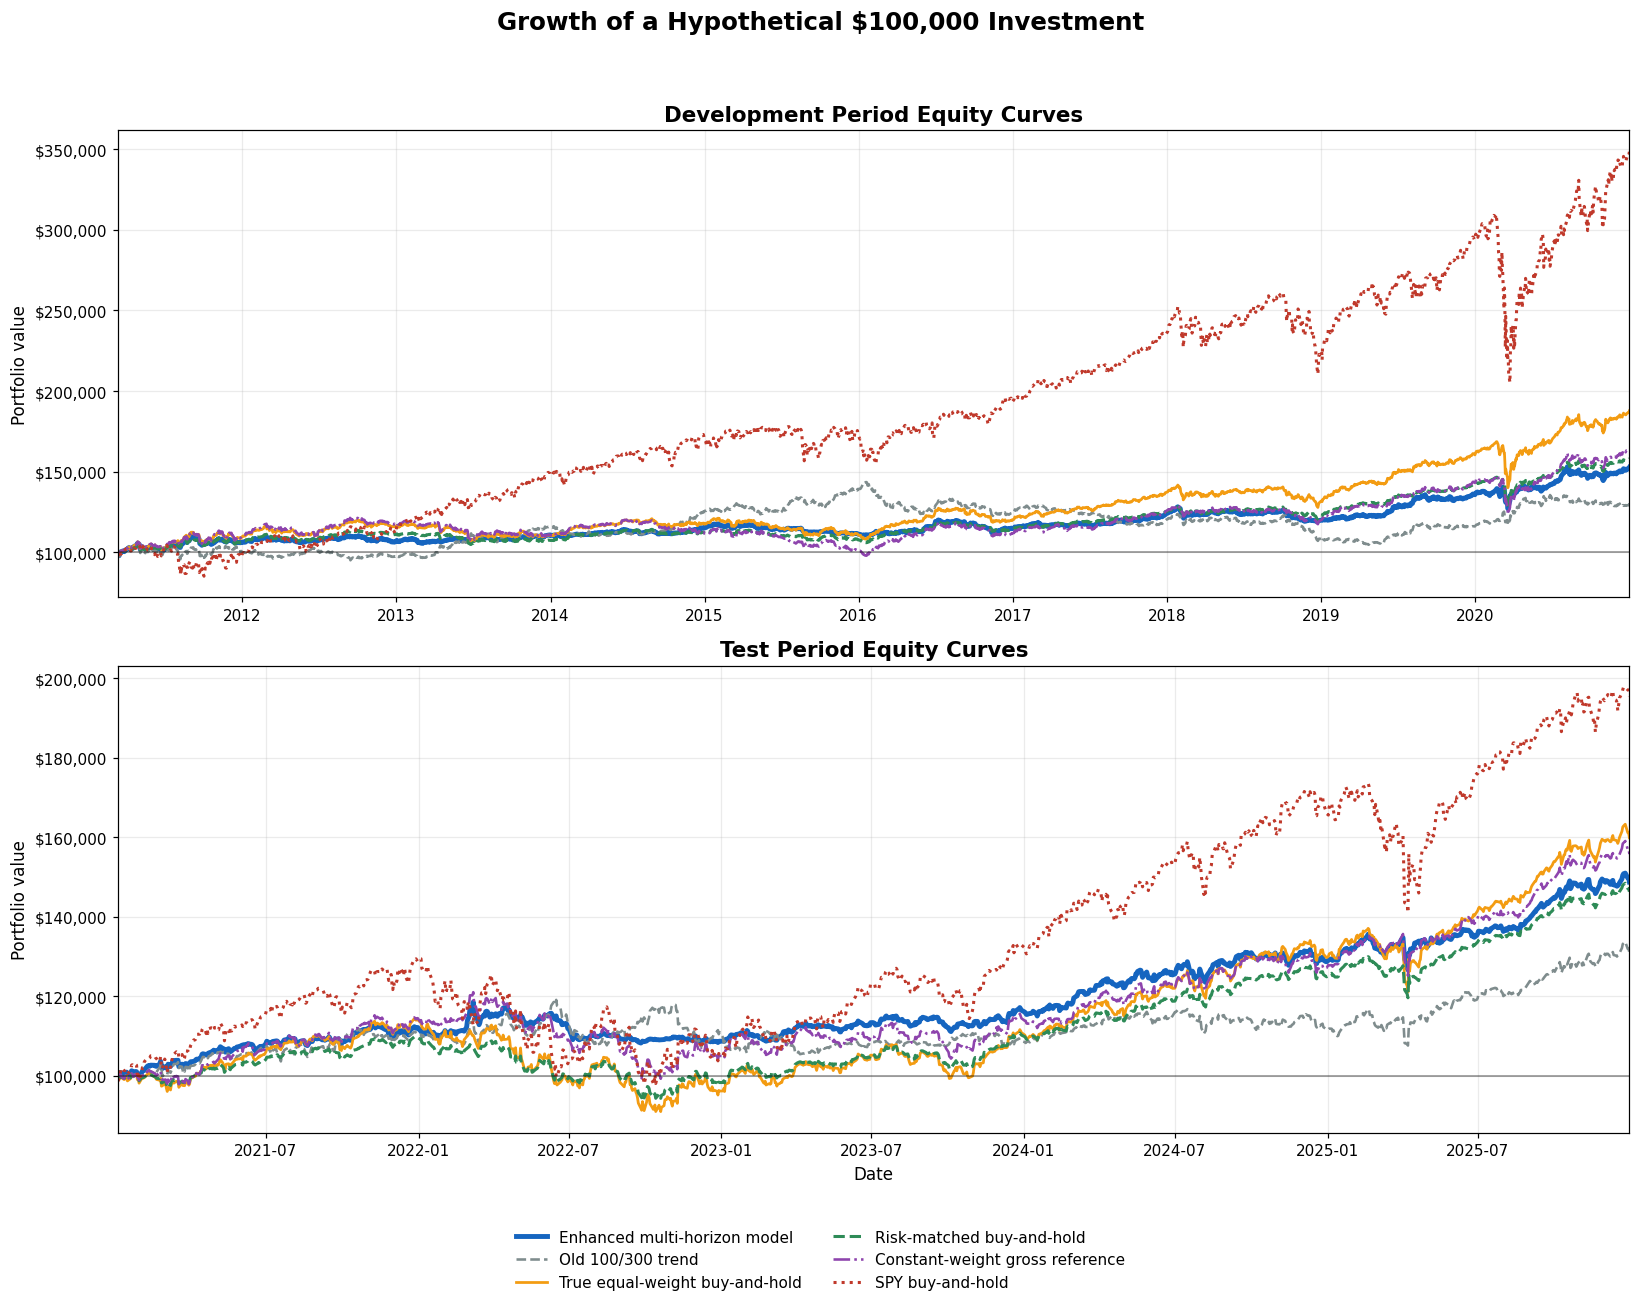

In [133]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


# Use the same visual identity for every strategy
# in both plots.
strategy_plot_styles = {
    "Enhanced multi-horizon model": {
        "color": "#1565C0",
        "linewidth": 3.2,
        "linestyle": "-"
    },

    "Old 100/300 trend": {
        "color": "#7F8C8D",
        "linewidth": 1.7,
        "linestyle": "--"
    },

    "True equal-weight buy-and-hold": {
        "color": "#F39C12",
        "linewidth": 1.8,
        "linestyle": "-"
    },

    "Risk-matched buy-and-hold": {
        "color": "#2E8B57",
        "linewidth": 2.0,
        "linestyle": "--"
    },

    "Constant-weight gross reference": {
        "color": "#8E44AD",
        "linewidth": 1.7,
        "linestyle": "-."
    },

    "SPY buy-and-hold": {
        "color": "#C0392B",
        "linewidth": 2.0,
        "linestyle": ":"
    }
}


# Format vertical-axis values as dollars.
dollar_formatter = FuncFormatter(
    lambda value, position: f"${value:,.0f}"
)


# Create two vertically arranged plotting areas.
figure, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 12)
)


# -----------------------------
# Development-period plot
# -----------------------------

for strategy_name in (
    step_25_development_equity_curves.columns
):

    plot_style = strategy_plot_styles[
        strategy_name
    ]

    axes[0].plot(
        step_25_development_equity_curves.index,
        step_25_development_equity_curves[
            strategy_name
        ],
        label=strategy_name,
        color=plot_style["color"],
        linewidth=plot_style["linewidth"],
        linestyle=plot_style["linestyle"]
    )


axes[0].axhline(
    y=step_25_starting_capital,
    color="black",
    linewidth=1.0,
    alpha=0.45
)

axes[0].set_title(
    "Development Period Equity Curves",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Portfolio value",
    fontsize=11
)

axes[0].yaxis.set_major_formatter(
    dollar_formatter
)

axes[0].grid(
    True,
    alpha=0.25
)

axes[0].margins(x=0)


# -----------------------------
# Test-period plot
# -----------------------------

for strategy_name in (
    step_25_test_equity_curves.columns
):

    plot_style = strategy_plot_styles[
        strategy_name
    ]

    axes[1].plot(
        step_25_test_equity_curves.index,
        step_25_test_equity_curves[
            strategy_name
        ],
        label=strategy_name,
        color=plot_style["color"],
        linewidth=plot_style["linewidth"],
        linestyle=plot_style["linestyle"]
    )


axes[1].axhline(
    y=step_25_starting_capital,
    color="black",
    linewidth=1.0,
    alpha=0.45
)

axes[1].set_title(
    "Test Period Equity Curves",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Date",
    fontsize=11
)

axes[1].set_ylabel(
    "Portfolio value",
    fontsize=11
)

axes[1].yaxis.set_major_formatter(
    dollar_formatter
)

axes[1].grid(
    True,
    alpha=0.25
)

axes[1].margins(x=0)


# Create one shared legend for both panels.
legend_handles, legend_labels = (
    axes[0].get_legend_handles_labels()
)

figure.legend(
    legend_handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=2,
    frameon=False,
    fontsize=10
)


figure.suptitle(
    "Growth of a Hypothetical $100,000 Investment",
    fontsize=16,
    fontweight="bold",
    y=0.99
)


figure.tight_layout(
    rect=[0, 0.09, 1, 0.96]
)


plt.show()

<a id="step-25d"></a>

### Step 25D — Analyse drawdowns and recovery

The equity curves showed how portfolio wealth changed through time.

However, they did not clearly show how much an investor would have lost after previously reaching a higher portfolio value.

A drawdown measures the decline from the portfolio's previous highest value.

#### Running peak

Let the portfolio value on day $t$ be:

$$
V_t
$$

The running peak is the highest portfolio value reached up to that date:

$$
P_t
=
\max(V_0,V_1,\ldots,V_t)
$$

where $V_0$ is the initial portfolio value.

#### Drawdown

The drawdown on day $t$ is:

$$
D_t
=
\frac{V_t}{P_t}-1
$$

The percentage drawdown is:

$$
D_t^{(\%)}
=
100\left(
\frac{V_t}{P_t}-1
\right)
$$

#### Example

Suppose a portfolio grows from \$100,000 to \$120,000 and then falls to \$108,000.

The running peak is:

$$
P_t=\$120{,}000
$$

The drawdown is:

$$
D_t
=
\frac{108{,}000}{120{,}000}-1
=
-0.10
$$

Therefore:

$$
D_t^{(\%)}=-10\%
$$

The investor is 10% below the portfolio's previous peak.

#### Drawdown is not the same as a daily loss

A daily return compares today's value with yesterday's value.

A drawdown compares today's value with the highest value previously achieved.

A portfolio can produce a positive daily return while still remaining in a drawdown.

For example, suppose the portfolio rises from \$108,000 to \$110,000 after previously reaching \$120,000.

The daily return is positive:

$$
\frac{110{,}000}{108{,}000}-1
=
1.852\%
$$

However, it remains below its previous peak:

$$
\frac{110{,}000}{120{,}000}-1
=
-8.333\%
$$

#### Maximum drawdown

Maximum drawdown is the lowest point on the complete drawdown curve:

$$
\text{Maximum drawdown}
=
\min_t D_t
$$

Because drawdowns are negative, a less negative result is preferable.

For example:

$$
-8\%>-20\%
$$

Therefore, a maximum drawdown of -8% is better than a maximum drawdown of -20%.

#### Recovery

A drawdown ends when the portfolio returns to or exceeds its previous peak.

Recovery does not simply mean that the portfolio produced one positive return. It must recover the complete cumulative loss since the previous peak.


In [134]:
def calculate_drawdown_curves(
    equity_curves,
    starting_capital=100_000
):
    """
    Calculate percentage drawdowns from a collection
    of portfolio equity curves.

    Parameters
    ----------
    equity_curves:
        DataFrame containing one portfolio-value history
        per column.

    starting_capital:
        Portfolio value immediately before the first
        recorded return.

    Returns
    -------
    DataFrame:
        Percentage drawdown history for every strategy.
    """

    # Find the highest observed value reached so far
    # separately for every strategy.
    running_peaks = (
        equity_curves
        .cummax()
    )


    # Ensure the initial capital is treated as a peak.
    #
    # This matters if a strategy loses money on the
    # first trading day.
    running_peaks = (
        running_peaks
        .clip(lower=starting_capital)
    )


    # Calculate the proportional decline from the
    # previous running peak.
    decimal_drawdowns = (
        equity_curves
        .div(running_peaks)
        -
        1.0
    )


    # Convert decimal drawdowns into percentages.
    percentage_drawdowns = (
        decimal_drawdowns
        *
        100
    )


    return percentage_drawdowns

#### Construct drawdown curves for both periods

Use each period’s equity curves and include the initial capital in the running-peak convention.


In [135]:
step_25_development_drawdown_curves = (
    calculate_drawdown_curves(
        step_25_development_equity_curves,
        starting_capital=step_25_starting_capital
    )
)


step_25_test_drawdown_curves = (
    calculate_drawdown_curves(
        step_25_test_equity_curves,
        starting_capital=step_25_starting_capital
    )
)


print(
    "Development drawdown shape:",
    step_25_development_drawdown_curves.shape
)

print(
    "Test drawdown shape:",
    step_25_test_drawdown_curves.shape
)


display(
    step_25_development_drawdown_curves.head()
)

display(
    step_25_test_drawdown_curves.head()
)

Development drawdown shape: (2469, 6)
Test drawdown shape: (1255, 6)


,Enhanced multi-horizon model,Old 100/300 trend,True equal-weight buy-and-hold,Risk-matched buy-and-hold,Constant-weight gross reference,SPY buy-and-hold
Date,,,,,,
2011-03-14,-0.042012,-0.006959,-0.028291,-0.019364,0.000000,-0.653805
2011-03-15,-1.664629,-2.047406,-1.322248,-0.909519,-1.291535,-1.792035
2011-03-16,-2.096182,-2.637340,-1.351571,-0.929653,-1.327591,-3.610133
2011-03-17,-0.945708,-1.242798,-0.343068,-0.232756,-0.291981,-2.334396
2011-03-18,-0.465832,-0.825323,0.000000,0.000000,0.000000,-1.979164


,Enhanced multi-horizon model,Old 100/300 trend,True equal-weight buy-and-hold,Risk-matched buy-and-hold,Constant-weight gross reference,SPY buy-and-hold
Date,,,,,,
2021-01-04,-0.142532,0.000000,-0.322275,-0.221600,0.000000,-1.361373
2021-01-05,0.000000,0.000000,0.000000,0.000000,0.000000,-0.682026
2021-01-06,-0.265941,-0.736489,-0.603328,-0.414952,-0.736489,-0.088247
2021-01-07,0.000000,-0.529049,-0.175807,-0.120168,-0.529049,0.000000
2021-01-08,-0.187769,-1.120975,-0.535026,-0.367321,-1.120975,0.000000


#### Validate drawdown dates, signs and values

A valid drawdown curve must satisfy the following conditions.

1. It must use the same dates as its corresponding equity curve.
2. It must contain the same strategy columns.
3. It must contain no missing values.
4. Every drawdown must be zero or negative.
5. The lowest drawdown must match the maximum drawdown previously reported in the performance table.

A drawdown of zero means:

$$
V_t=P_t
$$

The portfolio is currently at a previous peak or has reached a new peak.

A negative value means:

$$
V_t<P_t
$$

The portfolio has not yet recovered its previous highest value.


In [136]:
drawdown_curve_validation = pd.Series(
    {
        "Development dates match":
            (
                step_25_development_drawdown_curves
                .index
                .equals(
                    step_25_development_equity_curves.index
                )
            ),

        "Test dates match":
            (
                step_25_test_drawdown_curves
                .index
                .equals(
                    step_25_test_equity_curves.index
                )
            ),

        "Development columns match":
            (
                step_25_development_drawdown_curves
                .columns
                .equals(
                    step_25_development_equity_curves.columns
                )
            ),

        "Test columns match":
            (
                step_25_test_drawdown_curves
                .columns
                .equals(
                    step_25_test_equity_curves.columns
                )
            ),

        "Development contains no missing values":
            (
                step_25_development_drawdown_curves
                .notna()
                .all()
                .all()
            ),

        "Test contains no missing values":
            (
                step_25_test_drawdown_curves
                .notna()
                .all()
                .all()
            ),

        "All development drawdowns are non-positive":
            (
                step_25_development_drawdown_curves
                .le(1e-12)
                .all()
                .all()
            ),

        "All test drawdowns are non-positive":
            (
                step_25_test_drawdown_curves
                .le(1e-12)
                .all()
                .all()
            )
    },

    name="Passed"
)


display(
    drawdown_curve_validation.to_frame()
)

,Passed
Development dates match,True
Test dates match,True
Development columns match,True
Test columns match,True
Development contains no missing values,True
Test contains no missing values,True
All development drawdowns are non-positive,True
All test drawdowns are non-positive,True


#### Reconcile drawdown minima with the metric tables

The minimum of each drawdown curve should agree with that strategy’s reported maximum drawdown over the same period.


In [137]:
# The lowest point in each drawdown curve.
development_curve_maximum_drawdowns = (
    step_25_development_drawdown_curves
    .min()
)

test_curve_maximum_drawdowns = (
    step_25_test_drawdown_curves
    .min()
)


# Maximum drawdowns previously reported by the
# corrected metric tables.
development_reported_maximum_drawdowns = (
    step_25_development_metrics_corrected[
        "Maximum drawdown (%)"
    ]
)

test_reported_maximum_drawdowns = (
    step_25_test_metrics_corrected[
        "Maximum drawdown (%)"
    ]
)


step_25_drawdown_metric_validation = pd.DataFrame(
    {
        "Development curve minimum":
            development_curve_maximum_drawdowns,

        "Development reported value":
            development_reported_maximum_drawdowns,

        "Development difference":
            (
                development_curve_maximum_drawdowns
                -
                development_reported_maximum_drawdowns
            ),

        "Test curve minimum":
            test_curve_maximum_drawdowns,

        "Test reported value":
            test_reported_maximum_drawdowns,

        "Test difference":
            (
                test_curve_maximum_drawdowns
                -
                test_reported_maximum_drawdowns
            )
    }
)


display(
    step_25_drawdown_metric_validation.round(6)
)


print(
    "Development maximum drawdowns match:",
    (
        step_25_drawdown_metric_validation[
            "Development difference"
        ]
        .abs()
        .max()
        <
        1e-8
    )
)

print(
    "Test maximum drawdowns match:",
    (
        step_25_drawdown_metric_validation[
            "Test difference"
        ]
        .abs()
        .max()
        <
        1e-8
    )
)

,Development curve minimum,Development reported value,Development difference,Test curve minimum,Test reported value,Test difference
Enhanced multi-horizon model,-9.568219,-9.568219,0.0,-8.701747,-8.701747,0.0
Old 100/300 trend,-27.092547,-27.092547,0.0,-11.472559,-11.472559,0.0
True equal-weight buy-and-hold,-16.943036,-16.943036,0.0,-20.479858,-20.479858,0.0
Risk-matched buy-and-hold,-11.887773,-11.887773,0.0,-14.101376,-14.101376,0.0
Constant-weight gross reference,-19.429401,-19.429401,0.0,-18.002745,-18.002745,-0.0
SPY buy-and-hold,-33.717259,-33.717259,0.0,-24.496401,-24.496401,0.0


Development maximum drawdowns match: True
Test maximum drawdowns match: True


#### Identify the maximum-drawdown episodes

A maximum-drawdown number tells us the depth of the worst loss, but not when it happened or how long it lasted.

Each drawdown episode contains three important dates.

##### Peak date

The portfolio reaches its highest value before the decline.

##### Trough date

The portfolio reaches the lowest point of the drawdown.

##### Recovery date

The portfolio returns to or exceeds the previous peak.

We also calculate:

- Peak-to-trough trading days.
- Trough-to-recovery trading days.
- Total peak-to-recovery trading days.

These are trading-day counts rather than calendar-day counts. Weekends and market holidays are not included.

If a portfolio does not recover before the end of the evaluation period, its recovery date remains missing.

The function reports the episode containing the most negative drawdown, not necessarily the longest drawdown episode. Durations are index-position differences, so a 28-day episode means 28 trading intervals. A missing recovery date means the episode had not recovered within the observed period. The helper includes initial capital in the peak and uses the latest occurrence of a repeated peak. When the relevant peak is initial capital before the first observation, `Peak before sample` is true and `Peak date` is missing. Its index position is -1 for counting trading intervals. A series without a drawdown has no episode dates and zero episode durations.


In [138]:
def summarize_maximum_drawdown_episodes(
    equity_curves,
    drawdown_curves,
    starting_capital=100_000,
):
    """Find each worst drawdown, including a peak before the sample."""
    if (
        equity_curves.empty
        or not equity_curves.index.equals(drawdown_curves.index)
        or not equity_curves.columns.equals(drawdown_curves.columns)
        or not equity_curves.index.is_unique
        or not equity_curves.index.is_monotonic_increasing
        or not equity_curves.columns.is_unique
    ):
        raise ValueError("Use non-empty, aligned curves with unique sorted dates.")
    if not np.isfinite(starting_capital) or starting_capital <= 0:
        raise ValueError("Starting capital must be positive and finite.")

    rows = []

    for strategy_name in equity_curves.columns:
        equity = equity_curves[strategy_name]
        drawdown = drawdown_curves[strategy_name]

        if (
            not np.isfinite(equity.to_numpy()).all()
            or not np.isfinite(drawdown.to_numpy()).all()
            or (equity <= 0).any()
        ):
            raise ValueError("Equity must be positive and all values finite.")

        expected_drawdown = (
            equity / equity.cummax().clip(lower=starting_capital) - 1
        ) * 100
        if not np.allclose(
            drawdown, expected_drawdown, rtol=1e-10, atol=1e-10
        ):
            raise ValueError("Drawdowns must use the supplied starting capital.")

        trough_position = int(drawdown.argmin())
        maximum_drawdown = float(drawdown.iloc[trough_position])

        if maximum_drawdown >= 0:
            # No decline occurred, so there is no drawdown episode.
            peak_date = trough_date = recovery_date = pd.NaT
            peak_before_sample = False
            peak_to_trough = trough_to_recovery = total_days = 0

        else:
            trough_date = equity.index[trough_position]
            preceding_values = equity.iloc[:trough_position + 1].to_numpy()
            peak_value = max(starting_capital, preceding_values.max())

            # Use the latest occurrence of the preceding peak.
            peak_positions = np.flatnonzero(preceding_values == peak_value)
            peak_position = (
                int(peak_positions[-1]) if peak_positions.size else -1
            )
            peak_before_sample = peak_position == -1
            peak_date = (
                pd.NaT if peak_before_sample else equity.index[peak_position]
            )
            peak_to_trough = trough_position - peak_position

            # Recovery requires regaining the entire preceding peak.
            recovery_offsets = np.flatnonzero(
                equity.iloc[trough_position:].to_numpy() >= peak_value
            )

            if recovery_offsets.size:
                recovery_position = (
                    trough_position + int(recovery_offsets[0])
                )
                recovery_date = equity.index[recovery_position]
                trough_to_recovery = recovery_position - trough_position
                total_days = recovery_position - peak_position
            else:
                recovery_date = pd.NaT
                trough_to_recovery = total_days = None

        rows.append({
            "Strategy": strategy_name,
            "Maximum drawdown (%)": maximum_drawdown,
            "Peak date": peak_date,
            "Peak before sample": peak_before_sample,
            "Trough date": trough_date,
            "Recovery date": recovery_date,
            "Peak-to-trough trading days": peak_to_trough,
            "Trough-to-recovery trading days": trough_to_recovery,
            "Total episode trading days": total_days,
        })

    return pd.DataFrame(rows).set_index("Strategy")


#### Summarise peak, trough and recovery dates

Report each strategy’s worst-depth episode separately for development and testing. Missing recovery fields indicate an episode still open at the sample end.


In [139]:
step_25_development_drawdown_summary = (
    summarize_maximum_drawdown_episodes(
        step_25_development_equity_curves,
        step_25_development_drawdown_curves
    )
)


step_25_test_drawdown_summary = (
    summarize_maximum_drawdown_episodes(
        step_25_test_equity_curves,
        step_25_test_drawdown_curves
    )
)


print(
    "Development maximum-drawdown episodes"
)

display(
    step_25_development_drawdown_summary.round({column: 3 for column in step_25_development_drawdown_summary.select_dtypes(include="number").columns})
)


print(
    "Test maximum-drawdown episodes"
)

display(
    step_25_test_drawdown_summary.round({column: 3 for column in step_25_test_drawdown_summary.select_dtypes(include="number").columns})
)

Development maximum-drawdown episodes


,Maximum drawdown (%),Peak date,Peak before sample,Trough date,Recovery date,Peak-to-trough trading days,Trough-to-recovery trading days,Total episode trading days
Strategy,,,,,,,,
Enhanced multi-horizon model,-9.568,2020-03-06,False,2020-03-19,2020-04-16,9,19.0,28.0
Old 100/300 trend,-27.093,2016-01-19,False,2019-04-23,NaT,820,NaN,NaN
True equal-weight buy-and-hold,-16.943,2020-02-21,False,2020-03-18,2020-06-08,18,56.0,74.0
Risk-matched buy-and-hold,-11.888,2020-02-21,False,2020-03-18,2020-06-08,18,56.0,74.0
Constant-weight gross reference,-19.429,2012-10-04,False,2016-01-19,2017-09-07,825,413.0,1238.0
SPY buy-and-hold,-33.717,2020-02-19,False,2020-03-23,2020-08-10,23,97.0,120.0


Test maximum-drawdown episodes


,Maximum drawdown (%),Peak date,Peak before sample,Trough date,Recovery date,Peak-to-trough trading days,Trough-to-recovery trading days,Total episode trading days
Strategy,,,,,,,,
Enhanced multi-horizon model,-8.702,2022-03-08,False,2022-09-26,2024-03-01,139,359,498
Old 100/300 trend,-11.473,2022-06-16,False,2023-04-06,2025-06-11,202,546,748
True equal-weight buy-and-hold,-20.480,2021-12-27,False,2022-10-20,2024-03-01,206,341,547
Risk-matched buy-and-hold,-14.101,2021-12-27,False,2022-10-14,2023-12-19,202,296,498
Constant-weight gross reference,-18.003,2022-03-08,False,2022-10-20,2024-04-08,157,366,523
SPY buy-and-hold,-24.496,2022-01-03,False,2022-10-12,2023-12-13,195,294,489


#### Read the drawdown-curve comparison

Every curve begins at or below zero.

A value of zero means that the portfolio is at a running peak.

A movement below zero represents a loss from the previous peak.

The further a curve falls, the more severe the drawdown.

The enhanced strategy uses the same blue line as in the equity-curve plots. Its drawdown area is lightly shaded so its behaviour can be followed across the complete period.

All six strategies remain visible. This preserves the full comparison rather than removing benchmarks that experienced larger losses.


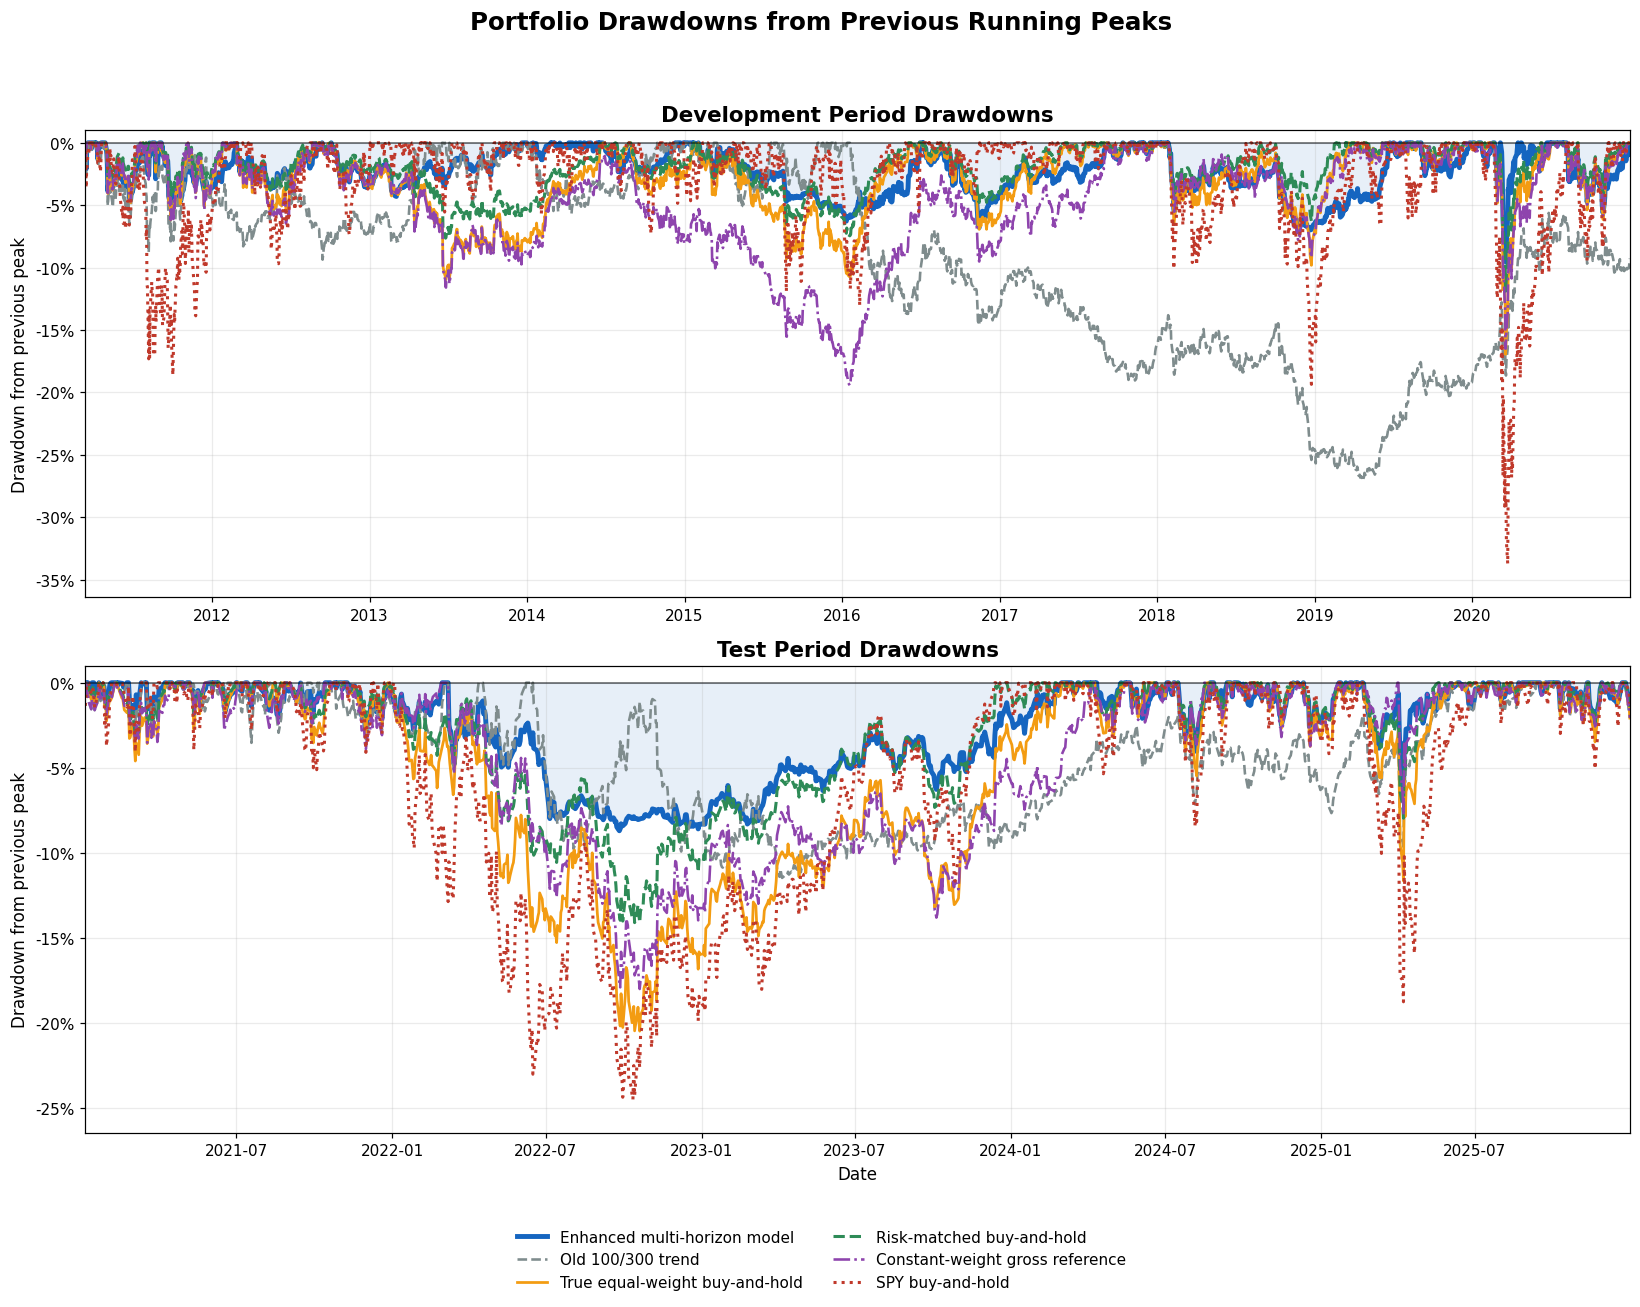

In [140]:
from matplotlib.ticker import FuncFormatter


percentage_formatter = FuncFormatter(
    lambda value, position: f"{value:.0f}%"
)


figure, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 12)
)


# -----------------------------
# Development-period drawdowns
# -----------------------------

for strategy_name in (
    step_25_development_drawdown_curves.columns
):

    plot_style = strategy_plot_styles[
        strategy_name
    ]

    axes[0].plot(
        step_25_development_drawdown_curves.index,
        step_25_development_drawdown_curves[
            strategy_name
        ],
        label=strategy_name,
        color=plot_style["color"],
        linewidth=plot_style["linewidth"],
        linestyle=plot_style["linestyle"]
    )


# Shade the enhanced model's drawdown area.
axes[0].fill_between(
    step_25_development_drawdown_curves.index,
    step_25_development_drawdown_curves[
        "Enhanced multi-horizon model"
    ],
    0,
    color=strategy_plot_styles[
        "Enhanced multi-horizon model"
    ]["color"],
    alpha=0.10
)


axes[0].axhline(
    y=0,
    color="black",
    linewidth=1.0,
    alpha=0.6
)

axes[0].set_title(
    "Development Period Drawdowns",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Drawdown from previous peak",
    fontsize=11
)

axes[0].yaxis.set_major_formatter(
    percentage_formatter
)

axes[0].set_ylim(
    bottom=(
        step_25_development_drawdown_curves
        .min()
        .min()
        *
        1.08
    ),
    top=1
)

axes[0].grid(
    True,
    alpha=0.25
)

axes[0].margins(x=0)


# -----------------------------
# Test-period drawdowns
# -----------------------------

for strategy_name in (
    step_25_test_drawdown_curves.columns
):

    plot_style = strategy_plot_styles[
        strategy_name
    ]

    axes[1].plot(
        step_25_test_drawdown_curves.index,
        step_25_test_drawdown_curves[
            strategy_name
        ],
        label=strategy_name,
        color=plot_style["color"],
        linewidth=plot_style["linewidth"],
        linestyle=plot_style["linestyle"]
    )


axes[1].fill_between(
    step_25_test_drawdown_curves.index,
    step_25_test_drawdown_curves[
        "Enhanced multi-horizon model"
    ],
    0,
    color=strategy_plot_styles[
        "Enhanced multi-horizon model"
    ]["color"],
    alpha=0.10
)


axes[1].axhline(
    y=0,
    color="black",
    linewidth=1.0,
    alpha=0.6
)

axes[1].set_title(
    "Test Period Drawdowns",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Date",
    fontsize=11
)

axes[1].set_ylabel(
    "Drawdown from previous peak",
    fontsize=11
)

axes[1].yaxis.set_major_formatter(
    percentage_formatter
)

axes[1].set_ylim(
    bottom=(
        step_25_test_drawdown_curves
        .min()
        .min()
        *
        1.08
    ),
    top=1
)

axes[1].grid(
    True,
    alpha=0.25
)

axes[1].margins(x=0)


# Use one shared legend for both panels.
legend_handles, legend_labels = (
    axes[0].get_legend_handles_labels()
)

figure.legend(
    legend_handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=2,
    frameon=False,
    fontsize=10
)


figure.suptitle(
    "Portfolio Drawdowns from Previous Running Peaks",
    fontsize=16,
    fontweight="bold",
    y=0.99
)


figure.tight_layout(
    rect=[0, 0.09, 1, 0.96]
)


plt.show()

#### Interpret drawdown depth and recovery duration

All drawdown validation checks passed. The drawdown-curve minimums exactly matched the maximum drawdowns reported by the performance tables.

The enhanced multi-horizon model produced the smallest maximum drawdown in both evaluation periods:

- Development maximum drawdown: -9.568%.
- Test maximum drawdown: -8.702%.

During the 2020 market decline, the enhanced model fell by 9.568% and completed its maximum-drawdown episode in 28 trading days. SPY fell by 33.717% and required 120 trading days to complete its corresponding episode.

During testing, the enhanced model's worst drawdown began on 8 March 2022, reached its trough on 26 September 2022 and recovered on 1 March 2024.

Compared with the test-period benchmarks, the enhanced model improved maximum drawdown by:

- 5.400 percentage points relative to risk-matched buy-and-hold.
- 11.778 percentage points relative to true equal-weight buy-and-hold.
- 15.795 percentage points relative to SPY buy-and-hold.
- 2.771 percentage points relative to the old 100/300 trend strategy.

The enhanced model nevertheless remained below its previous peak for 498 trading days. This shows that controlling drawdown depth does not guarantee immediate recovery.

The drawdown analysis supports describing the model as a risk-managed multi-asset momentum strategy. Its worst observed loss was shallower in each of the two evaluation periods, although it did not eliminate prolonged periods below previous portfolio peaks. These comparisons concern each strategy’s own maximum-drawdown episode, not identical peak and trough dates.


<a id="step-26"></a>

## Step 26 — Robustness analysis

<a id="step-26a"></a>

### Step 26A — Anchored annual pseudo-walk-forward evaluation

A single development/test split can conceal instability. A strategy may appear successful over the complete test period even if most of its performance came from one unusually favourable year.

The test period is therefore divided into five chronological annual folds:

- 2021
- 2022
- 2023
- 2024
- 2025

For every fold, the training window contains only observations that occurred before the test year. The training window expands as time moves forward.

The enhanced strategy remains completely frozen. Its assets, moving-average horizons, volatility window, transaction cost and allocation rules are not re-optimised.

Past data is used only to calculate that year's risk-matched buy-and-hold multiplier. Consequently, the risk-matched benchmark cannot use the test year's volatility in advance.

For every annual test fold, the analysis calculates:

- Total return
- CAGR
- Annualised mean return
- Annualised volatility
- Corrected excess-return Sharpe ratio
- Maximum drawdown

This is an anchored pseudo-walk-forward analysis. It tests chronological stability, but it is not presented as a pristine live out-of-sample experiment because the enhanced strategy was designed after parts of the historical sample had already been examined.

The expanding historical window is used to calibrate the passive benchmark, not to refit the enhanced strategy. Annual drawdowns are measured within each annual fold, so they do not describe recovery durations that cross year boundaries.


In [141]:
# Step 26A-1:
# Construct annual anchored walk-forward folds.

step_26_enhanced_name = (
    "Enhanced multi-horizon model"
)

step_26_true_buy_hold_name = (
    "True equal-weight buy-and-hold"
)

step_26_risk_matched_name = (
    "Risk-matched buy-and-hold"
)


# Use the complete comparison index created in Step 25.
step_26_all_dates = pd.DatetimeIndex(
    step_25_comparison_returns.index
)


# The walk-forward test years come directly from the
# original test-period dates.
step_26_test_years = sorted(
    pd.DatetimeIndex(
        multi_horizon_test_dates
    )
    .year
    .unique()
    .tolist()
)


step_26_walk_forward_folds = {}
step_26_fold_definition_rows = []


for test_year in step_26_test_years:

    fold_start = pd.Timestamp(
        year=test_year,
        month=1,
        day=1
    )

    fold_end = pd.Timestamp(
        year=test_year,
        month=12,
        day=31
    )


    # The anchored training window contains every
    # available observation before the test year.
    training_dates = step_26_all_dates[
        step_26_all_dates < fold_start
    ]


    # The test window contains only the current year.
    test_dates = step_26_all_dates[
        (
            step_26_all_dates >= fold_start
        )
        &
        (
            step_26_all_dates <= fold_end
        )
    ]


    step_26_walk_forward_folds[test_year] = {
        "training_dates": training_dates,
        "test_dates": test_dates
    }


    step_26_fold_definition_rows.append(
        {
            "Test year": test_year,
            "Training start": training_dates.min(),
            "Training end": training_dates.max(),
            "Training observations": len(training_dates),
            "Test start": test_dates.min(),
            "Test end": test_dates.max(),
            "Test observations": len(test_dates)
        }
    )


step_26_walk_forward_fold_table = (
    pd.DataFrame(
        step_26_fold_definition_rows
    )
    .set_index("Test year")
)


# Combine all annual test dates so that we can prove
# that they reproduce the original test period exactly.
step_26_covered_test_dates = pd.DatetimeIndex(
    [
        date
        for test_year in step_26_test_years
        for date in (
            step_26_walk_forward_folds[
                test_year
            ]["test_dates"]
        )
    ]
)


step_26_expected_test_dates = pd.DatetimeIndex(
    multi_horizon_test_dates
)


step_26_walk_forward_setup_validation = pd.Series(
    {
        "Comparison dates are sorted":
            step_26_all_dates.is_monotonic_increasing,

        "Comparison dates are unique":
            step_26_all_dates.is_unique,

        "Five annual test folds created":
            len(step_26_test_years) == 5,

        "Test years are 2021 through 2025":
            step_26_test_years
            ==
            [2021, 2022, 2023, 2024, 2025],

        "Annual folds reproduce full test period":
            step_26_covered_test_dates.equals(
                step_26_expected_test_dates
            ),

        "No test date appears twice":
            step_26_covered_test_dates.is_unique,

        "Every training period ends before testing":
            all(
                fold["training_dates"].max()
                <
                fold["test_dates"].min()

                for fold in (
                    step_26_walk_forward_folds.values()
                )
            ),

        "Every test fold has at least 240 observations":
            all(
                len(fold["test_dates"]) >= 240

                for fold in (
                    step_26_walk_forward_folds.values()
                )
            ),

        "Comparison returns contain no missing values":
            step_25_comparison_returns
            .notna()
            .all()
            .all(),

        "Risk-free rates contain no missing values":
            step_25_daily_risk_free_rate
            .notna()
            .all()
    },

    name="Passed"
)


print("Anchored walk-forward fold definitions")

display(
    step_26_walk_forward_fold_table
)


print("Walk-forward setup validation")

display(
    step_26_walk_forward_setup_validation
    .to_frame()
)

Anchored walk-forward fold definitions


,Training start,Training end,Training observations,Test start,Test end,Test observations
Test year,,,,,,
2021,2011-03-14,2020-12-31,2469,2021-01-04,2021-12-31,252
2022,2011-03-14,2021-12-31,2721,2022-01-03,2022-12-30,251
2023,2011-03-14,2022-12-30,2972,2023-01-03,2023-12-29,250
2024,2011-03-14,2023-12-29,3222,2024-01-02,2024-12-31,252
2025,2011-03-14,2024-12-31,3474,2025-01-02,2025-12-31,250


Walk-forward setup validation


,Passed
Comparison dates are sorted,True
Comparison dates are unique,True
Five annual test folds created,True
Test years are 2021 through 2025,True
Annual folds reproduce full test period,True
No test date appears twice,True
Every training period ends before testing,True
Every test fold has at least 240 observations,True
Comparison returns contain no missing values,True
Risk-free rates contain no missing values,True


In [142]:
# Step 26A-2:
# Calculate walk-forward metrics using the frozen strategy.

step_26_walk_forward_metric_tables = {}

step_26_walk_forward_test_return_tables = {}

step_26_risk_multiplier_rows = []


for test_year in step_26_test_years:

    training_dates = (
        step_26_walk_forward_folds[
            test_year
        ]["training_dates"]
    )

    test_dates = (
        step_26_walk_forward_folds[
            test_year
        ]["test_dates"]
    )


    # Estimate the enhanced strategy's volatility using
    # only information available before the test year.
    enhanced_training_volatility = (
        step_25_comparison_returns.loc[
            training_dates,
            step_26_enhanced_name
        ]
        .std(ddof=1)
        *
        np.sqrt(252)
    )


    # Estimate equal-weight buy-and-hold volatility using
    # exactly the same past-only training dates.
    buy_hold_training_volatility = (
        step_25_comparison_returns.loc[
            training_dates,
            step_26_true_buy_hold_name
        ]
        .std(ddof=1)
        *
        np.sqrt(252)
    )


    # This multiplier is locked before the test year begins.
    fold_risk_multiplier = (
        enhanced_training_volatility
        /
        buy_hold_training_volatility
    )


    assert np.isfinite(
        fold_risk_multiplier
    )

    assert fold_risk_multiplier > 0


    # Copy that year's original comparison returns.
    fold_test_returns = (
        step_25_comparison_returns.loc[
            test_dates
        ]
        .copy()
    )


    fold_test_risk_free_rate = (
        step_25_daily_risk_free_rate.loc[
            test_dates
        ]
    )


    # Reconstruct the risk-matched benchmark using only
    # the multiplier estimated before this test year.
    fold_test_returns[
        step_26_risk_matched_name
    ] = (
        fold_test_risk_free_rate
        +
        fold_risk_multiplier
        *
        (
            fold_test_returns[
                step_26_true_buy_hold_name
            ]
            -
            fold_test_risk_free_rate
        )
    )


    # Calculate the established project metrics.
    fold_metric_table = (
        calculate_step_25_metrics(
            fold_test_returns,
            test_dates
        )
    )


    # Replace the old return-to-volatility ratio with the
    # corrected excess-return Sharpe ratio.
    fold_corrected_sharpe = (
        calculate_excess_sharpe_ratios(
            fold_test_returns,
            step_25_daily_risk_free_rate,
            test_dates
        )
    )


    fold_metric_table[
        "Corrected Sharpe ratio"
    ] = fold_corrected_sharpe


    # Remove the older zero-risk-free-rate version.
    fold_metric_table = (
        fold_metric_table
        .drop(
            columns="Sharpe ratio"
        )
    )


    # Keep a consistent final column order.
    fold_metric_table = fold_metric_table[
        [
            "Total return (%)",
            "CAGR (%)",
            "Annualized mean return (%)",
            "Annualized volatility (%)",
            "Corrected Sharpe ratio",
            "Maximum drawdown (%)"
        ]
    ]


    step_26_walk_forward_metric_tables[
        test_year
    ] = fold_metric_table


    step_26_walk_forward_test_return_tables[
        test_year
    ] = fold_test_returns


    step_26_risk_multiplier_rows.append(
        {
            "Test year": test_year,

            "Training end":
                training_dates.max(),

            "Enhanced training volatility (%)":
                enhanced_training_volatility * 100,

            "Buy-and-hold training volatility (%)":
                buy_hold_training_volatility * 100,

            "Past-only risk multiplier":
                fold_risk_multiplier
        }
    )


# Combine all five metric tables.
step_26_walk_forward_metrics = pd.concat(
    step_26_walk_forward_metric_tables,
    names=[
        "Test year",
        "Strategy"
    ]
)


step_26_walk_forward_risk_multipliers = (
    pd.DataFrame(
        step_26_risk_multiplier_rows
    )
    .set_index("Test year")
)


# Extract the enhanced strategy's five annual results.
step_26_enhanced_fold_results = (
    step_26_walk_forward_metrics
    .xs(
        step_26_enhanced_name,
        level="Strategy"
    )
)


# Compare the enhanced strategy with every benchmark
# across all five test folds.
step_26_walk_forward_comparison_rows = {}


for benchmark_name in (
    step_25_comparison_returns.columns
):

    if benchmark_name == step_26_enhanced_name:
        continue


    benchmark_fold_results = (
        step_26_walk_forward_metrics
        .xs(
            benchmark_name,
            level="Strategy"
        )
    )


    step_26_walk_forward_comparison_rows[
        benchmark_name
    ] = {
        "Higher total return (folds)":
            (
                step_26_enhanced_fold_results[
                    "Total return (%)"
                ]
                >
                benchmark_fold_results[
                    "Total return (%)"
                ]
            ).sum(),

        "Higher corrected Sharpe (folds)":
            (
                step_26_enhanced_fold_results[
                    "Corrected Sharpe ratio"
                ]
                >
                benchmark_fold_results[
                    "Corrected Sharpe ratio"
                ]
            ).sum(),

        "Lower volatility (folds)":
            (
                step_26_enhanced_fold_results[
                    "Annualized volatility (%)"
                ]
                <
                benchmark_fold_results[
                    "Annualized volatility (%)"
                ]
            ).sum(),

        "Smaller maximum drawdown (folds)":
            (
                step_26_enhanced_fold_results[
                    "Maximum drawdown (%)"
                ]
                >
                benchmark_fold_results[
                    "Maximum drawdown (%)"
                ]
            ).sum(),

        "Mean total-return advantage (pp)":
            (
                step_26_enhanced_fold_results[
                    "Total return (%)"
                ]
                -
                benchmark_fold_results[
                    "Total return (%)"
                ]
            ).mean(),

        "Mean corrected-Sharpe advantage":
            (
                step_26_enhanced_fold_results[
                    "Corrected Sharpe ratio"
                ]
                -
                benchmark_fold_results[
                    "Corrected Sharpe ratio"
                ]
            ).mean(),

        "Mean drawdown improvement (pp)":
            (
                step_26_enhanced_fold_results[
                    "Maximum drawdown (%)"
                ]
                -
                benchmark_fold_results[
                    "Maximum drawdown (%)"
                ]
            ).mean()
    }


step_26_walk_forward_comparison = (
    pd.DataFrame.from_dict(
        step_26_walk_forward_comparison_rows,
        orient="index"
    )
)


step_26_walk_forward_result_validation = pd.Series(
    {
        "Five metric tables created":
            len(
                step_26_walk_forward_metric_tables
            )
            == 5,

        "No missing walk-forward metrics":
            step_26_walk_forward_metrics
            .notna()
            .all()
            .all(),

        "All test returns can be compounded":
            all(
                (
                    return_table > -1
                )
                .all()
                .all()

                for return_table in (
                    step_26_walk_forward_test_return_tables
                    .values()
                )
            ),

        "All risk multipliers are positive":
            (
                step_26_walk_forward_risk_multipliers[
                    "Past-only risk multiplier"
                ]
                >
                0
            )
            .all(),

        "Every strategy has five fold results":
            all(
                len(
                    step_26_walk_forward_metrics
                    .xs(
                        strategy_name,
                        level="Strategy"
                    )
                )
                == 5

                for strategy_name in (
                    step_25_comparison_returns.columns
                )
            )
    },

    name="Passed"
)


print("Past-only risk-matched benchmark multipliers")

display(
    step_26_walk_forward_risk_multipliers
    .round({column: 3 for column in step_26_walk_forward_risk_multipliers.select_dtypes(include="number").columns})
)


print("Enhanced strategy annual walk-forward results")

display(
    step_26_enhanced_fold_results
    .round(3)
)


print("Enhanced strategy consistency against benchmarks")

display(
    step_26_walk_forward_comparison
    .round(3)
)


print("Walk-forward result validation")

display(
    step_26_walk_forward_result_validation
    .to_frame()
)

Past-only risk-matched benchmark multipliers


,Training end,Enhanced training volatility (%),Buy-and-hold training volatility (%),Past-only risk multiplier
Test year,,,,
2021,2020-12-31,5.699,8.283,0.688
2022,2021-12-31,5.759,8.293,0.695
2023,2022-12-30,5.891,9.093,0.648
2024,2023-12-29,5.824,9.113,0.639
2025,2024-12-31,5.920,9.122,0.649


Enhanced strategy annual walk-forward results


,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Corrected Sharpe ratio,Maximum drawdown (%)
Test year,,,,,,
2021,12.140,12.140,11.660,6.323,1.837,-2.850
2022,-3.077,-3.089,-2.882,7.157,-0.689,-8.702
2023,7.161,7.220,7.095,4.977,0.392,-3.421
2024,10.495,10.495,10.228,7.033,0.736,-4.041
2025,15.573,15.707,14.914,8.027,1.345,-6.609


Enhanced strategy consistency against benchmarks


,Higher total return (folds),Higher corrected Sharpe (folds),Lower volatility (folds),Smaller maximum drawdown (folds),Mean total-return advantage (pp),Mean corrected-Sharpe advantage,Mean drawdown improvement (pp)
Old 100/300 trend,3,4,5,5,2.688,0.501,1.256
True equal-weight buy-and-hold,1,2,5,5,-2.328,-0.086,4.862
Risk-matched buy-and-hold,2,2,3,4,0.453,-0.086,1.482
Constant-weight gross reference,1,3,5,4,-1.303,-0.010,3.134
SPY buy-and-hold,1,2,5,5,-7.409,-0.243,8.225


Walk-forward result validation


,Passed
Five metric tables created,True
No missing walk-forward metrics,True
All test returns can be compounded,True
All risk multipliers are positive,True
Every strategy has five fold results,True


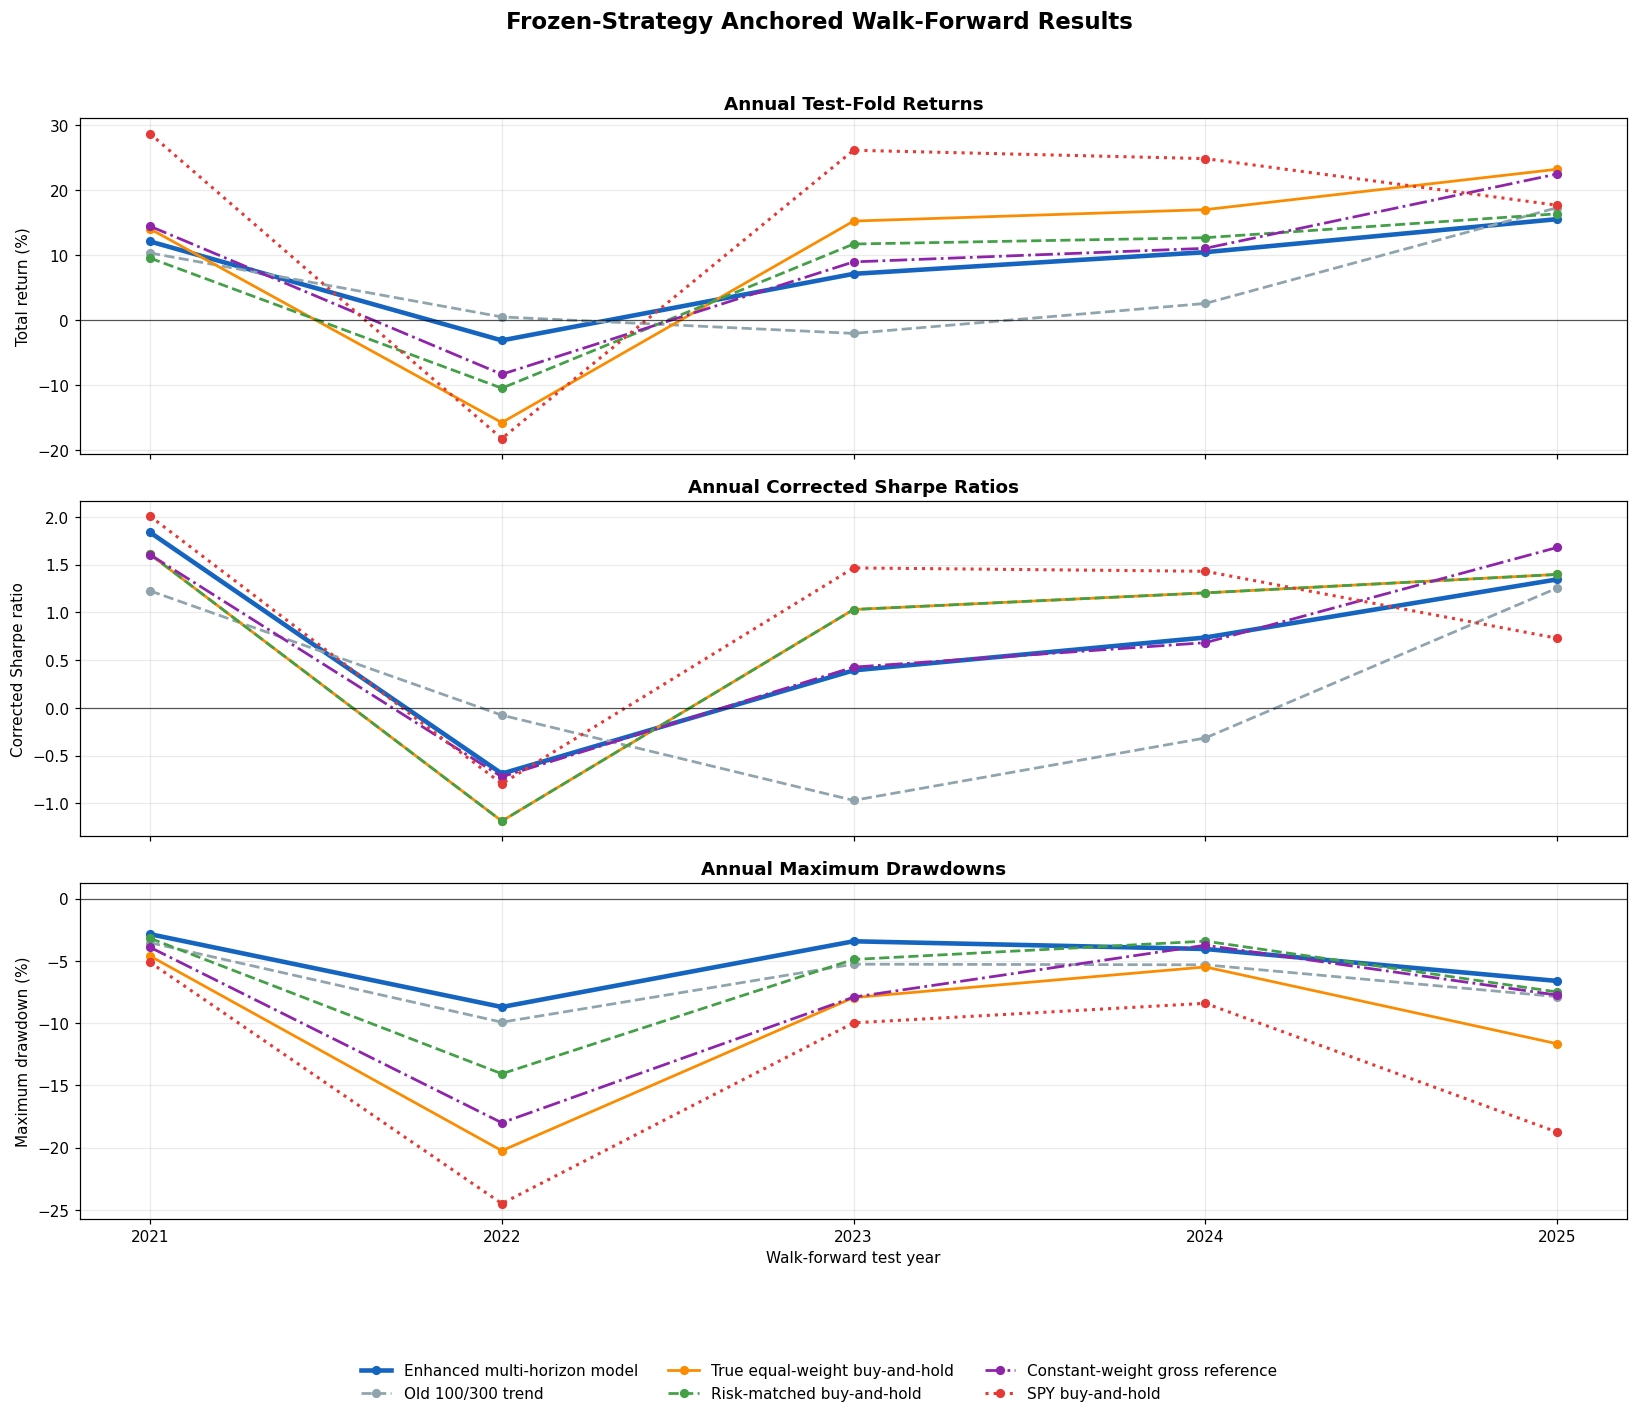

In [143]:
# Step 26A-3:
# Visualize performance across the five test folds.

step_26_plot_styles = {
    "Enhanced multi-horizon model": {
        "color": "#1565C0",
        "linewidth": 3.0,
        "linestyle": "-"
    },

    "Old 100/300 trend": {
        "color": "#90A4AE",
        "linewidth": 1.8,
        "linestyle": "--"
    },

    "True equal-weight buy-and-hold": {
        "color": "#FB8C00",
        "linewidth": 1.8,
        "linestyle": "-"
    },

    "Risk-matched buy-and-hold": {
        "color": "#43A047",
        "linewidth": 1.8,
        "linestyle": "--"
    },

    "Constant-weight gross reference": {
        "color": "#8E24AA",
        "linewidth": 1.8,
        "linestyle": "-."
    },

    "SPY buy-and-hold": {
        "color": "#E53935",
        "linewidth": 2.0,
        "linestyle": ":"
    }
}


fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 13),
    sharex=True
)


step_26_plot_metrics = [
    (
        "Total return (%)",
        "Annual Test-Fold Returns",
        "Total return (%)"
    ),

    (
        "Corrected Sharpe ratio",
        "Annual Corrected Sharpe Ratios",
        "Corrected Sharpe ratio"
    ),

    (
        "Maximum drawdown (%)",
        "Annual Maximum Drawdowns",
        "Maximum drawdown (%)"
    )
]


for axis, (
    metric_name,
    panel_title,
    y_axis_label
) in zip(
    axes,
    step_26_plot_metrics
):

    for strategy_name in (
        step_25_comparison_returns.columns
    ):

        strategy_fold_results = (
            step_26_walk_forward_metrics
            .xs(
                strategy_name,
                level="Strategy"
            )
            .sort_index()
        )


        style = step_26_plot_styles[
            strategy_name
        ]


        axis.plot(
            strategy_fold_results.index,
            strategy_fold_results[
                metric_name
            ],
            marker="o",
            markersize=5,
            label=strategy_name,
            **style
        )


    axis.axhline(
        0,
        color="black",
        linewidth=0.8,
        alpha=0.65
    )

    axis.set_title(
        panel_title,
        fontweight="bold"
    )

    axis.set_ylabel(
        y_axis_label
    )

    axis.grid(
        alpha=0.25
    )


axes[-1].set_xlabel(
    "Walk-forward test year"
)

axes[-1].set_xticks(
    step_26_test_years
)


handles, labels = (
    axes[0].get_legend_handles_labels()
)


fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    frameon=False
)


fig.suptitle(
    "Frozen-Strategy Anchored Walk-Forward Results",
    fontsize=15,
    fontweight="bold"
)


plt.tight_layout(
    rect=[
        0,
        0.09,
        1,
        0.96
    ]
)

plt.show()

#### Interpret annual-fold consistency

The anchored annual walk-forward analysis divided the 2021–2025 test period into five non-overlapping chronological folds. The enhanced strategy remained profitable in four of the five years, demonstrating that its complete test-period result was not generated by one isolated successful year.

The enhanced model consistently improved upon the old 100/300 trend strategy. It produced lower volatility and smaller maximum drawdowns in every annual fold, while delivering higher returns in three folds and higher corrected Sharpe ratios in four folds.

Relative to unrestricted passive portfolios, the model displayed a clear defensive trade-off. It generally sacrificed annual return but produced lower volatility and shallower drawdowns. Its maximum drawdown was smaller than those of true equal-weight buy-and-hold and SPY in all five test years.

Evidence against the dynamically risk-matched buy-and-hold benchmark was more mixed. The enhanced model achieved a small positive mean annual return advantage and smaller drawdowns in four of five folds, but it did not produce a consistent annual Sharpe-ratio advantage.

Across these five annual folds, the evidence supports a defensive interpretation: lower observed volatility and shallower drawdowns came with mixed return and Sharpe advantages. Five folds from one historical period do not establish robustness across every market regime.


<a id="step-26b"></a>

### Step 26B — Monte Carlo moving-block bootstrap

#### Purpose

The anchored walk-forward analysis in Step 26A examined whether the frozen enhanced
strategy behaved consistently across the separate calendar years from 2021 through
2025. That analysis respected chronological order, but it still evaluated only one
realised sequence of market events.

This section conducts a Monte Carlo experiment using a moving-block bootstrap. Its purpose is to determine
whether the conclusions drawn from the test period remain reasonably stable when the
observed market episodes are rearranged into many alternative, but historically
grounded, sequences.

The bootstrap is therefore a robustness test of the evidence. It is not a new trading
strategy, a forecasting model, or an additional opportunity to optimise the existing
strategy.

#### Frozen strategy rule

The enhanced multi-horizon strategy remains completely frozen. The bootstrap does not
change:

- the four-asset universe of SPY, TLT, GLD and DBC;
- the 20/100, 50/200 and 100/300 moving-average horizons;
- the method used to combine the three trend votes;
- the 60-day volatility forecast;
- the inverse-volatility base allocation;
- the long-only and no-leverage constraints;
- the cash allocation rule;
- transaction costs;
- the treatment of risk-free cash income;
- the development/test split;
- or any strategy parameter.

Consequently, this section evaluates the already constructed returns rather than
reconstructing or retuning the portfolio.

#### Why a block bootstrap is used

A conventional bootstrap that samples individual trading days independently would
destroy much of the short-term dependence present in financial markets. Volatile days
often occur near other volatile days, losses may arrive in clusters, and correlations
between assets can remain elevated for several consecutive sessions.

The moving-block bootstrap addresses this problem by resampling consecutive sections
of the observed return history. Each selected block preserves the original ordering
and contemporaneous relationships of the observed strategy-return series within that block.

The primary block length is fixed at 20 trading days, representing approximately one
trading month. This value is specified before examining the bootstrap results and is
not selected according to whichever value makes the enhanced strategy look best.

#### Bootstrap design

The analysis uses the complete 2021–2025 test period:

- test observations: 1,255 trading days;
- block length: 20 consecutive trading days;
- blocks required per simulated path: 63;
- number of simulated paths: 5,000;
- random seed: 42 for reproducibility.

All overlapping 20-day blocks in the test sample are eligible for selection. For each
simulation, blocks are drawn randomly with replacement, concatenated, and truncated
to exactly 1,255 observations.

Sampling with replacement means that a historical block may appear more than once in
a simulated path, while another block may not appear at all.

#### Joint resampling and fair comparison

The returns of all six strategies and the daily risk-free return are resampled jointly.
The same block locations are therefore applied to every strategy within a simulation.

This is essential for a fair comparison. It ensures that all strategies experience the
same synthetic sequence of market conditions, preserving their contemporaneous
relationships and allowing paired performance comparisons.

The six evaluated strategies are:

1. Enhanced multi-horizon model
2. Old 100/300 trend
3. True equal-weight buy-and-hold
4. Risk-matched buy-and-hold
5. Constant-weight gross reference
6. SPY buy-and-hold

#### Metrics calculated for every simulated path

For every strategy in every bootstrap simulation, the analysis calculates:

- total compounded return;
- compound annual growth rate;
- annualised arithmetic mean return;
- annualised volatility;
- corrected Sharpe ratio using the jointly resampled risk-free return;
- maximum drawdown.

For each strategy and synthetic path, the bootstrap subtracts the jointly sampled daily risk-free return and calculates Sharpe using the mean and sample standard deviation of those excess returns. This is the same definition used in Step 25B.1 and Step 26A. The single-path and batched calculations are checked for numerical agreement.

#### Bootstrap summaries

The simulation results will be summarised using the 5th, 50th and 95th percentiles.
These statistics describe the lower tail, median outcome and upper tail of the
resampled distribution.

The analysis will also estimate:

- the probability that each strategy earns a positive total return;
- the probability that each strategy has a positive corrected Sharpe ratio;
- the probability that the enhanced model beats each benchmark on total return;
- the probability that it beats each benchmark on corrected Sharpe ratio;
- the probability that it suffers a smaller maximum drawdown.

These are empirical bootstrap frequencies. They are not guaranteed future
probabilities.

#### Interpretation

A narrow bootstrap distribution would indicate that a result is relatively stable
across alternative sequences of the observed market blocks. A wide distribution would
indicate substantial sensitivity to the resampled blocks. Repetition and omission change the composition of the sample as well as its order.

If the enhanced strategy produces smaller drawdowns in a large majority of simulations,
that would strengthen the claim that its principal advantage is downside-risk control.

If it beats passive benchmarks on return in only a modest proportion of simulations,
that would reinforce the conclusion that the strategy should not be presented as a
reliable return-maximisation or market-beating system.

#### Limitations

The bootstrap can only resample conditions found in the 2021–2025 test data. It cannot
invent genuinely new market regimes, unprecedented crashes, structural breaks or
future relationships absent from the sample.

The chosen 20-day block length preserves short-term dependence but cannot perfectly
represent every form of serial dependence. Bootstrap percentile ranges should
therefore be interpreted as empirical robustness measures rather than precise
forecasts or guarantees.

**Benchmark used here.** The source is `step_25_comparison_returns`. Its risk-matched benchmark uses the fixed development multiplier, approximately 0.688. The annually recalibrated benchmark tables created in Step 26A are not the input to this bootstrap.


In [144]:
# Step 26B-1
# Freeze the bootstrap design and prepare the joint test-period sample

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Freeze the bootstrap design
# ------------------------------------------------------------

STEP_26B_BLOCK_LENGTH = 20
STEP_26B_SIMULATIONS = 5_000
STEP_26B_RANDOM_SEED = 42
STEP_26B_TRADING_DAYS = 252


# ------------------------------------------------------------
# 2. Define the six strategy columns
# ------------------------------------------------------------

step_26b_strategy_columns = [
    "Enhanced multi-horizon model",
    "Old 100/300 trend",
    "True equal-weight buy-and-hold",
    "Risk-matched buy-and-hold",
    "Constant-weight gross reference",
    "SPY buy-and-hold",
]


# Confirm that the expected strategies exist before selecting them
step_26b_missing_strategy_columns = [
    column
    for column in step_26b_strategy_columns
    if column not in step_25_comparison_returns.columns
]

if step_26b_missing_strategy_columns:
    raise KeyError(
        "The following strategy columns are missing: "
        f"{step_26b_missing_strategy_columns}"
    )


# ------------------------------------------------------------
# 3. Extract the frozen 2021–2025 test period
# ------------------------------------------------------------

step_26b_test_dates = pd.DatetimeIndex(multi_horizon_test_dates)

step_26b_strategy_returns = (
    step_25_comparison_returns
    .reindex(step_26b_test_dates)
    .loc[:, step_26b_strategy_columns]
    .copy()
)


# ------------------------------------------------------------
# 4. Prepare the daily risk-free return
# ------------------------------------------------------------

if isinstance(step_25_daily_risk_free_rate, pd.DataFrame):
    if step_25_daily_risk_free_rate.shape[1] != 1:
        raise ValueError(
            "step_25_daily_risk_free_rate must contain exactly one column."
        )

    step_26b_risk_free_return = (
        step_25_daily_risk_free_rate
        .iloc[:, 0]
        .copy()
    )

else:
    step_26b_risk_free_return = (
        step_25_daily_risk_free_rate
        .copy()
    )

step_26b_risk_free_return = (
    step_26b_risk_free_return
    .rename("Daily risk-free return")
    .reindex(step_26b_test_dates)
)


# ------------------------------------------------------------
# 5. Construct one joint table
# ------------------------------------------------------------

step_26b_bootstrap_source = pd.concat(
    [
        step_26b_strategy_returns,
        step_26b_risk_free_return,
    ],
    axis=1,
)


# ------------------------------------------------------------
# 6. Calculate the number of blocks required per simulation
# ------------------------------------------------------------

step_26b_observations = len(step_26b_bootstrap_source)

step_26b_blocks_per_simulation = int(
    np.ceil(
        step_26b_observations
        / STEP_26B_BLOCK_LENGTH
    )
)


# ------------------------------------------------------------
# 7. Validate the complete source table
# ------------------------------------------------------------

step_26b_validation = pd.Series(
    {
        "Dates match the frozen test dates":
            step_26b_bootstrap_source.index.equals(
                step_26b_test_dates
            ),

        "Test dates are sorted":
            step_26b_bootstrap_source.index.is_monotonic_increasing,

        "Test dates are unique":
            step_26b_bootstrap_source.index.is_unique,

        "Exactly six strategy columns are present":
            step_26b_bootstrap_source.columns[:-1].tolist()
            == step_26b_strategy_columns,

        "Risk-free return is the final column":
            step_26b_bootstrap_source.columns[-1]
            == "Daily risk-free return",

        "Test sample contains 1,255 observations":
            step_26b_observations == 1_255,

        "No values are missing":
            not step_26b_bootstrap_source.isna().any().any(),

        "All values are finite":
            np.isfinite(
                step_26b_bootstrap_source.to_numpy()
            ).all(),

        "Every return can be compounded":
            (
                step_26b_bootstrap_source
                .loc[:, step_26b_strategy_columns]
                > -1.0
            ).all().all(),

        "Block length is valid":
            1 < STEP_26B_BLOCK_LENGTH
            <= step_26b_observations,

        "Simulation count is positive":
            STEP_26B_SIMULATIONS > 0,
    },
    name="Passed",
)


if not step_26b_validation.all():
    failed_checks = step_26b_validation[
        ~step_26b_validation
    ].index.tolist()

    raise AssertionError(
        f"Step 26B validation failed: {failed_checks}"
    )


# ------------------------------------------------------------
# 8. Display the fixed experimental design
# ------------------------------------------------------------

step_26b_configuration = pd.DataFrame(
    {
        "Value": [
            step_26b_test_dates.min().date(),
            step_26b_test_dates.max().date(),
            step_26b_observations,
            len(step_26b_strategy_columns),
            STEP_26B_BLOCK_LENGTH,
            step_26b_blocks_per_simulation,
            STEP_26B_SIMULATIONS,
            STEP_26B_RANDOM_SEED,
        ]
    },
    index=[
        "Test start",
        "Test end",
        "Test observations",
        "Strategies",
        "Block length",
        "Blocks per simulation",
        "Bootstrap simulations",
        "Random seed",
    ],
)

print("Step 26B bootstrap configuration")
display(step_26b_configuration)

print("\nStep 26B source-data validation")
display(step_26b_validation.to_frame())

print("\nFirst five rows of the joint bootstrap source")
display(step_26b_bootstrap_source.head())

Step 26B bootstrap configuration


,Value
Test start,2021-01-04
Test end,2025-12-31
Test observations,1255
Strategies,6
Block length,20
Blocks per simulation,63
Bootstrap simulations,5000
Random seed,42



Step 26B source-data validation


,Passed
Dates match the frozen test dates,True
Test dates are sorted,True
Test dates are unique,True
Exactly six strategy columns are present,True
Risk-free return is the final column,True
"Test sample contains 1,255 observations",True
No values are missing,True
All values are finite,True
Every return can be compounded,True
Block length is valid,True



First five rows of the joint bootstrap source


,Enhanced multi-horizon model,Old 100/300 trend,True equal-weight buy-and-hold,Risk-matched buy-and-hold,Constant-weight gross reference,SPY buy-and-hold,Daily risk-free return
Date,,,,,,,
2021-01-04,-0.001425,0.000500,-0.003223,-0.002216,0.000500,-0.013614,0.000004
2021-01-05,0.008657,0.007616,0.003392,0.002335,0.007616,0.006887,0.000004
2021-01-06,-0.002659,-0.007365,-0.006033,-0.004150,-0.007365,0.005979,0.000004
2021-01-07,0.003529,0.002090,0.004301,0.002960,0.002090,0.014857,0.000004
2021-01-08,-0.001878,-0.005951,-0.003599,-0.002475,-0.005951,0.005698,0.000004


<a id="step-26b-1"></a>

#### Step 26B.1 — Inspect one synthetic history

Before generating the complete set of 5,000 bootstrap simulations, one example
synthetic history is constructed and inspected.

The purpose of this intermediate step is to confirm that the moving-block algorithm
behaves exactly as intended.

For a test sample containing 1,255 observations and a block length of 20 trading days,
the algorithm requires 63 blocks:

$$
\left\lceil \frac{1255}{20} \right\rceil = 63.
$$

Each block begins at a randomly selected valid location in the original test sample.
The algorithm then takes 20 consecutive observations beginning at that location.

The sampled blocks are concatenated to form a path containing 1,260 observations.
The final five observations are removed so that the synthetic path has exactly the
same 1,255-observation length as the original test period.

The following rules must hold:

1. Every sampled position must exist inside the original test data.
2. Observations must remain consecutive and correctly ordered within each block.
3. The completed synthetic path must contain exactly 1,255 observations.
4. All six strategies and the risk-free return must use the same sampled rows.
5. The synthetic path must not contain missing or infinite values.
6. Repeating the code with the same random seed must reproduce the same path.

The synthetic observations are numbered from 1 to 1,255. Their displayed source dates
identify where each observation originated in the historical sample. These dates are
used only for auditing the bootstrap construction.

The source dates are not expected to remain chronologically ordered across block
boundaries. A jump from one historical date to another is the defining feature of the
bootstrap procedure. Historical blocks may also be selected more than once because
sampling is performed with replacement.

The first 62 blocks contribute 20 observations each; the final block contributes 15. Eligible blocks overlap in the original sample, and sampling with replacement permits the same block or observation to appear repeatedly.


In [145]:
# Step 26B-2
# Construct and validate one example moving-block bootstrap path


def generate_moving_block_indices(
    number_of_observations,
    block_length,
    random_generator,
):
    """
    Generate one moving-block bootstrap index path.

    Parameters
    ----------
    number_of_observations : int
        Required length of the final synthetic path.

    block_length : int
        Number of consecutive observations in each block.

    random_generator : numpy.random.Generator
        Random-number generator used to select block starts.

    Returns
    -------
    sampled_indices : numpy.ndarray
        Row positions selected from the original sample.

    sampled_block_starts : numpy.ndarray
        Starting row position of every selected block.
    """

    if number_of_observations <= 0:
        raise ValueError(
            "number_of_observations must be positive."
        )

    if not 1 < block_length <= number_of_observations:
        raise ValueError(
            "block_length must be greater than one and no "
            "larger than the number of observations."
        )

    # Number of blocks required before truncation
    blocks_required = int(
        np.ceil(
            number_of_observations
            / block_length
        )
    )

    # Last position at which a complete block can begin
    final_valid_start = (
        number_of_observations
        - block_length
    )

    # Select block starting positions with replacement
    sampled_block_starts = random_generator.integers(
        low=0,
        high=final_valid_start + 1,
        size=blocks_required,
    )

    # Positions 0, 1, ..., 19 inside every 20-day block
    block_offsets = np.arange(block_length)

    # Add the offsets to every sampled starting position
    sampled_indices = (
        sampled_block_starts[:, None]
        + block_offsets[None, :]
    )

    # Join the blocks into one path and truncate to 1,255 rows
    sampled_indices = (
        sampled_indices
        .reshape(-1)[:number_of_observations]
    )

    return sampled_indices, sampled_block_starts


# ------------------------------------------------------------
# 1. Generate one reproducible example path
# ------------------------------------------------------------

step_26b_demo_rng = np.random.default_rng(
    STEP_26B_RANDOM_SEED
)

(
    step_26b_demo_indices,
    step_26b_demo_block_starts,
) = generate_moving_block_indices(
    number_of_observations=step_26b_observations,
    block_length=STEP_26B_BLOCK_LENGTH,
    random_generator=step_26b_demo_rng,
)


# ------------------------------------------------------------
# 2. Apply the selected rows jointly to all seven series
# ------------------------------------------------------------

step_26b_demo_path = (
    step_26b_bootstrap_source
    .iloc[step_26b_demo_indices]
    .copy()
)

# Retain the original date only to audit where each row came from
step_26b_demo_path.insert(
    0,
    "Source date",
    step_26b_demo_path.index,
)

# Replace the historical index with synthetic day numbers
step_26b_demo_path.index = pd.RangeIndex(
    start=1,
    stop=step_26b_observations + 1,
    name="Synthetic day",
)


# ------------------------------------------------------------
# 3. Create a map of the randomly selected blocks
# ------------------------------------------------------------

step_26b_block_numbers = np.arange(
    1,
    step_26b_blocks_per_simulation + 1,
)

step_26b_observations_remaining = (
    step_26b_observations
    - (
        step_26b_block_numbers - 1
    ) * STEP_26B_BLOCK_LENGTH
)

step_26b_observations_used = np.minimum(
    STEP_26B_BLOCK_LENGTH,
    step_26b_observations_remaining,
)

step_26b_used_block_ends = (
    step_26b_demo_block_starts
    + step_26b_observations_used
    - 1
)

step_26b_demo_block_map = pd.DataFrame(
    {
        "Source start date":
            step_26b_bootstrap_source.index.take(
                step_26b_demo_block_starts
            ),

        "Source end date used":
            step_26b_bootstrap_source.index.take(
                step_26b_used_block_ends
            ),

        "Observations used":
            step_26b_observations_used,
    },
    index=pd.Index(
        step_26b_block_numbers,
        name="Block draw",
    ),
)


# ------------------------------------------------------------
# 4. Confirm that every block remains internally consecutive
# ------------------------------------------------------------

step_26b_blocks_are_consecutive = True

for block_number, block_start in enumerate(
    step_26b_demo_block_starts
):
    synthetic_start = (
        block_number
        * STEP_26B_BLOCK_LENGTH
    )

    observations_used = int(
        step_26b_observations_used[block_number]
    )

    synthetic_end = (
        synthetic_start
        + observations_used
    )

    actual_block_indices = step_26b_demo_indices[
        synthetic_start:synthetic_end
    ]

    expected_block_indices = np.arange(
        block_start,
        block_start + observations_used,
    )

    if not np.array_equal(
        actual_block_indices,
        expected_block_indices,
    ):
        step_26b_blocks_are_consecutive = False
        break


# ------------------------------------------------------------
# 5. Validate the example synthetic path
# ------------------------------------------------------------

step_26b_demo_validation = pd.Series(
    {
        "Exactly 63 block starts were selected":
            len(step_26b_demo_block_starts)
            == step_26b_blocks_per_simulation,

        "Synthetic path contains 1,255 observations":
            len(step_26b_demo_indices)
            == step_26b_observations,

        "Every sampled position is non-negative":
            step_26b_demo_indices.min() >= 0,

        "Every sampled position exists in the source":
            step_26b_demo_indices.max()
            < step_26b_observations,

        "Within-block ordering is preserved":
            step_26b_blocks_are_consecutive,

        "All seven data series were resampled jointly":
            step_26b_demo_path.columns[1:].tolist()
            == step_26b_bootstrap_source.columns.tolist(),

        "Synthetic path contains no missing values":
            not step_26b_demo_path.isna().any().any(),

        "Synthetic values match the selected source rows":
            np.array_equal(
                step_26b_demo_path
                .drop(columns="Source date")
                .to_numpy(),

                step_26b_bootstrap_source
                .iloc[step_26b_demo_indices]
                .to_numpy(),
            ),
    },
    name="Passed",
)


if not step_26b_demo_validation.all():
    failed_checks = step_26b_demo_validation[
        ~step_26b_demo_validation
    ].index.tolist()

    raise AssertionError(
        f"Step 26B demo-path validation failed: "
        f"{failed_checks}"
    )


# ------------------------------------------------------------
# 6. Display the audit results
# ------------------------------------------------------------

print("First ten randomly selected bootstrap blocks")
display(step_26b_demo_block_map.head(10))

print("\nExample bootstrap-path validation")
display(step_26b_demo_validation.to_frame())

print(
    "\nFirst 25 synthetic observations "
    "(the first block plus five rows of the second block)"
)

step_26b_demo_display_columns = [
    "Source date",
    "Enhanced multi-horizon model",
    "SPY buy-and-hold",
    "Daily risk-free return",
]

display(
    step_26b_demo_path
    .loc[:, step_26b_demo_display_columns]
    .head(25)
)

First ten randomly selected bootstrap blocks


,Source start date,Source end date used,Observations used
Block draw,,,
1,2021-06-11,2021-07-09,20
2,2024-10-22,2024-11-18,20
3,2024-03-22,2024-04-19,20
4,2023-03-01,2023-03-28,20
5,2023-02-17,2023-03-17,20
6,2025-03-26,2025-04-23,20
7,2021-06-07,2021-07-02,20
8,2024-06-06,2024-07-05,20
9,2021-12-29,2022-01-26,20



Example bootstrap-path validation


,Passed
Exactly 63 block starts were selected,True
"Synthetic path contains 1,255 observations",True
Every sampled position is non-negative,True
Every sampled position exists in the source,True
Within-block ordering is preserved,True
All seven data series were resampled jointly,True
Synthetic path contains no missing values,True
Synthetic values match the selected source rows,True



First 25 synthetic observations (the first block plus five rows of the second block)


,Source date,Enhanced multi-horizon model,SPY buy-and-hold,Daily risk-free return
Synthetic day,,,,
1,2021-06-11,-1.026173e-03,0.001653,0.000001
2,2021-06-14,-7.727717e-04,0.002239,0.000001
3,2021-06-15,-1.541230e-03,-0.001834,0.000001
4,2021-06-16,-3.951936e-03,-0.005583,0.000001
5,2021-06-17,-7.021867e-03,-0.000332,0.000002
6,2021-06-18,-2.489874e-03,-0.013490,0.000002
7,2021-06-21,5.626994e-03,0.014316,0.000002
8,2021-06-22,1.737766e-03,0.005346,0.000002
9,2021-06-23,6.347940e-04,-0.001206,0.000002


<a id="step-26b-2"></a>

#### Step 26B.2 — Define and check the bootstrap metrics

Each bootstrap simulation produces a synthetic sequence of 1,255 daily observations.
To evaluate that sequence, performance statistics are recalculated using the same excess-return Sharpe definition as Step 25B.1 and Step 26A.

The metric engine calculates six statistics for every strategy:

1. total compounded return;
2. compound annual growth rate;
3. annualised arithmetic mean return;
4. annualised volatility;
5. corrected Sharpe ratio;
6. maximum drawdown.

##### Total compounded return

Total return is calculated by compounding the complete sequence of daily returns:

$$
R_{\mathrm{total}}
=
\prod_{t=1}^{T}(1+r_t)-1.
$$

Daily returns cannot be added because investment gains and losses act on the changing
portfolio value.

##### Compound annual growth rate

The compound annual growth rate converts the terminal portfolio growth into an
equivalent annual rate:

$$
\mathrm{CAGR}
=
\left(
\prod_{t=1}^{T}(1+r_t)
\right)^{252/T}-1.
$$

The exponent uses 252 trading days per year. Because each bootstrap path contains
1,255 observations, every simulated CAGR is calculated over the same effective
investment horizon.

##### Annualised mean return

The arithmetic daily mean return is annualised as:

$$
\mu_{\mathrm{annual}}=252\bar r.
$$

This statistic is retained for consistency with the previous comparison tables,
although total return and CAGR incorporate compounding more directly.

##### Annualised volatility

Daily return volatility is annualised using:

$$
\sigma_{\mathrm{annual}}
=
\sigma_{\mathrm{daily}}\sqrt{252}.
$$

The sample standard deviation is used, corresponding to `ddof=1`.

##### Corrected excess-return Sharpe ratio

The daily excess return for strategy $s$ is:

$$
e_{s,t}=r_{p,s,t}-r_{f,t}.
$$

The corrected annualised Sharpe ratio is:

$$
S_s=\sqrt{252}\frac{\overline{e_s}}{s_{e_s}},
$$

where $\overline{e_s}$ is the arithmetic mean daily excess return and $s_{e_s}$ is its sample standard deviation, calculated with `ddof=1`.

The risk-free return is resampled jointly with all six strategy returns. Each excess return therefore subtracts the cash return from the same selected source observation. Before converting a single path to NumPy calculations, the metric engine checks that the strategy and risk-free inputs have identical indexes in the same order.

The mean and standard deviation are both calculated from excess returns. Portfolio-return volatility is retained separately for the column `Annualized volatility (%)`. When the daily risk-free return varies, these two volatility measures need not be identical.

The single-path engine calculates these statistics across the daily rows of each strategy column. The batched engine calculates them along the day dimension of its simulation-by-day-by-strategy array. Both engines use the same formula as the corrected Step 25 and annual Step 26A comparisons. Sharpe is dimensionless; it is not expressed as a percentage. The factor $\sqrt{252}$ is the project's annualisation convention and does not itself correct for serial dependence.

##### Maximum drawdown

A wealth index is constructed by compounding the daily returns. The drawdown on each
day is the percentage distance below the previous running peak:

$$
D_t
=
\frac{V_t}{\max_{s\leq t}V_s}-1.
$$

Maximum drawdown is the minimum value of this drawdown series.

An initial wealth value of 1 is inserted before the first daily return. This ensures
that a loss occurring on the first synthetic observation is measured relative to the
initial portfolio value rather than incorrectly being treated as a new peak.

##### Validation against the original test results

Before applying the metric engine to 5,000 synthetic histories, it is applied to the
original 2021–2025 test return sequence.

The reference is taken directly from `step_25_test_metrics_corrected`, with its Sharpe column renamed and its strategy and metric columns placed in the same order as the bootstrap table. Full-precision values are compared with `np.allclose`, using `rtol=1e-10` and `atol=1e-10`. Rounding to three decimals is used only for displaying the results.

In the saved run, all six metrics for all six strategies pass this comparison, and the displayed differences round to zero. This establishes numerical agreement between the two metric engines on the original test history within the stated floating-point tolerances. It does not independently validate the underlying strategy, cost model or market assumptions.


In [146]:
# Step 26B-3
# Build and validate the bootstrap performance-metric engine


def calculate_step_26b_path_metrics(
    strategy_return_table,
    risk_free_return_series,
    trading_days=252,
):
    """
    Calculate performance statistics for one return path.

    Parameters
    ----------
    strategy_return_table : pandas.DataFrame
        Daily returns for one or more strategies.

    risk_free_return_series : pandas.Series
        Daily risk-free returns aligned with the strategies.

    trading_days : int, default 252
        Number of trading observations used for annualisation.

    Returns
    -------
    pandas.DataFrame
        Performance metrics for every strategy.
    """

    strategy_values = np.asarray(
        strategy_return_table,
        dtype=float,
    )

    risk_free_values = np.asarray(
        risk_free_return_series,
        dtype=float,
    ).reshape(-1)

    strategy_names = list(
        strategy_return_table.columns
    )

    # --------------------------------------------------------
    # 1. Input validation
    # --------------------------------------------------------

    if strategy_values.ndim != 2:
        raise ValueError(
            "Strategy returns must form a two-dimensional table."
        )

    number_of_observations, number_of_strategies = (
        strategy_values.shape
    )

    if risk_free_values.shape[0] != number_of_observations:
        raise ValueError(
            "Strategy returns and risk-free returns must "
            "have the same number of observations."
        )

    if number_of_observations < 2:
        raise ValueError(
            "At least two observations are required."
        )

    if number_of_strategies == 0:
        raise ValueError(
            "At least one strategy is required."
        )

    if not np.isfinite(strategy_values).all():
        raise ValueError(
            "Strategy returns contain missing or infinite values."
        )

    if not np.isfinite(risk_free_values).all():
        raise ValueError(
            "Risk-free returns contain missing or infinite values."
        )

    if np.any(strategy_values <= -1.0):
        raise ValueError(
            "A return less than or equal to -100% cannot "
            "be compounded."
        )
    if not strategy_return_table.index.equals(
    risk_free_return_series.index
    ):
        raise ValueError(
            "Strategy returns and risk-free returns must "
            "have identical indexes in the same order."
        )
    # --------------------------------------------------------
    # 2. Total compounded return
    # --------------------------------------------------------

    terminal_growth = np.prod(
        1.0 + strategy_values,
        axis=0,
    )

    total_return = terminal_growth - 1.0

    # --------------------------------------------------------
    # 3. Compound annual growth rate
    # --------------------------------------------------------

    cagr = (
        terminal_growth
        ** (
            trading_days
            / number_of_observations
        )
        - 1.0
    )

    # --------------------------------------------------------
    # 4. Annualised arithmetic mean return
    # --------------------------------------------------------

    annualised_mean_return = (
        strategy_values.mean(axis=0)
        * trading_days
    )

    annualised_risk_free_return = (
        risk_free_values.mean()
        * trading_days
    )

    # --------------------------------------------------------
    # 5. Annualised volatility
    # --------------------------------------------------------

    annualised_volatility = (
        strategy_values.std(
            axis=0,
            ddof=1,
        )
        * np.sqrt(trading_days)
    )

    # --------------------------------------------------------
    # 6. Corrected Sharpe ratio
    # --------------------------------------------------------

    daily_excess_returns = (
    strategy_values - risk_free_values[:, None]
    )

    daily_excess_volatility = daily_excess_returns.std(
        axis=0,
        ddof=1,
    )

    corrected_sharpe_ratio = np.divide(
        daily_excess_returns.mean(axis=0) * np.sqrt(trading_days),
        daily_excess_volatility,
        out=np.full(number_of_strategies, np.nan, dtype=float),
        where=daily_excess_volatility > 0,
    )
    

    # --------------------------------------------------------
    # 7. Maximum drawdown
    # --------------------------------------------------------

    compounded_wealth = np.cumprod(
        1.0 + strategy_values,
        axis=0,
    )

    # Include initial wealth before the first return
    wealth_with_initial_value = np.vstack(
        [
            np.ones(
                (
                    1,
                    number_of_strategies,
                )
            ),
            compounded_wealth,
        ]
    )

    running_peak = np.maximum.accumulate(
        wealth_with_initial_value,
        axis=0,
    )

    drawdowns = (
        wealth_with_initial_value
        / running_peak
        - 1.0
    )

    maximum_drawdown = drawdowns.min(axis=0)

    # --------------------------------------------------------
    # 8. Return consistently formatted results
    # --------------------------------------------------------

    metric_table = pd.DataFrame(
        {
            "Total return (%)":
                total_return * 100,

            "CAGR (%)":
                cagr * 100,

            "Annualized mean return (%)":
                annualised_mean_return * 100,

            "Annualized volatility (%)":
                annualised_volatility * 100,

            "Corrected Sharpe ratio":
                corrected_sharpe_ratio,

            "Maximum drawdown (%)":
                maximum_drawdown * 100,
        },
        index=pd.Index(
            strategy_names,
            name="Strategy",
        ),
    )

    return metric_table


# ------------------------------------------------------------
# 9. Recalculate the original test-period metrics
# ------------------------------------------------------------

step_26b_original_test_metrics = (
    calculate_step_26b_path_metrics(
        strategy_return_table=step_26b_strategy_returns,
        risk_free_return_series=step_26b_risk_free_return,
        trading_days=STEP_26B_TRADING_DAYS,
    )
)


# ------------------------------------------------------------
# 10. Previously reported Step 25 test results
# ------------------------------------------------------------

step_26b_expected_test_metrics = (
    step_25_test_metrics_corrected
    .rename(
        columns={
            "Sharpe ratio": "Corrected Sharpe ratio"
        }
    )
    .loc[
        step_26b_strategy_columns,
        step_26b_original_test_metrics.columns,
    ]
    .copy()
)

step_26b_expected_test_metrics.index.name = "Strategy"


# Difference from the results reported in Step 25
step_26b_metric_differences = (
    step_26b_original_test_metrics
    - step_26b_expected_test_metrics
)


# ------------------------------------------------------------
# 11. Validate the performance calculator
# ------------------------------------------------------------

step_26b_metric_validation = pd.Series(
    {
        "Metric table contains all six strategies":
            step_26b_original_test_metrics.shape[0] == 6,

        "All six required metrics were calculated":
            step_26b_original_test_metrics.shape[1] == 6,

        "Every calculated metric is finite":
            np.isfinite(
                step_26b_original_test_metrics.to_numpy()
            ).all(),

        "All annualized volatilities are positive":
            (
                step_26b_original_test_metrics[
                    "Annualized volatility (%)"
                ] > 0
            ).all(),

        "All maximum drawdowns are non-positive":
            (
                step_26b_original_test_metrics[
                    "Maximum drawdown (%)"
                ] <= 0
            ).all(),

        "Original test metrics reproduce Step 25":
            np.allclose(
                step_26b_original_test_metrics.to_numpy(),
                step_26b_expected_test_metrics.to_numpy(),
                rtol=1e-10,
                atol=1e-10,
            ),
    },
    name="Passed",
)


if not step_26b_metric_validation.all():
    failed_checks = step_26b_metric_validation[
        ~step_26b_metric_validation
    ].index.tolist()

    raise AssertionError(
        f"Step 26B metric validation failed: "
        f"{failed_checks}"
    )


# ------------------------------------------------------------
# 12. Display validation outputs
# ------------------------------------------------------------

print("Metrics recalculated from the original test history")
display(
    step_26b_original_test_metrics.round(3)
)

print("\nDifference from the Step 25 reported values")
display(
    step_26b_metric_differences.round(6)
)

print("\nStep 26B metric-engine validation")
display(
    step_26b_metric_validation.to_frame()
)

Metrics recalculated from the original test history


,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Corrected Sharpe ratio,Maximum drawdown (%)
Strategy,,,,,,
Enhanced multi-horizon model,48.739,8.298,8.203,6.780,0.726,-8.702
Old 100/300 trend,30.925,5.560,5.809,8.917,0.284,-11.473
True equal-weight buy-and-hold,59.886,9.882,10.062,11.299,0.601,-20.480
Risk-matched buy-and-hold,46.316,7.942,7.945,7.775,0.601,-14.101
Constant-weight gross reference,55.770,9.308,9.421,10.201,0.602,-18.003
SPY buy-and-hold,95.388,14.396,14.914,17.116,0.680,-24.496



Difference from the Step 25 reported values


,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Corrected Sharpe ratio,Maximum drawdown (%)
Strategy,,,,,,
Enhanced multi-horizon model,0.0,0.0,0.0,0.0,0.0,0.0
Old 100/300 trend,0.0,0.0,0.0,0.0,0.0,0.0
True equal-weight buy-and-hold,0.0,0.0,0.0,0.0,-0.0,0.0
Risk-matched buy-and-hold,0.0,0.0,0.0,0.0,0.0,0.0
Constant-weight gross reference,0.0,-0.0,0.0,0.0,0.0,0.0
SPY buy-and-hold,0.0,0.0,0.0,0.0,0.0,0.0



Step 26B metric-engine validation


,Passed
Metric table contains all six strategies,True
All six required metrics were calculated,True
Every calculated metric is finite,True
All annualized volatilities are positive,True
All maximum drawdowns are non-positive,True
Original test metrics reproduce Step 25,True


<a id="step-26b-3"></a>

#### Step 26B.3 — Run the 5,000-path experiment

The validated moving-block generator and performance-metric engine are now combined
to produce 5,000 synthetic test-period histories.

For each simulation, 63 block starting positions are sampled with replacement. Each
selected position contributes a sequence of up to 20 consecutive trading observations.
The blocks are concatenated and truncated to produce a synthetic history containing
exactly 1,255 observations.

The same sampled positions are applied jointly to all six strategy-return series and
the daily risk-free return. Each simulated comparison is therefore paired: every
strategy experiences exactly the same rearranged sequence of market episodes.

For every strategy in every simulation, the following statistics are stored:

- total compounded return;
- compound annual growth rate;
- annualised arithmetic mean return;
- annualised volatility;
- corrected Sharpe ratio;
- maximum drawdown.

This produces 30,000 strategy-simulation results:

$$
5{,}000\text{ simulations}
\times
6\text{ strategies}
=
30{,}000\text{ result rows}.
$$

The calculations are performed in batches of 250 simulations. Batching limits memory
usage but does not modify the sampling procedure or the resulting distributions.

The random-number generator is reinitialised with the fixed seed of 42. Consequently,
the first full simulation must reproduce the previously inspected demonstration path.
This provides an additional end-to-end validation of the simulation process.

##### Statistical interpretation

This procedure is a non-parametric moving-block bootstrap and can also be described
as a Monte Carlo-style resampling experiment. It uses random simulation, but it does
not assume that returns follow a particular theoretical distribution such as a normal
distribution.

Instead, synthetic histories are constructed directly from observed test-period
return blocks.

The method evaluates sensitivity to both the composition and ordering of historical blocks. Sampling with replacement repeats some observations and omits others. Purely reordering an unchanged set of returns would leave total compounded return, mean and volatility unchanged; it can still change drawdown. Return dispersion here therefore comes from resampling composition as well as path construction.

It does not generate entirely new economic regimes and should not be interpreted as
a forecast of future returns.

The bootstrap resamples realised portfolio returns rather than rebuilding synthetic
asset-price histories and recalculating every moving-average signal. Consequently,
strategy behaviour is preserved within each historical block, while strategy state may
change discontinuously at block boundaries. This limits the result to a robustness analysis of realised return blocks. It is not an end-to-end rerun of the trading strategy on newly generated asset prices.

The simulation stores six metrics per strategy and simulation, rather than retaining all 5,000 complete equity paths. The later distribution charts visualise those stored metrics. Every simulated Sharpe ratio uses the mean and sample standard deviation of the jointly resampled daily excess returns, consistently with the single-path engine and Step 25B.1.


In [147]:
# Step 26B-4
# Run the complete 5,000-path moving-block bootstrap experiment

import time


# ------------------------------------------------------------
# 1. Fix the computational batch size
# ------------------------------------------------------------

STEP_26B_BATCH_SIZE = 250

step_26b_metric_columns = [
    "Total return (%)",
    "CAGR (%)",
    "Annualized mean return (%)",
    "Annualized volatility (%)",
    "Corrected Sharpe ratio",
    "Maximum drawdown (%)",
]


# ------------------------------------------------------------
# 2. Convert the validated source data to NumPy arrays
# ------------------------------------------------------------

step_26b_source_strategy_values = (
    step_26b_bootstrap_source
    .loc[:, step_26b_strategy_columns]
    .to_numpy(dtype=float)
)

step_26b_source_risk_free_values = (
    step_26b_bootstrap_source[
        "Daily risk-free return"
    ]
    .to_numpy(dtype=float)
)

step_26b_number_of_strategies = len(
    step_26b_strategy_columns
)

step_26b_number_of_metrics = len(
    step_26b_metric_columns
)


# Allocate storage:
# simulations × strategies × metrics
step_26b_bootstrap_metric_array = np.empty(
    (
        STEP_26B_SIMULATIONS,
        step_26b_number_of_strategies,
        step_26b_number_of_metrics,
    ),
    dtype=float,
)


# ------------------------------------------------------------
# 3. Initialise the reproducible random-number generator
# ------------------------------------------------------------

step_26b_bootstrap_rng = np.random.default_rng(
    STEP_26B_RANDOM_SEED
)

step_26b_block_offsets = np.arange(
    STEP_26B_BLOCK_LENGTH
)

step_26b_final_valid_block_start = (
    step_26b_observations
    - STEP_26B_BLOCK_LENGTH
)


# ------------------------------------------------------------
# 4. Run the simulations in computational batches
# ------------------------------------------------------------

step_26b_start_time = time.perf_counter()

for batch_start in range(
    0,
    STEP_26B_SIMULATIONS,
    STEP_26B_BATCH_SIZE,
):
    batch_end = min(
        batch_start + STEP_26B_BATCH_SIZE,
        STEP_26B_SIMULATIONS,
    )

    current_batch_size = (
        batch_end - batch_start
    )

    # --------------------------------------------------------
    # Select starting positions for all blocks in this batch
    # Shape:
    # batch size × 63 block starts
    # --------------------------------------------------------

    batch_block_starts = (
        step_26b_bootstrap_rng.integers(
            low=0,
            high=step_26b_final_valid_block_start + 1,
            size=(
                current_batch_size,
                step_26b_blocks_per_simulation,
            ),
        )
    )

    # --------------------------------------------------------
    # Expand every starting position into a 20-day block
    # and truncate each path to exactly 1,255 observations
    # --------------------------------------------------------

    batch_sampled_indices = (
        batch_block_starts[:, :, None]
        + step_26b_block_offsets[None, None, :]
    )

    batch_sampled_indices = (
        batch_sampled_indices
        .reshape(
            current_batch_size,
            -1,
        )[:, :step_26b_observations]
    )

    # --------------------------------------------------------
    # Jointly sample all strategies and the risk-free return
    # --------------------------------------------------------

    batch_strategy_returns = (
        step_26b_source_strategy_values[
            batch_sampled_indices
        ]
    )

    batch_risk_free_returns = (
        step_26b_source_risk_free_values[
            batch_sampled_indices
        ]
    )

    # --------------------------------------------------------
    # Total return and CAGR
    # --------------------------------------------------------

    batch_terminal_growth = np.prod(
        1.0 + batch_strategy_returns,
        axis=1,
    )

    batch_total_return = (
        batch_terminal_growth - 1.0
    )

    batch_cagr = (
        batch_terminal_growth
        ** (
            STEP_26B_TRADING_DAYS
            / step_26b_observations
        )
        - 1.0
    )

    # --------------------------------------------------------
    # Annualised mean return and risk-free return
    # --------------------------------------------------------

    batch_annualised_mean_return = (
        batch_strategy_returns.mean(axis=1)
        * STEP_26B_TRADING_DAYS
    )

    batch_annualised_risk_free_return = (
        batch_risk_free_returns.mean(axis=1)
        * STEP_26B_TRADING_DAYS
    )

    # --------------------------------------------------------
    # Annualised volatility
    # --------------------------------------------------------

    batch_annualised_volatility = (
        batch_strategy_returns.std(
            axis=1,
            ddof=1,
        )
        * np.sqrt(STEP_26B_TRADING_DAYS)
    )

    # --------------------------------------------------------
    # Corrected Sharpe ratio
    # --------------------------------------------------------

    batch_excess_returns = (
        batch_strategy_returns
        - batch_risk_free_returns[:, :, None]
    )

    batch_excess_volatility = batch_excess_returns.std(
        axis=1,
        ddof=1,
    )

    batch_corrected_sharpe = np.divide(
        batch_excess_returns.mean(axis=1)
        * np.sqrt(STEP_26B_TRADING_DAYS),
        batch_excess_volatility,
        out=np.full_like(batch_excess_volatility, np.nan),
        where=batch_excess_volatility > 0,
    )

    # --------------------------------------------------------
    # Maximum drawdown
    # --------------------------------------------------------

    batch_wealth = np.cumprod(
        1.0 + batch_strategy_returns,
        axis=1,
    )

    # Initial wealth is 1, so the running peak must never
    # begin below 1 even if the first return is negative.
    batch_running_peak = np.maximum.accumulate(
        np.maximum(
            batch_wealth,
            1.0,
        ),
        axis=1,
    )

    batch_drawdowns = (
        batch_wealth
        / batch_running_peak
        - 1.0
    )

    batch_maximum_drawdown = (
        batch_drawdowns.min(axis=1)
    )

    # --------------------------------------------------------
    # Store the six metrics for this batch
    # --------------------------------------------------------

    step_26b_bootstrap_metric_array[
        batch_start:batch_end,
        :,
        0,
    ] = batch_total_return * 100

    step_26b_bootstrap_metric_array[
        batch_start:batch_end,
        :,
        1,
    ] = batch_cagr * 100

    step_26b_bootstrap_metric_array[
        batch_start:batch_end,
        :,
        2,
    ] = batch_annualised_mean_return * 100

    step_26b_bootstrap_metric_array[
        batch_start:batch_end,
        :,
        3,
    ] = batch_annualised_volatility * 100

    step_26b_bootstrap_metric_array[
        batch_start:batch_end,
        :,
        4,
    ] = batch_corrected_sharpe

    step_26b_bootstrap_metric_array[
        batch_start:batch_end,
        :,
        5,
    ] = batch_maximum_drawdown * 100

    # Compact progress update
    if (
        batch_end % 1_000 == 0
        or batch_end == STEP_26B_SIMULATIONS
    ):
        print(
            f"Completed {batch_end:,} "
            f"of {STEP_26B_SIMULATIONS:,} simulations"
        )


step_26b_elapsed_seconds = (
    time.perf_counter()
    - step_26b_start_time
)


# ------------------------------------------------------------
# 5. Convert the simulation array into a labelled table
# ------------------------------------------------------------

step_26b_result_index = pd.MultiIndex.from_product(
    [
        np.arange(
            1,
            STEP_26B_SIMULATIONS + 1,
        ),
        step_26b_strategy_columns,
    ],
    names=[
        "Simulation",
        "Strategy",
    ],
)

step_26b_bootstrap_results = pd.DataFrame(
    step_26b_bootstrap_metric_array.reshape(
        STEP_26B_SIMULATIONS
        * step_26b_number_of_strategies,

        step_26b_number_of_metrics,
    ),
    index=step_26b_result_index,
    columns=step_26b_metric_columns,
)


# ------------------------------------------------------------
# 6. Verify simulation 1 against the inspected demo path
# ------------------------------------------------------------

step_26b_demo_path_metrics = (
    calculate_step_26b_path_metrics(
        strategy_return_table=(
            step_26b_demo_path[
                step_26b_strategy_columns
            ]
        ),
        risk_free_return_series=(
            step_26b_demo_path[
                "Daily risk-free return"
            ]
        ),
        trading_days=STEP_26B_TRADING_DAYS,
    )
)

step_26b_first_simulation_metrics = (
    step_26b_bootstrap_results.xs(
        1,
        level="Simulation",
    )
)


# ------------------------------------------------------------
# 7. Validate the complete bootstrap result
# ------------------------------------------------------------

step_26b_simulation_validation = pd.Series(
    {
        "Exactly 5,000 simulations were created":
            (
                step_26b_bootstrap_results
                .index
                .get_level_values("Simulation")
                .nunique()
                == STEP_26B_SIMULATIONS
            ),

        "Every simulation contains six strategies":
            (
                step_26b_bootstrap_results
                .groupby(level="Simulation")
                .size()
                .eq(step_26b_number_of_strategies)
                .all()
            ),

        "Every strategy contains 5,000 results":
            (
                step_26b_bootstrap_results
                .groupby(level="Strategy")
                .size()
                .eq(STEP_26B_SIMULATIONS)
                .all()
            ),

        "Exactly 30,000 result rows were stored":
            (
                len(step_26b_bootstrap_results)
                == (
                    STEP_26B_SIMULATIONS
                    * step_26b_number_of_strategies
                )
            ),

        "All bootstrap metrics are finite":
            np.isfinite(
                step_26b_bootstrap_results.to_numpy()
            ).all(),

        "All total returns exceed -100%":
            (
                step_26b_bootstrap_results[
                    "Total return (%)"
                ] > -100
            ).all(),

        "All annualized volatilities are positive":
            (
                step_26b_bootstrap_results[
                    "Annualized volatility (%)"
                ] > 0
            ).all(),

        "All maximum drawdowns are non-positive":
            (
                step_26b_bootstrap_results[
                    "Maximum drawdown (%)"
                ] <= 1e-12
            ).all(),

        "Simulation 1 reproduces the demo path":
            np.allclose(
                step_26b_first_simulation_metrics.to_numpy(),
                step_26b_demo_path_metrics.to_numpy(),
                rtol=0.0,
                atol=1e-10,
            ),
    },
    name="Passed",
)


if not step_26b_simulation_validation.all():
    failed_checks = step_26b_simulation_validation[
        ~step_26b_simulation_validation
    ].index.tolist()

    raise AssertionError(
        f"Step 26B simulation validation failed: "
        f"{failed_checks}"
    )


# ------------------------------------------------------------
# 8. Display the completed experiment
# ------------------------------------------------------------

print(
    f"\nCompleted {STEP_26B_SIMULATIONS:,} "
    f"moving-block bootstrap simulations in "
    f"{step_26b_elapsed_seconds:.2f} seconds."
)

print(
    "Stored bootstrap result shape:",
    step_26b_bootstrap_results.shape,
)

print("\nComplete bootstrap validation")
display(
    step_26b_simulation_validation.to_frame()
)

print("\nMetrics from bootstrap simulation 1")
display(
    step_26b_first_simulation_metrics.round(3)
)

Completed 1,000 of 5,000 simulations
Completed 2,000 of 5,000 simulations
Completed 3,000 of 5,000 simulations
Completed 4,000 of 5,000 simulations
Completed 5,000 of 5,000 simulations

Completed 5,000 moving-block bootstrap simulations in 1.80 seconds.
Stored bootstrap result shape: (30000, 6)

Complete bootstrap validation


,Passed
"Exactly 5,000 simulations were created",True
Every simulation contains six strategies,True
"Every strategy contains 5,000 results",True
"Exactly 30,000 result rows were stored",True
All bootstrap metrics are finite,True
All total returns exceed -100%,True
All annualized volatilities are positive,True
All maximum drawdowns are non-positive,True
Simulation 1 reproduces the demo path,True



Metrics from bootstrap simulation 1


,Total return (%),CAGR (%),Annualized mean return (%),Annualized volatility (%),Corrected Sharpe ratio,Maximum drawdown (%)
Strategy,,,,,,
Enhanced multi-horizon model,64.907,10.566,10.274,6.751,0.983,-6.026
Old 100/300 trend,-1.909,-0.386,0.001,8.804,-0.413,-16.965
True equal-weight buy-and-hold,98.482,14.758,14.392,11.198,0.960,-11.097
Risk-matched buy-and-hold,70.707,11.336,11.036,7.704,0.960,-7.299
Constant-weight gross reference,107.375,15.772,15.149,10.012,1.149,-7.742
SPY buy-and-hold,100.863,15.033,15.484,17.246,0.687,-24.476


<a id="step-26b-4"></a>

#### Step 26B.4 — Summarise distributions and paired comparisons

A single bootstrap simulation is only one randomly assembled synthetic history and
cannot support a meaningful conclusion. The complete analysis therefore summarises
the distributions obtained from all 5,000 simulations.

##### Percentile summaries

For every strategy and performance metric, three empirical percentiles are reported:

- the 5th percentile;
- the 50th percentile or median;
- the 95th percentile.

Approximately 5% of simulated values lie at or below the 5th percentile. For return, CAGR and Sharpe this is the lower-performance tail. For volatility, however, a lower value means less observed risk.

The median represents the middle of the bootstrap distribution. Half of the simulated
results lie below it and half lie above it.

Approximately 5% of values lie at or above the 95th percentile. This is the higher-performance tail for return and Sharpe, but the higher-risk tail for volatility. For signed maximum drawdown, more negative values are worse, so its 5th percentile represents the deeper-loss tail.

The range between the 5th and 95th percentiles contains the central 90% of bootstrap
outcomes. It describes variation caused by repetition, omission and ordering of the observed
market blocks.

This range is an empirical bootstrap range, not a guaranteed future confidence
interval.

##### Standalone probabilities

For each strategy, the analysis estimates:

- the percentage of simulations with a positive total return;
- the percentage with a positive corrected Sharpe ratio;
- the percentage in which maximum drawdown remains no worse than -10%.

These values are empirical frequencies. For example, a positive-return probability of
94% means that the strategy earned a positive total return in 4,700 of the 5,000
resampled histories. It does not guarantee a 94% probability of future profitability.

##### Paired benchmark comparisons

The enhanced strategy and each benchmark are evaluated on the same bootstrap path.
This permits direct paired comparisons.

For every benchmark, the analysis calculates the percentage of simulations in which
the enhanced model produces:

1. a higher total return;
2. a higher corrected Sharpe ratio;
3. lower annualised volatility;
4. a smaller maximum drawdown.

The comparison is strict. Tied results are not counted as wins for either strategy.

Because maximum drawdown is reported as a negative number, a numerically larger value
represents the better outcome. For example, a drawdown of -8% is better than -15%.

##### Median paired advantages

Probabilities describe how frequently the enhanced model wins, but they do not describe
the typical size of the difference. Median paired advantages are therefore also
reported.

The advantage definitions are:

$$
\text{Return advantage}
=
R_{\mathrm{enhanced}}-R_{\mathrm{benchmark}},
$$

$$
\text{Sharpe advantage}
=
S_{\mathrm{enhanced}}-S_{\mathrm{benchmark}},
$$

$$
\text{Volatility reduction}
=
\sigma_{\mathrm{benchmark}}-\sigma_{\mathrm{enhanced}},
$$

$$
\text{Drawdown improvement}
=
MDD_{\mathrm{enhanced}}-MDD_{\mathrm{benchmark}}.
$$

Under these definitions, a positive number always favours the enhanced model.

These paired results provide the main bootstrap evidence for determining whether the
model's defensive characteristics are robust or dependent on the exact historical
ordering of returns.

The win frequencies are conditional on this empirical sample and resampling design. They are not probabilities that a strategy has a true advantage, and they are not p-values from a null-hypothesis test. All Sharpe comparisons in this section use the corrected excess-return definition: the annualised mean excess return divided by annualised excess-return volatility.


In [148]:
# Step 26B-5
# Summarise bootstrap distributions and paired comparisons


# ------------------------------------------------------------
# 1. Convert every metric into a simulation-by-strategy table
# ------------------------------------------------------------

step_26b_wide_metrics = {
    metric: (
        step_26b_bootstrap_results[metric]
        .unstack("Strategy")
        .reindex(columns=step_26b_strategy_columns)
    )
    for metric in step_26b_metric_columns
}


# ------------------------------------------------------------
# 2. Calculate 5th, median and 95th percentiles
# ------------------------------------------------------------

step_26b_percentile_tables = {}

for metric, metric_table in step_26b_wide_metrics.items():
    percentile_table = (
        metric_table
        .quantile(
            [0.05, 0.50, 0.95]
        )
        .transpose()
    )

    percentile_table.columns = [
        "5th percentile",
        "Median",
        "95th percentile",
    ]

    percentile_table.index.name = "Strategy"

    step_26b_percentile_tables[
        metric
    ] = percentile_table


# Store all percentile results in one complete table
step_26b_bootstrap_percentiles = pd.concat(
    step_26b_percentile_tables,
    names=[
        "Metric",
        "Strategy",
    ],
)


# ------------------------------------------------------------
# 3. Create compact return, risk and Sharpe tables
# ------------------------------------------------------------

step_26b_return_percentile_summary = pd.concat(
    {
        "Total return (%)":
            step_26b_percentile_tables[
                "Total return (%)"
            ],

        "CAGR (%)":
            step_26b_percentile_tables[
                "CAGR (%)"
            ],
    },
    axis=1,
)

step_26b_risk_percentile_summary = pd.concat(
    {
        "Annualized volatility (%)":
            step_26b_percentile_tables[
                "Annualized volatility (%)"
            ],

        "Maximum drawdown (%)":
            step_26b_percentile_tables[
                "Maximum drawdown (%)"
            ],
    },
    axis=1,
)

step_26b_sharpe_percentile_summary = (
    step_26b_percentile_tables[
        "Corrected Sharpe ratio"
    ]
)


# ------------------------------------------------------------
# 4. Calculate standalone strategy probabilities
# ------------------------------------------------------------

step_26b_total_return_wide = (
    step_26b_wide_metrics[
        "Total return (%)"
    ]
)

step_26b_sharpe_wide = (
    step_26b_wide_metrics[
        "Corrected Sharpe ratio"
    ]
)

step_26b_volatility_wide = (
    step_26b_wide_metrics[
        "Annualized volatility (%)"
    ]
)

step_26b_drawdown_wide = (
    step_26b_wide_metrics[
        "Maximum drawdown (%)"
    ]
)

step_26b_probability_summary = pd.DataFrame(
    {
        "Positive total return (%)":
            (
                step_26b_total_return_wide > 0
            ).mean(axis=0) * 100,

        "Positive corrected Sharpe (%)":
            (
                step_26b_sharpe_wide > 0
            ).mean(axis=0) * 100,

        "Maximum drawdown no worse than -10% (%)":
            (
                step_26b_drawdown_wide >= -10
            ).mean(axis=0) * 100,
    }
).reindex(
    step_26b_strategy_columns
)

step_26b_probability_summary.index.name = "Strategy"


# ------------------------------------------------------------
# 5. Define enhanced strategy and benchmarks
# ------------------------------------------------------------

step_26b_enhanced_name = (
    "Enhanced multi-horizon model"
)

step_26b_benchmark_names = [
    strategy
    for strategy in step_26b_strategy_columns
    if strategy != step_26b_enhanced_name
]


# ------------------------------------------------------------
# 6. Calculate paired win probabilities
# ------------------------------------------------------------

step_26b_pairwise_probability_rows = []

for benchmark_name in step_26b_benchmark_names:
    step_26b_pairwise_probability_rows.append(
        {
            "Benchmark": benchmark_name,

            "Higher total return (%)":
                (
                    step_26b_total_return_wide[
                        step_26b_enhanced_name
                    ]
                    >
                    step_26b_total_return_wide[
                        benchmark_name
                    ]
                ).mean() * 100,

            "Higher corrected Sharpe (%)":
                (
                    step_26b_sharpe_wide[
                        step_26b_enhanced_name
                    ]
                    >
                    step_26b_sharpe_wide[
                        benchmark_name
                    ]
                ).mean() * 100,

            "Lower annualized volatility (%)":
                (
                    step_26b_volatility_wide[
                        step_26b_enhanced_name
                    ]
                    <
                    step_26b_volatility_wide[
                        benchmark_name
                    ]
                ).mean() * 100,

            "Smaller maximum drawdown (%)":
                (
                    step_26b_drawdown_wide[
                        step_26b_enhanced_name
                    ]
                    >
                    step_26b_drawdown_wide[
                        benchmark_name
                    ]
                ).mean() * 100,
        }
    )

step_26b_pairwise_probabilities = (
    pd.DataFrame(
        step_26b_pairwise_probability_rows
    )
    .set_index("Benchmark")
)


# ------------------------------------------------------------
# 7. Calculate median paired advantages
# ------------------------------------------------------------

step_26b_pairwise_advantage_rows = []

for benchmark_name in step_26b_benchmark_names:
    return_advantage = (
        step_26b_total_return_wide[
            step_26b_enhanced_name
        ]
        -
        step_26b_total_return_wide[
            benchmark_name
        ]
    )

    sharpe_advantage = (
        step_26b_sharpe_wide[
            step_26b_enhanced_name
        ]
        -
        step_26b_sharpe_wide[
            benchmark_name
        ]
    )

    volatility_reduction = (
        step_26b_volatility_wide[
            benchmark_name
        ]
        -
        step_26b_volatility_wide[
            step_26b_enhanced_name
        ]
    )

    drawdown_improvement = (
        step_26b_drawdown_wide[
            step_26b_enhanced_name
        ]
        -
        step_26b_drawdown_wide[
            benchmark_name
        ]
    )

    step_26b_pairwise_advantage_rows.append(
        {
            "Benchmark": benchmark_name,

            "Median total-return advantage (pp)":
                return_advantage.median(),

            "Median corrected-Sharpe advantage":
                sharpe_advantage.median(),

            "Median volatility reduction (pp)":
                volatility_reduction.median(),

            "Median drawdown improvement (pp)":
                drawdown_improvement.median(),
        }
    )

step_26b_pairwise_advantages = (
    pd.DataFrame(
        step_26b_pairwise_advantage_rows
    )
    .set_index("Benchmark")
)


# ------------------------------------------------------------
# 8. Validate the summary calculations
# ------------------------------------------------------------

step_26b_percentile_order_is_valid = True

for percentile_table in (
    step_26b_percentile_tables.values()
):
    valid_order = (
        (
            percentile_table[
                "5th percentile"
            ]
            <=
            percentile_table[
                "Median"
            ]
        )
        &
        (
            percentile_table[
                "Median"
            ]
            <=
            percentile_table[
                "95th percentile"
            ]
        )
    ).all()

    if not valid_order:
        step_26b_percentile_order_is_valid = False
        break


step_26b_summary_validation = pd.Series(
    {
        "All percentile values are finite":
            np.isfinite(
                step_26b_bootstrap_percentiles.to_numpy()
            ).all(),

        "All percentile orders are valid":
            step_26b_percentile_order_is_valid,

        "Standalone probabilities are between 0 and 100":
            (
                (
                    step_26b_probability_summary >= 0
                )
                &
                (
                    step_26b_probability_summary <= 100
                )
            ).all().all(),

        "Five paired benchmark comparisons were created":
            len(
                step_26b_pairwise_probabilities
            ) == 5,

        "Paired probabilities are between 0 and 100":
            (
                (
                    step_26b_pairwise_probabilities >= 0
                )
                &
                (
                    step_26b_pairwise_probabilities <= 100
                )
            ).all().all(),

        "All median paired advantages are finite":
            np.isfinite(
                step_26b_pairwise_advantages.to_numpy()
            ).all(),
    },
    name="Passed",
)


if not step_26b_summary_validation.all():
    failed_checks = step_26b_summary_validation[
        ~step_26b_summary_validation
    ].index.tolist()

    raise AssertionError(
        f"Step 26B summary validation failed: "
        f"{failed_checks}"
    )


# ------------------------------------------------------------
# 9. Display the bootstrap evidence
# ------------------------------------------------------------

print("Bootstrap return percentiles")
display(
    step_26b_return_percentile_summary.round(3)
)

print("\nBootstrap risk percentiles")
display(
    step_26b_risk_percentile_summary.round(3)
)

print("\nBootstrap corrected-Sharpe percentiles")
display(
    step_26b_sharpe_percentile_summary.round(3)
)

print("\nStandalone bootstrap probabilities")
display(
    step_26b_probability_summary.round(1)
)

print("\nEnhanced-model paired win probabilities")
display(
    step_26b_pairwise_probabilities.round(1)
)

print("\nEnhanced-model median paired advantages")
display(
    step_26b_pairwise_advantages.round(3)
)

print("\nBootstrap-summary validation")
display(
    step_26b_summary_validation.to_frame()
)

Bootstrap return percentiles


Total return (%)  ...        CAGR (%)
                                  5th percentile  ... 95th percentile
Strategy                                          ...                
Enhanced multi-horizon model              21.636  ...          12.777
Old 100/300 trend                         -0.802  ...          11.718
True equal-weight buy-and-hold            11.835  ...          18.761
Risk-matched buy-and-hold                 14.147  ...          13.890
Constant-weight gross reference           13.789  ...          16.628
SPY buy-and-hold                          14.183  ...          27.297

[6 rows x 6 columns]


Bootstrap risk percentiles


Annualized volatility (%)  ... Maximum drawdown (%)
                                           5th percentile  ...      95th percentile
Strategy                                                   ...                     
Enhanced multi-horizon model                        6.097  ...               -5.161
Old 100/300 trend                                   8.110  ...               -7.762
True equal-weight buy-and-hold                     10.037  ...               -9.660
Risk-matched buy-and-hold                           6.907  ...               -6.514
Constant-weight gross reference                     9.361  ...               -8.230
SPY buy-and-hold                                   15.083  ...              -13.725

[6 rows x 6 columns]


Bootstrap corrected-Sharpe percentiles


...

,Higher total return (%),Higher corrected Sharpe (%),Lower annualized volatility (%),Smaller maximum drawdown (%)
Benchmark,,,,
Old 100/300 trend,78.6,86.7,100.0,95.1
True equal-weight buy-and-hold,30.7,62.3,100.0,99.1
Risk-matched buy-and-hold,52.4,62.3,98.7,85.0
Constant-weight gross reference,31.7,67.9,100.0,98.9
SPY buy-and-hold,16.9,53.9,100.0,99.9



Enhanced-model median paired advantages


,Median total-return advantage (pp),Median corrected-Sharpe advantage,Median volatility reduction (pp),Median drawdown improvement (pp)
Benchmark,,,,
Old 100/300 trend,17.100,0.439,2.135,4.622
True equal-weight buy-and-hold,-13.615,0.100,4.534,7.361
Risk-matched buy-and-hold,1.159,0.100,1.018,2.462
Constant-weight gross reference,-8.558,0.109,3.425,4.875
SPY buy-and-hold,-48.132,0.040,10.340,13.360



Bootstrap-summary validation


,Passed
All percentile values are finite,True
All percentile orders are valid,True
Standalone probabilities are between 0 and 100,True
Five paired benchmark comparisons were created,True
Paired probabilities are between 0 and 100,True
All median paired advantages are finite,True


<a id="step-26b-5"></a>

#### Step 26B.5 — Read the bootstrap charts

The percentile and probability tables provide exact numerical evidence, but the
relationship between return and risk is easier to evaluate visually.

The first figure presents bootstrap distributions for:

- total return;
- corrected Sharpe ratio;
- annualised volatility;
- maximum drawdown.

Each box represents the middle 50% of the 5,000 simulated results. The line inside
each box is the median. The whiskers show the 5th and 95th percentiles rather than the
conventional 1.5-times-interquartile-range definition.

Consequently, each pair of whiskers displays the central 90% of the bootstrap
distribution.

The second figure reports the percentage of paired bootstrap histories in which the
enhanced model produced:

- higher total return;
- higher corrected Sharpe;
- lower annualised volatility;
- smaller maximum drawdown.

The horizontal 50% line is a descriptive equal-win reference when ties are absent. It is not a statistical-significance threshold. Higher frequencies favour the enhanced model for that particular resampling metric.

These charts should be interpreted jointly. High return-win frequencies would support
a return-enhancement claim, whereas consistently high volatility and drawdown win
frequencies support a defensive risk-management claim.

The boxplot does not display observations beyond its percentile whiskers. The `Corrected Sharpe` chart labels refer to the excess-return Sharpe definition used throughout the final Step 25, Step 26A and Step 26B comparisons.


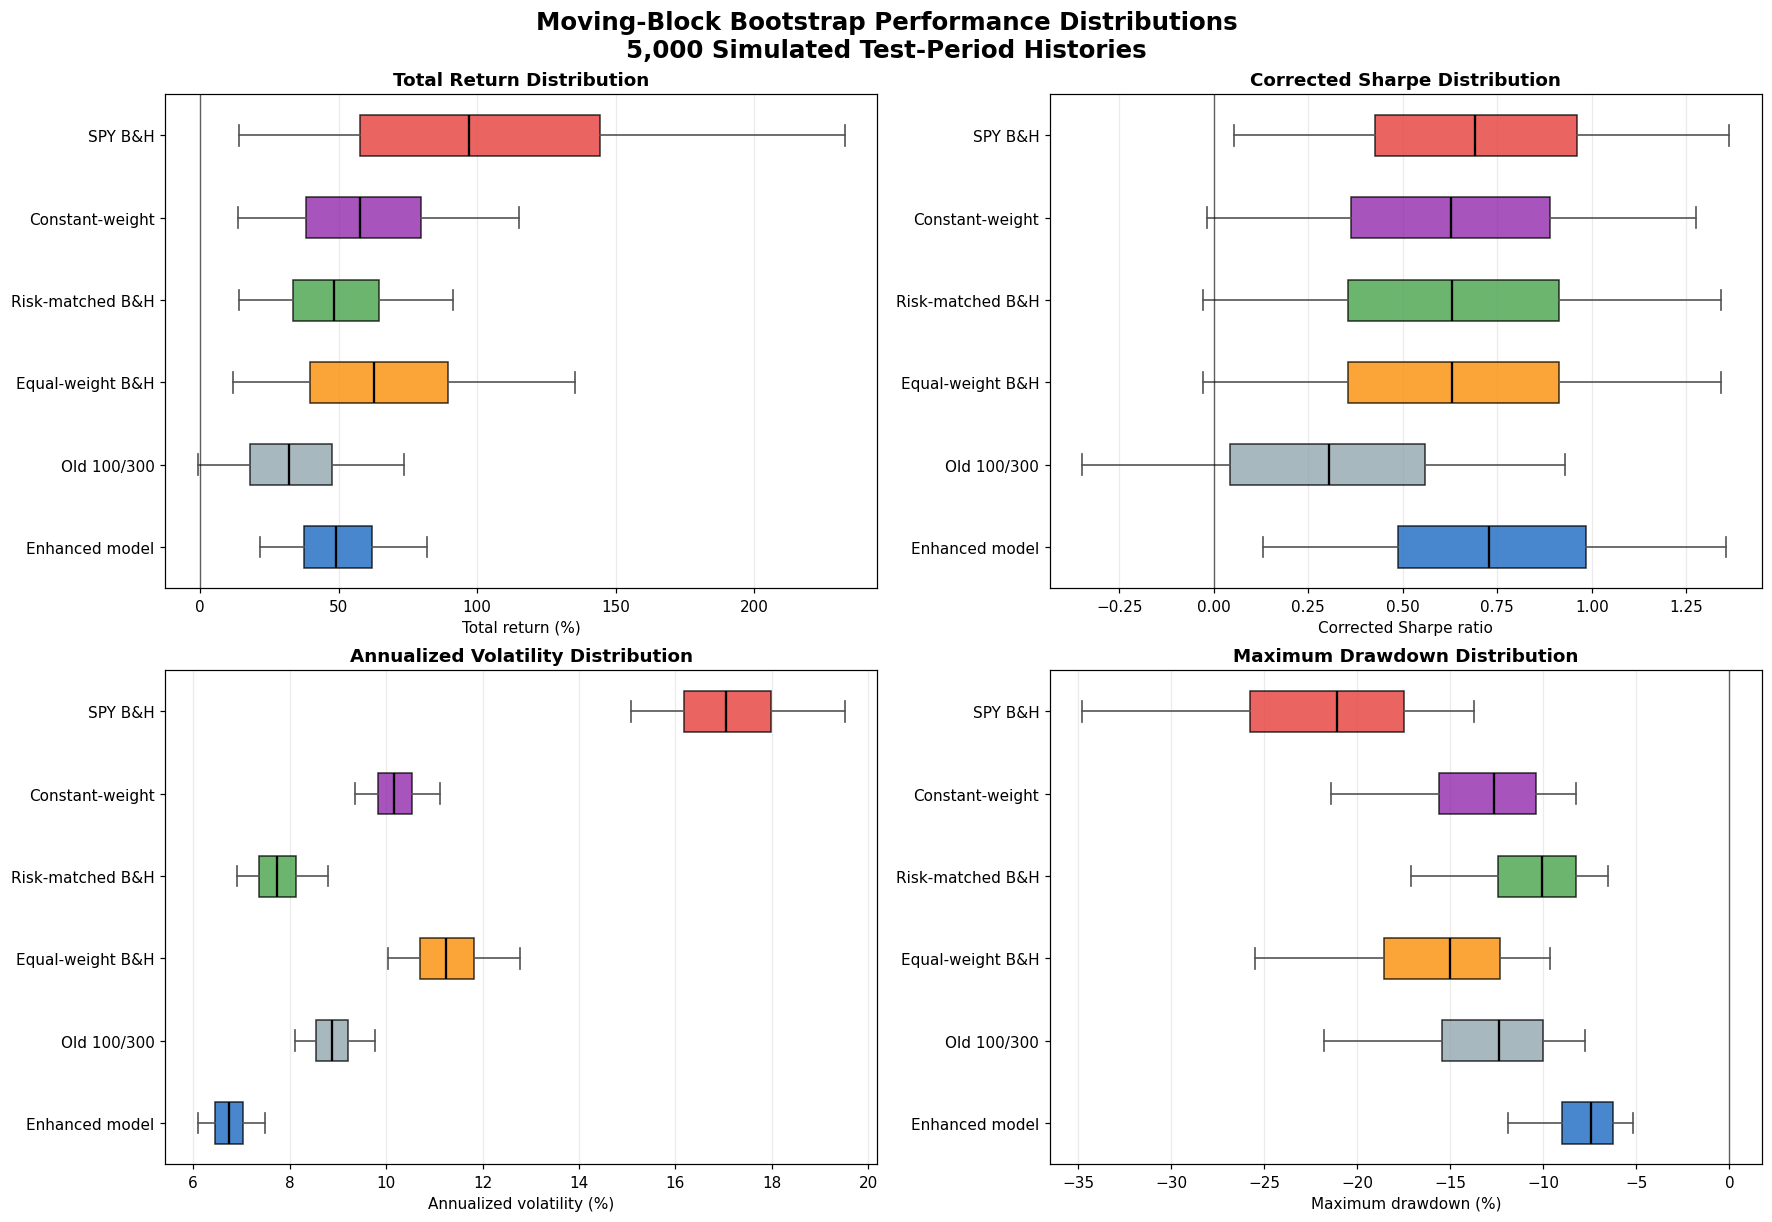

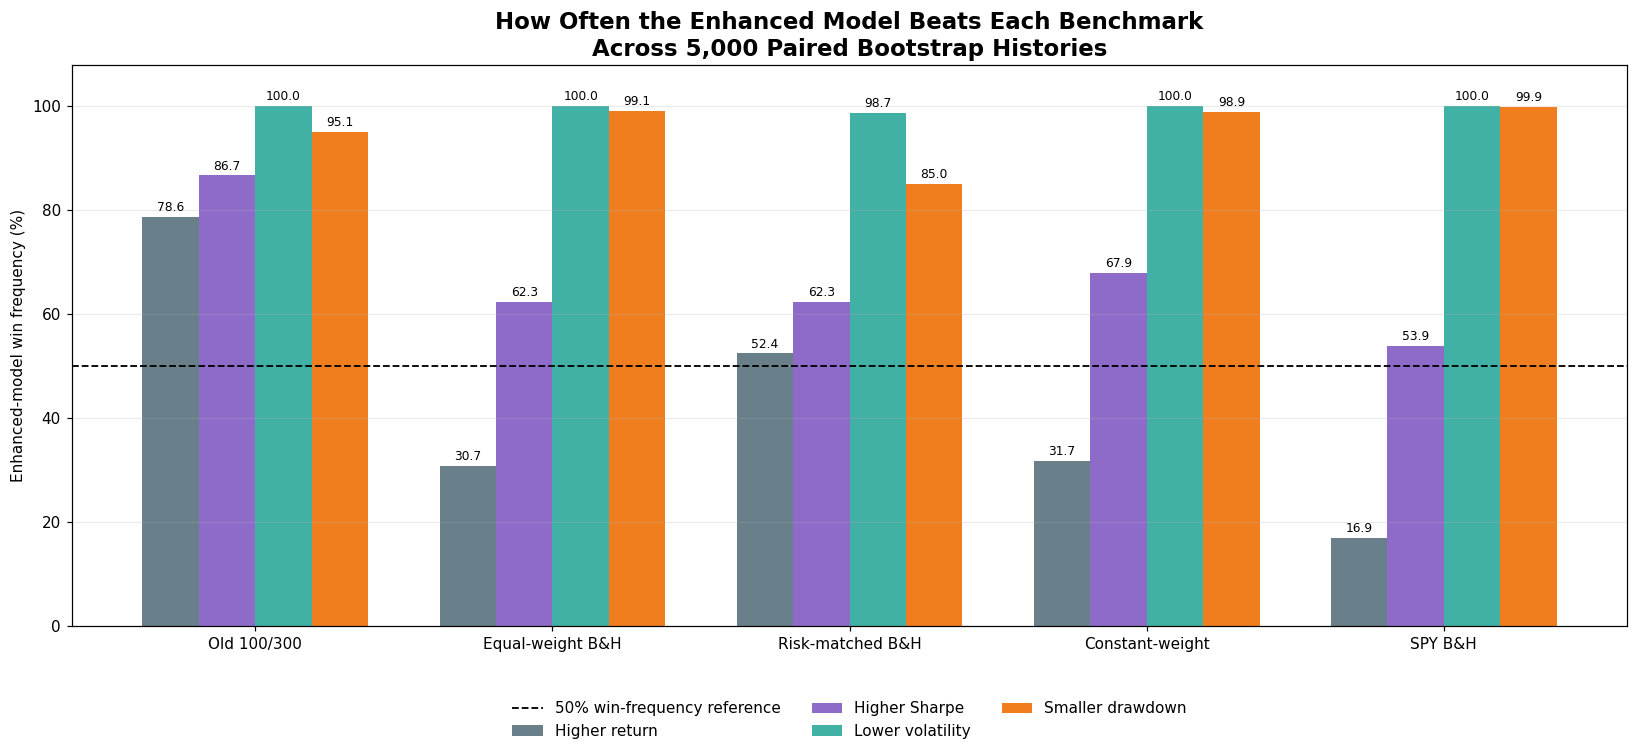

In [149]:
# Step 26B-6
# Visualise bootstrap distributions and paired win probabilities

import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# 1. Consistent strategy labels and colours
# ------------------------------------------------------------

step_26b_short_labels = {
    "Enhanced multi-horizon model": "Enhanced model",
    "Old 100/300 trend": "Old 100/300",
    "True equal-weight buy-and-hold": "Equal-weight B&H",
    "Risk-matched buy-and-hold": "Risk-matched B&H",
    "Constant-weight gross reference": "Constant-weight",
    "SPY buy-and-hold": "SPY B&H",
}

step_26b_strategy_colours = {
    "Enhanced multi-horizon model": "#1565C0",
    "Old 100/300 trend": "#90A4AE",
    "True equal-weight buy-and-hold": "#FB8C00",
    "Risk-matched buy-and-hold": "#43A047",
    "Constant-weight gross reference": "#8E24AA",
    "SPY buy-and-hold": "#E53935",
}


# ------------------------------------------------------------
# 2. Distribution boxplots
# ------------------------------------------------------------

step_26b_plot_metrics = [
    "Total return (%)",
    "Corrected Sharpe ratio",
    "Annualized volatility (%)",
    "Maximum drawdown (%)",
]

step_26b_plot_titles = [
    "Total Return Distribution",
    "Corrected Sharpe Distribution",
    "Annualized Volatility Distribution",
    "Maximum Drawdown Distribution",
]

figure_1, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11),
    constrained_layout=True,
)

for axis, metric, title in zip(
    axes.flatten(),
    step_26b_plot_metrics,
    step_26b_plot_titles,
):
    metric_data = [
        step_26b_wide_metrics[metric][strategy].to_numpy()
        for strategy in step_26b_strategy_columns
    ]

    boxplot = axis.boxplot(
        metric_data,
        orientation="horizontal",
        whis=(5, 95),
        showfliers=False,
        patch_artist=True,
        medianprops={
            "color": "black",
            "linewidth": 1.5,
        },
        whiskerprops={
            "color": "#555555",
            "linewidth": 1.1,
        },
        capprops={
            "color": "#555555",
            "linewidth": 1.1,
        },
    )

    for box, strategy in zip(
        boxplot["boxes"],
        step_26b_strategy_columns,
    ):
        box.set_facecolor(
            step_26b_strategy_colours[strategy]
        )
        box.set_alpha(0.78)

    axis.set_yticks(
        np.arange(
            1,
            len(step_26b_strategy_columns) + 1,
        )
    )

    axis.set_yticklabels(
        [
            step_26b_short_labels[strategy]
            for strategy in step_26b_strategy_columns
        ]
    )

    axis.set_title(
        title,
        fontsize=12,
        fontweight="bold",
    )

    axis.set_xlabel(metric)
    axis.grid(
        axis="x",
        alpha=0.25,
    )

    if metric in [
        "Total return (%)",
        "Corrected Sharpe ratio",
        "Maximum drawdown (%)",
    ]:
        axis.axvline(
            0,
            color="black",
            linewidth=0.9,
            alpha=0.6,
        )


figure_1.suptitle(
    "Moving-Block Bootstrap Performance Distributions\n"
    "5,000 Simulated Test-Period Histories",
    fontsize=16,
    fontweight="bold",
)

plt.show()


# ------------------------------------------------------------
# 3. Enhanced-model paired win probabilities
# ------------------------------------------------------------

step_26b_probability_plot_columns = [
    "Higher total return (%)",
    "Higher corrected Sharpe (%)",
    "Lower annualized volatility (%)",
    "Smaller maximum drawdown (%)",
]

step_26b_probability_plot_labels = [
    "Higher return",
    "Higher Sharpe",
    "Lower volatility",
    "Smaller drawdown",
]

step_26b_probability_plot_colours = [
    "#546E7A",
    "#7E57C2",
    "#26A69A",
    "#EF6C00",
]

step_26b_benchmark_short_labels = [
    step_26b_short_labels[benchmark]
    for benchmark in step_26b_benchmark_names
]

x_positions = np.arange(
    len(step_26b_benchmark_names)
)

bar_width = 0.19

figure_2, axis = plt.subplots(
    figsize=(15, 7)
)

for metric_number, (
    metric,
    label,
    colour,
) in enumerate(
    zip(
        step_26b_probability_plot_columns,
        step_26b_probability_plot_labels,
        step_26b_probability_plot_colours,
    )
):
    offsets = (
        metric_number - 1.5
    ) * bar_width

    bars = axis.bar(
        x_positions + offsets,
        step_26b_pairwise_probabilities[
            metric
        ].to_numpy(),
        width=bar_width,
        label=label,
        color=colour,
        alpha=0.88,
    )

    axis.bar_label(
        bars,
        fmt="%.1f",
        padding=2,
        fontsize=8,
    )


axis.axhline(
    50,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="50% win-frequency reference",
)

axis.set_xticks(x_positions)
axis.set_xticklabels(
    step_26b_benchmark_short_labels
)

axis.set_ylim(0, 108)

axis.set_ylabel(
    "Enhanced-model win frequency (%)"
)

axis.set_title(
    "How Often the Enhanced Model Beats Each Benchmark\n"
    "Across 5,000 Paired Bootstrap Histories",
    fontsize=15,
    fontweight="bold",
)

axis.grid(
    axis="y",
    alpha=0.25,
)

axis.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.11),
    ncol=3,
    frameon=False,
)

figure_2.tight_layout()
plt.show()

<a id="step-26b-6"></a>

#### Step 26B.6 — Interpret the Monte Carlo results and limitations

This section performed a 5,000-path Monte Carlo simulation using a non-parametric
moving-block bootstrap.

Each simulation constructed a synthetic 1,255-trading-observation test history by randomly selecting
20-trading-day blocks from the observed 2021–2025 test period. All six strategies and
the daily risk-free return were resampled jointly so that every strategy experienced
the same synthetic market sequence.

The simulation therefore assessed whether the original performance conclusions were
robust to alternative arrangements and repetitions of the observed market episodes.

##### Absolute robustness of the enhanced model

The enhanced multi-horizon model produced the following saved bootstrap distribution after rerunning the corrected metric engines and all 5,000 simulations. Every Sharpe statistic and Sharpe win frequency below uses the mean and sample standard deviation of daily excess returns, consistently with Step 25B.1 and Step 26A:

| Metric | 5th percentile | Median | 95th percentile |
|---|---:|---:|---:|
| Total return | 21.636% | 48.887% | 82.000% |
| CAGR | 4.011% | 8.320% | 12.777% |
| Annualised volatility | 6.097% | 6.736% | 7.495% |
| Corrected Sharpe ratio | 0.131 | 0.728 | 1.356 |
| Maximum drawdown | -11.916% | -7.450% | -5.161% |

The enhanced model earned a positive total return in 99.9% of the simulated histories
and produced a positive corrected Sharpe ratio in 97.5%.

Its maximum drawdown remained no worse than -10% in 84.9% of simulations.

The original test-period results were also close to the bootstrap medians. The original
total return of 48.739% was close to the bootstrap median of 48.887%, while the original
corrected Sharpe ratio of 0.726 was close to the bootstrap median of 0.728.

The observed values are near the centre of this sample-derived distribution. That is a descriptive result and does not independently demonstrate absence of overfitting: the bootstrap itself is built from the observed test returns.

##### Comparison with the old 100/300 trend model

The enhanced model produced a higher total return than the old 100/300 trend model in
78.6% of simulations and a higher corrected Sharpe ratio in 86.7%.

It also produced lower volatility in 100.0% of simulations and a smaller maximum
drawdown in 95.1%.

The median paired improvements were:

- 17.100 percentage points in total return;
- 0.439 in corrected Sharpe ratio;
- 2.135 percentage points in annualised volatility;
- 4.622 percentage points in maximum drawdown.

Within these resampled histories, the complete enhanced design usually improves on the old specification. Because the designs also differ in long/short constraints, weighting and cash treatment, this comparison cannot attribute the improvement solely to combining trend horizons.

##### Comparison with true equal-weight buy-and-hold

The enhanced model beat true equal-weight buy-and-hold on total return in only 30.7%
of simulations. Its median total-return disadvantage was 13.615 percentage points.

However, it produced a higher corrected Sharpe ratio in 62.3% of simulations, lower
volatility in 100.0%, and a smaller maximum drawdown in 99.1%.

Its median volatility reduction was 4.534 percentage points and its median drawdown
improvement was 7.361 percentage points.

The enhanced strategy therefore sacrificed some passive-market upside in exchange for
substantially stronger downside protection.

##### Comparison with risk-matched buy-and-hold

This bootstrap uses the fixed Step 25 risk-matched benchmark. Its multiplier, approximately 0.688, was estimated from development data and held constant for the test period. It does not use the annually recalibrated benchmark from Step 26A, and its realised test volatility is not identical to the enhanced model’s.

Against this benchmark, the enhanced model achieved:

- higher total return in 52.4% of simulations;
- higher corrected Sharpe ratio in 62.3%;
- lower volatility in 98.7%;
- smaller maximum drawdown in 85.0%.

Its median paired advantages were:

- 1.159 percentage points in total return;
- 0.100 in corrected Sharpe ratio;
- 1.018 percentage points in volatility reduction;
- 2.462 percentage points in drawdown improvement.

The 52.4% return-win frequency is only marginally above an equal-win result and should
not be interpreted as strong evidence of return alpha. The volatility and drawdown
advantages are considerably more consistent.

##### Comparison with constant-weight exposure

The enhanced model produced a higher total return than the constant-weight gross
reference in 31.7% of simulations, but a higher corrected Sharpe ratio in 67.9%.

It produced lower volatility in 100.0% of simulations and a smaller maximum drawdown
in 98.9%.

This supports a defensive interpretation of the complete enhanced allocation. The comparison changes trend filtering, asset weights, cash exposure and cost treatment together, so it does not isolate the effect of the trend filters alone.

##### Comparison with SPY buy-and-hold

The enhanced model beat SPY on total return in only 16.9% of simulations. Its median
total-return disadvantage was 48.132 percentage points.

Its corrected-Sharpe win frequency was 53.9%, which is too close to 50% to support a
strong claim of risk-adjusted dominance.

Nevertheless, the enhanced model produced lower volatility in 100.0% of simulations
and a smaller maximum drawdown in 99.9%. Its median volatility reduction was 10.340
percentage points and its median drawdown improvement was 13.360 percentage points.

The enhanced model should therefore not be presented as a reliable method for beating
the equity market. Its advantage over SPY was overwhelmingly defensive.

##### Overall bootstrap verdict

The Monte Carlo moving-block bootstrap supports four main conclusions:

1. The enhanced model's positive test-period performance was reasonably stable across
   alternative sequences of the observed market blocks.
2. The enhanced model represented a clear improvement over the old 100/300 trend
   strategy.
3. Its volatility and maximum-drawdown advantages were considerably more robust than
   its total-return advantages.
4. Its clearest observed benefit is lower volatility and shallower drawdowns, with no guarantee of capital preservation or reliable passive-market outperformance.

The enhanced model is therefore best described as a risk-managed multi-asset momentum
strategy rather than an alpha-maximising trading system.

##### Limitations

The bootstrap resampled only market conditions observed during 2021–2025. It cannot
generate genuinely unprecedented crises, structural breaks or future relationships
absent from that period.

The 5,000 simulations increase the precision with which the empirical resampling
distribution is measured, but they do not create 5,000 independent historical
datasets.

The simulation also resampled realised strategy-return blocks rather than generating
synthetic asset-price paths and reconstructing every trend signal. Strategy behaviour
was preserved within each block, but portfolio state could change discontinuously at
block boundaries.

Finally, the 20-day block length is a modelling choice. It preserves approximately one
month of local dependence but cannot capture every possible timescale of serial
dependence.

The results describe robustness to resampling the observed test-period blocks. They do not establish guaranteed future win probabilities or the behaviour of a fully reconstructed strategy in unseen markets.

The enhanced model includes price-drift rebalancing and funds its trading fees internally. Execution still uses simplified daily adjusted-price returns, without explicit next-open fills or market impact. The old long/short prototype retains target-weight-change turnover and simplified funding. The fixed risk-matched blend has no separate rebalancing charge, and the constant-weight reference is gross. These benchmark conventions and the cash-rate proxy remain limitations.
